<div align="center">
  <h1><b>Proyecto: Pronóstico de Ventas Reales del Comercio Minorista en Colombia</b></h1>
</div>

---

**🎓 Institución:** Universidad Central | Maestría en Analítica de Datos  
**📚 Curso:** Series de Tiempo (Periodo 2026-2)  
**👨‍💻 Autores:** Jhon J. Ballen, David F. Orjuela, Néstor O. Vásquez  
**🌐 Repositorio:** [Series_Tal2026](https://github.com/nvasquezc/Series_Tal2026)  

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nvasquezc/Series_Tal2026/blob/main/notebooks/00_contexto_y_datos.ipynb) 
[![Python](https://img.shields.io/badge/Python-3.12-blue?logo=python&logoColor=white)](https://www.python.org/) 
[![Pandas](https://img.shields.io/badge/Pandas-Data_Wrangling-150458?logo=pandas&logoColor=white)](https://pandas.pydata.org/)

---
### 1. Contexto del problema colombiano

<div align="justify">
<p>
El comercio minorista concentra buena parte de sus ventas en la temporada de fin de año: en la serie, diciembre se ubica cerca de 29 % por encima del mes promedio. Comerciantes, bancos, transportadores y el propio Gobierno planean inventarios, contratación temporal, crédito y recaudo de IVA con base en esa expectativa. El DANE mide el fenómeno cada mes con la Encuesta Mensual de Comercio (EMC). La serie registra además hechos reconocibles: el confinamiento de abril de 2020 (caída anual de 39 %), los días sin IVA de 2020 a 2022, el auge del consumo de 2021–2022 y la desaceleración de 2023 por inflación y tasas de interés altas.
</p>
</div>

---
### 2. Objetivo general

<div align="justify">
Construir, comparar y validar modelos de pronóstico para el índice mensual de ventas reales del comercio minorista en Colombia, y producir un pronóstico a 12 meses con su intervalo de incertidumbre, justificando la elección del modelo.
</div> 

---
### 3. Datos

<div align="justify">
  <p>
    <b>Fuente:</b> DANE, Encuesta Mensual de Comercio (EMC), anexo «Series índices empalmados», hoja 1.2, columna «Total comercio minorista sin otros vehículos».
  </p>
  <ul>
    <li>
      <b>Página oficial:</b> <a href="https://www.dane.gov.co/index.php/estadisticas-por-tema/comercio-interno/encuesta-mensual-de-comercio-emc" target="_blank">Encuesta Mensual de Comercio - DANE</a>
    </li>
    <li>
      <b>Descarga directa (xlsx, julio de 2026):</b> <a href="https://www.dane.gov.co/files/operaciones/EMC/anex-EMC-SeriesIndiceEmpalmados-jul2026.xlsx" target="_blank">anex-EMC-SeriesIndiceEmpalmados-jul2026.xlsx</a>
    </li>
  </ul>
  <p>
    El DANE publica un archivo nuevo cada mes; el nombre cambia solo en el sufijo del mes.
  </p>
  <p>
<p>
<b>Naturaleza de los datos:</b> La serie histórica de este anexo tiene frecuencia mensual y se presenta como un índice real (base 2019=100). En este formato, el promedio de ventas de 2019 sirve como punto de referencia estándar (100): un valor de 105, por ejemplo, indica un crecimiento del 5 % respecto a ese año, mientras que una cifra inferior a 100 refleja una contracción. Al tratarse de un índice «real», el efecto de la inflación ya está descontado, lo que permite medir la verdadera evolución del volumen de ventas. Además, por ser una «serie empalmada», el DANE ha homologado estadísticamente los cambios metodológicos del pasado para entregar un registro continuo y consistente, ideal para el análisis estacional y el entrenamiento de modelos predictivos (<i>time-series forecasting</i>).
</p>
</div>


In [1]:
# ============================================================
# Librerías y módulos del proyecto
# ============================================================

# --- Sistema y utilidades ---
import warnings
import logging
import itertools
from pathlib import Path

import requests                                   # descarga del archivo del DANE

# --- Datos y cálculo ---
import numpy as np
import pandas as pd
from scipy import stats                           # Box-Cox, Q-Q, distribuciones

# --- Gráficas ---
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

# --- Exploración de la serie ---
from statsmodels.tsa.seasonal import seasonal_decompose      # descomposición clásica
from statsmodels.tsa.stattools import acf, pacf              # autocorrelaciones
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# --- Pruebas de raíz unitaria (estacionariedad) ---
from arch.unitroot import ADF, KPSS, PhillipsPerron

# --- Modelos ---
from statsmodels.tsa.holtwinters import ExponentialSmoothing          # Holt-Winters
from statsmodels.tsa.exponential_smoothing.ets import ETSModel        # Holt-Winters con intervalos
from statsmodels.tsa.statespace.sarimax import SARIMAX                # SARIMA / SARIMAX
from prophet import Prophet                                           # Prophet

# --- Diagnóstico de residuos ---
from statsmodels.stats.diagnostic import acorr_ljungbox              # Ljung-Box
from statsmodels.stats.stattools import jarque_bera                   # normalidad

# --- Presentación en el cuaderno ---
from IPython.display import display, Markdown

# ============================================================
# Configuración general
# ============================================================
warnings.filterwarnings("ignore")                                    # avisos de convergencia y formato
for nombre in ("cmdstanpy", "prophet", "kaleido", "choreographer"):  # silencia los logs de Prophet y kaleido
    logging.getLogger(nombre).setLevel(logging.CRITICAL)

pd.set_option("display.float_format", "{:.3f}".format)               # 3 decimales en tablas
pd.set_option("display.max_columns", 30)
pio.templates.default = "simple_white"                               # estilo base de las gráficas
np.random.seed(2026)                                                 # reproducibilidad (Prophet, simulaciones)

print("Librerías cargadas correctamente")

Librerías cargadas correctamente


In [2]:
VINTAGE = "jul2026"
URL = f"https://www.dane.gov.co/files/operaciones/EMC/anex-EMC-SeriesIndiceEmpalmados-{VINTAGE}.xlsx"

RAIZ = Path.cwd().parent         
DIR_RAW = RAIZ / "data" / "raw"
DIR_RAW.mkdir(parents=True, exist_ok=True)
ARCHIVO = DIR_RAW / f"anex-EMC-SeriesIndiceEmpalmados-{VINTAGE}.xlsx"

if ARCHIVO.exists():
    print("Ya existe, no se descarga:", ARCHIVO.name)
else:
    r = requests.get(URL, timeout=60, headers={"User-Agent": "Mozilla/5.0"})
    r.raise_for_status()
    ARCHIVO.write_bytes(r.content)
    print("Descargado:", ARCHIVO.name)
    
print(f"Tamaño: {ARCHIVO.stat().st_size / 1024:.0f} KB")

Ya existe, no se descarga: anex-EMC-SeriesIndiceEmpalmados-jul2026.xlsx
Tamaño: 276 KB


In [3]:
crudo = pd.read_excel(ARCHIVO, sheet_name="1.2", header=None)
print("Dimensiones:", crudo.shape)
crudo.iloc[:10, :6]  

Dimensiones: (178, 23)


,0,1,2,3,4,5
0,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,Encuesta Mensual de Comercio - EMC,NaN,NaN,NaN,NaN
2,NaN,1.2 Índices empalmados de las ventas en valore...,NaN,NaN,NaN,NaN
3,NaN,Base 2019 = 100,NaN,NaN,NaN,NaN
4,NaN,(Enero 2013 - julio 2026)p,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,Año,Mes,Total comercio minorista sin otros vehículos,Total comercio minorista sin vehículos,Total comercio minorista sin otros vehículos y...
7,NaN,2013,Enero,73.126,73.141,70.564
8,NaN,NaN,Febrero,70.379,68.059,68.379
9,NaN,NaN,Marzo,74.945,73.354,73.694


In [4]:
crudo.iloc[-8:, :4]

,0,1,2,3
170,NaN,NaN,NaN,NaN
171,NaN,NaN,NaN,NaN
172,NaN,Fuente: DANE - EMC,NaN,NaN
173,NaN,p provisional: como parte del proceso de produ...,NaN,NaN
174,NaN,*Las series de ventas empalmadas corresponden ...,NaN,NaN
175,NaN,La información generada en la EMC incluye tant...,NaN,NaN
176,NaN,Como parte del proceso de producción estadísti...,NaN,NaN
177,NaN,Actualizado el 16 de septiembre de 2026,NaN,NaN


__Limpiar y construir la serie mensual__

1. Ubicar la fila de encabezado y las columnas Año, Mes y la variable.
2. Quedarse solo con las filas que son meses.
3. Rellenar el año hacia abajo (el DANE solo lo escribe en enero).
4. Construir la fecha y dejarla como índice con frecuencia mensual.

In [5]:
## 1. Ubicar la fila de encabezado y las columnas Año, Mes y la variable.

COLUMNA = "Total comercio minorista sin otros vehículos"

# Fila de encabezado = la que contiene la celda "Año"
fila_enc = crudo.index[crudo.apply(lambda f: f.astype(str).str.strip().eq("Año").any(), axis=1)][0]
encabezado = crudo.loc[fila_enc].astype(str).str.strip()

col_anio = encabezado[encabezado == "Año"].index[0]
col_mes  = encabezado[encabezado == "Mes"].index[0]
col_val  = encabezado[encabezado == COLUMNA].index[0]
print(f"Encabezado en la fila {fila_enc} | columnas: Año={col_anio}, Mes={col_mes}, valor={col_val}")

Encabezado en la fila 6 | columnas: Año=1, Mes=2, valor=3


In [6]:
## 2. Quedarse solo con las filas que son meses.
    
MESES = {"enero": 1, "febrero": 2, "marzo": 3, "abril": 4, "mayo": 5, "junio": 6,
         "julio": 7, "agosto": 8, "septiembre": 9, "octubre": 10, "noviembre": 11, "diciembre": 12}

df = crudo.loc[fila_enc + 1:, [col_anio, col_mes, col_val]].copy()
df.columns = ["anio", "mes", "valor"]
df["mes"] = df["mes"].astype(str).str.strip().str.lower()
df = df[df["mes"].isin(MESES)]          # elimina títulos, vacíos y notas al pie
print("Filas de datos:", len(df))
df.head(14)

Filas de datos: 163


,anio,mes,valor
7,2013,enero,73.126
8,NaN,febrero,70.379
9,NaN,marzo,74.945
10,NaN,abril,74.325
11,NaN,mayo,76.374
12,NaN,junio,76.462
13,NaN,julio,80.724
14,NaN,agosto,78.422
15,NaN,septiembre,75.932
16,NaN,octubre,78.748


In [7]:
## 3. Rellenar el año hacia abajo (el DANE solo lo escribe en enero).
## 4. Construir la fecha y dejarla como índice con frecuencia mensual.

df["anio"] = pd.to_numeric(df["anio"], errors="coerce").ffill().astype(int)   # año solo en enero → se propaga
df["fecha"] = pd.to_datetime(dict(year=df["anio"], month=df["mes"].map(MESES), day=1))

y = (pd.Series(pd.to_numeric(df["valor"]).values, index=df["fecha"], name="ventas_reales")
       .asfreq("MS"))                                  # frecuencia mensual explícita
y.head()

fecha
2013-01-01   73.126
2013-02-01   70.379
2013-03-01   74.945
2013-04-01   74.325
2013-05-01   76.374
Freq: MS, Name: ventas_reales, dtype: float64

In [8]:
esperado = pd.date_range("2013-01-01", "2026-07-01", freq="MS")
print("Meses:", len(y), "| desde", y.index.min().date(), "hasta", y.index.max().date())
print("Faltantes:", y.isna().sum(), "| duplicados:", y.index.duplicated().sum(),
      "| todos > 0:", (y > 0).all(), "| cobertura completa:", y.index.equals(esperado))

DIR_PROC = RAIZ / "data" / "processed"
DIR_PROC.mkdir(parents=True, exist_ok=True)
y.to_csv(DIR_PROC / f"ventas_reales_minorista_{VINTAGE}.csv", index_label="fecha")

Meses: 163 | desde 2013-01-01 hasta 2026-07-01
Faltantes: 0 | duplicados: 0 | todos > 0: True | cobertura completa: True


---
### 4. Modelos a utilizar

<div align="justify">
  <ul>
    <li><b>SARIMA $(p, d, q)(P, D, Q)_{12}$:</b> modelo autorregresivo integrado de media móvil con componente estacional.</li>
    <li><b>Prophet:</b> modelo para capturar tendencia y estacionalidad.</li>
    <li><b>Suavizamiento exponencial / Holt-Winters:</b> modelo basado en nivel, tendencia y estacionalidad.</li>
    <li><b>Naive estacional:</b> modelo de referencia para comparar el desempeño de los demás modelos.</li>
  </ul>
</div>

---
### 5. Proceso de pronóstico

<div align="justify">

1. **Exploración general:** graficar la serie e identificar tendencia, estacionalidad, cambios estructurales y valores atípicos.

2. **Preparación de los datos:** organizar la serie mensual, verificar datos faltantes y dividir la información en:
   - **Entrenamiento:** enero de 2013 a julio de 2025.
   - **Prueba:** agosto de 2025 a julio de 2026.

3. **Modelo ingenuo estacional:** construir un modelo de referencia utilizando como pronóstico el valor observado en el mismo mes del año anterior:
$$ \hat{Y}_t = Y_{t-12} $$

4. **Modelo SARIMA:** analizar la estacionariedad, aplicar la prueba ADF y revisar las funciones ACF y PACF para orientar la selección de los parámetros del modelo.

5. **Modelo Holt-Winters:** evaluar los componentes de nivel, tendencia y estacionalidad, y ajustar la estructura aditiva o multiplicativa según corresponda.

6. **Modelo Prophet:** ajustar el modelo considerando tendencia, estacionalidad y posibles puntos de cambio en la serie.

7. **Pronóstico de prueba:** generar predicciones con el modelo ingenuo estacional, SARIMA, Holt-Winters y Prophet para el periodo agosto de 2025 a julio de 2026.

8. **Evaluación:** comparar el desempeño de SARIMA, Holt-Winters y Prophet frente al modelo ingenuo estacional mediante MAE, RMSE, MAPE y MASE, verificando si los modelos más complejos mejoran realmente la capacidad predictiva respecto al modelo de referencia.

9. **Diagnóstico:** revisar los residuos del modelo SARIMA y analizar de manera general el comportamiento de los errores de los modelos ajustados.

10. **Pronóstico final:** reajustar el modelo con mejor desempeño utilizando toda la información disponible hasta julio de 2026 y proyectar los siguientes 12 meses.

</div>

### __00. Variable, unidad, frecuencia y horizonte__

| Elemento | Definición |
|---|---|
| Variable $Y_t$ | Índice de ventas **reales** — Total comercio minorista sin otros vehículos |
| Unidad | Índice adimensional, **base 2019 = 100** |
| Frecuencia | Mensual ($s = 12$ observaciones por ciclo estacional) |
| Cobertura | Enero 2013 – julio 2026 (163 meses, versión de julio 2026) |
| Horizonte | $h = 1, 2, \dots, 12$ meses (agosto 2026 – julio 2027) |
| Partición | Entrenamiento ene-2013 a jul-2025 (151 meses) · Prueba ago-2025 a jul-2026 (12 meses) |

**Notación usada en todo el proyecto**
- $t$: índice del mes ($t = 1$ es enero de 2013).
- $Y_t$: valor observado del índice en el mes $t$.
- $\hat{Y}_{t+h|t}$: pronóstico hecho con información hasta el mes $t$, para $h$ meses adelante.
- $s = 12$: periodo estacional.

---

### __1. Exploración general: graficar la serie e identificar tendencia, estacionalidad, cambios estructurales y valores atípicos.__

In [9]:
# --- Carpeta y función para guardar figuras ---
import kaleido

DIR_FIG = RAIZ / "reports" / "figures"
DIR_FIG.mkdir(parents=True, exist_ok=True)

# Un solo Chrome para toda la sesión: evita abrir y matar uno por cada figura (falla en Windows)
try:
    kaleido.start_sync_server()
except Exception as e:
    print("Servidor de kaleido ya activo o no disponible:", type(e).__name__)

def guardar_figura(fig, nombre, escala=3):
    """Guarda la figura como HTML (interactiva) y PNG (alta resolución, para el informe)."""
    fig.write_html(DIR_FIG / f"{nombre}.html", include_plotlyjs="cdn")   # siempre funciona
    try:
        fig.write_image(DIR_FIG / f"{nombre}.png", scale=escala)
        print("Guardada:", (DIR_FIG / f"{nombre}.png").relative_to(RAIZ))
    except Exception as e:
        print(f"PNG no guardado ({type(e).__name__}); quedó el HTML: {nombre}.html")

Guardada: reports\figures\00_serie_componentes.png


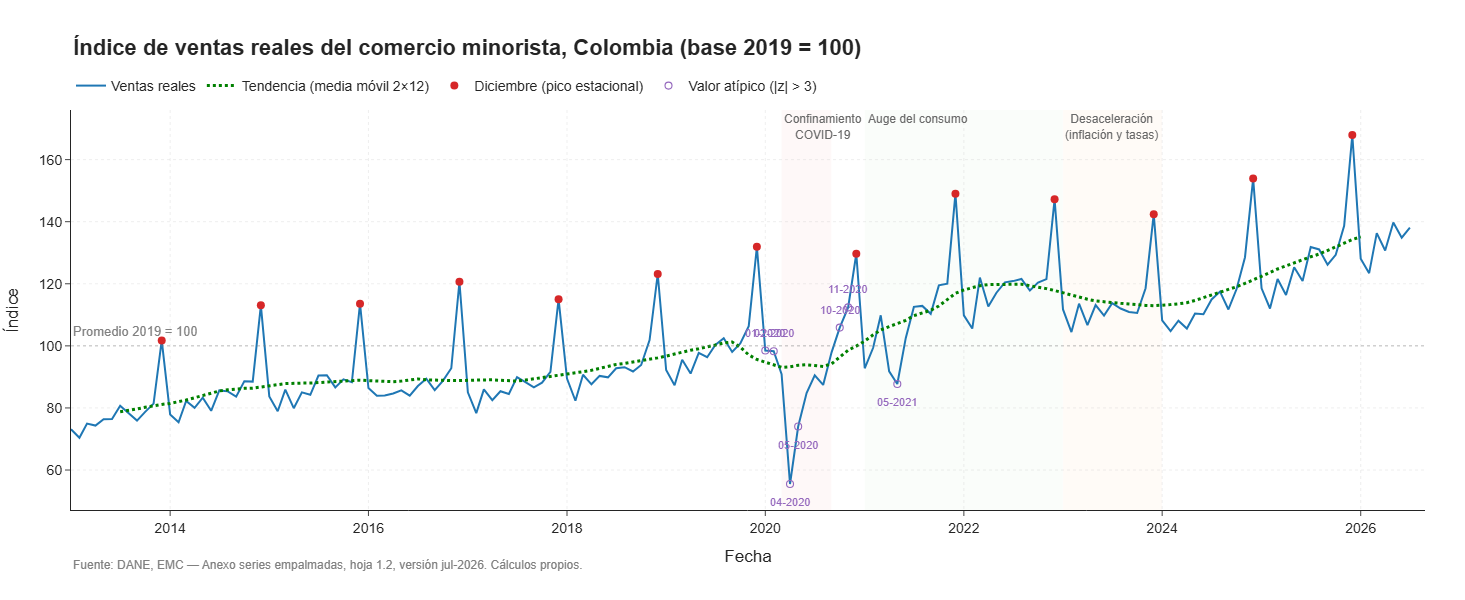

In [26]:
# ============================================================
# 1. Cálculos
# ============================================================

# Tendencia: media móvil centrada 2x12
m12 = y.rolling(12).mean()                          # promedio de los 12 meses que terminan en t
tendencia = (m12.shift(-5) + m12.shift(-6)) / 2     # centrada: cubre t-6 ... t+6 (extremos con medio peso)

# Estacionalidad: picos de diciembre
diciembres = y[y.index.month == 12]

# Valores atípicos: residuo de la descomposición multiplicativa + z robusto
desc = seasonal_decompose(y, model="multiplicative", period=12)
R = desc.resid.dropna()
z = (R - R.median()) / stats.median_abs_deviation(R, scale="normal")
atipicos = y[z[z.abs() > 3].index]

# Cambios estructurales: periodos documentados
periodos = [
    ("2020-03-01", "2020-08-01", "Confinamiento<br>COVID-19", "rgba(214,39,40,0.10)"),
    ("2021-01-01", "2022-12-01", "Auge del consumo", "rgba(44,160,44,0.08)"),
    ("2023-01-01", "2023-12-01", "Desaceleración<br>(inflación y tasas)", "rgba(255,127,14,0.10)"),
]

# ============================================================
# 2. Figura
# ============================================================
fig = go.Figure()

# Cambios estructurales (franjas sombreadas)
for ini, fin, etiqueta, color in periodos:
    fig.add_vrect(x0=pd.Timestamp(ini), x1=pd.Timestamp(fin) + pd.offsets.MonthEnd(0),
                  fillcolor=color, line_width=0, layer="below",
                  annotation_text=etiqueta, annotation_position="top left",
                  annotation_font=dict(size=12, color="dimgray"))

# Serie observada
fig.add_trace(go.Scatter(x=y.index, y=y.values, mode="lines", name="Ventas reales",
                         line=dict(color="#1f77b4", width=2)))

# Tendencia
fig.add_trace(go.Scatter(x=tendencia.index, y=tendencia.values, mode="lines",
                         name="Tendencia (media móvil 2×12)",
                         line=dict(color="green", width=3, dash="dot")))

# Estacionalidad: diciembres
fig.add_trace(go.Scatter(x=diciembres.index, y=diciembres.values, mode="markers",
                         name="Diciembre (pico estacional)",
                         marker=dict(color="#d62728", size=8)))

# Valores atípicos
fig.add_trace(go.Scatter(x=atipicos.index, y=atipicos.values, mode="markers",
                         name="Valor atípico (|z| > 3)",
                          marker=dict(symbol="circle-open", color="#9467bd", size=7, line=dict(width=1.1))))
for fecha, valor in atipicos.items():
    fig.add_annotation(x=fecha, y=valor, text=f"{fecha:%m-%Y}", showarrow=False,
                       yshift=-18 if z[fecha] < 0 else 18,
                       font=dict(size=11, color="#9467bd"))

# Referencia: promedio 2019 = 100
fig.add_hline(y=100, line_dash="dot", line_color="gray", line_width=1.5)
fig.add_annotation(text="Promedio 2019 = 100", x=y.index[0], y=101.5, showarrow=False,
                   font=dict(size=13, color="gray"), xanchor="left", yanchor="bottom")

# ============================================================
# 3. Diseño
# ============================================================
fig.update_layout(
    template="simple_white", width=1400, height=600,
    font=dict(family="Arial", size=14),
    title=dict(text="<b>Índice de ventas reales del comercio minorista, Colombia (base 2019 = 100)</b>",
               x=0.05, xanchor="left", font=dict(size=22)),
    xaxis_title="Fecha", yaxis_title="Índice",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="left", x=0),
    margin=dict(l=60, r=40, t=110, b=90),
)
fig.update_xaxes(showgrid=True, gridcolor="rgba(200,200,200,0.3)", griddash="dot")
fig.update_yaxes(showgrid=True, gridcolor="rgba(200,200,200,0.3)", griddash="dot")

fig.add_annotation(text="Fuente: DANE, EMC — Anexo series empalmadas, hoja 1.2, versión jul-2026. Cálculos propios.",
                   xref="paper", yref="paper", x=0, y=-0.16, showarrow=False,
                   font=dict(size=12, color="gray"), xanchor="left")

guardar_figura(fig, "00_serie_componentes")
fig.show()

In [12]:
# ============================================================
# 4. Resumen numérico
# ============================================================
print(f"\nNivel: {y.iloc[0]:.1f} (ene-2013) → {y.iloc[-1]:.1f} (jul-2026)")
print(f"Diciembre promedio vs. su tendencia: {100 * (y / tendencia)[y.index.month == 12].mean() - 100:+.1f} %")
display(pd.DataFrame({"Y_t": atipicos, "z robusto": z[atipicos.index]}).round(2))


Nivel: 73.1 (ene-2013) → 138.1 (jul-2026)
Diciembre promedio vs. su tendencia: +28.7 %


,Y_t,z robusto
fecha,,
2020-01-01,98.480,3.040
2020-02-01,98.250,5.020
2020-04-01,55.500,-12.130
2020-05-01,74.010,-5.910
2020-10-01,105.880,3.260
2020-11-01,112.390,3.280
2021-05-01,87.720,-4.780


### Interpretación

<li style="margin-bottom: 10px;"><b>Estacionalidad:</b> Diciembre es el pico en rojo de todos los años, cerca de un <b>29 % por encima de la tendencia</b>. El pico <b>crece a medida que sube el nivel</b> de la serie, una primera pista de estacionalidad <b>multiplicativa</b>.</li>

<li style="margin-bottom: 10px;"><b>Cambios estructurales:</b> El confinamiento de 2020 es la ruptura más fuerte; después vienen el auge de 2021–2022 y la desaceleración de 2023 por inflación y tasas de interés altas.</li>

<li style="margin-bottom: 10px;"><b>Valores atípicos:</b> el más extremo es <b>abril de 2020</b> (confinamiento), seguido de mayo de 2020 y <b>mayo de 2021</b> (paro nacional). Si aparece <b>febrero de 2020</b> como atípico positivo, es en parte un <b>artefacto</b>: la media móvil de ese mes incluye abril y mayo de 2020, que hunden la tendencia, y por eso febrero parece más alto de lo que fue.</li>


---

### __2. **Preparación de los datos:** organizar la serie mensual, verificar datos faltantes y dividir la información en:__
   - **Entrenamiento:** enero de 2013 a julio de 2025.
   - **Prueba:** agosto de 2025 a julio de 2026.

In [19]:
# Organizar la serie mensual 

y = y.sort_index().astype(float)
y.index.name = "fecha"
y = y.asfreq("MS") # frecuencia mensual 

# Verificar datos faltantes contra el calendario completo 
calendario = pd.date_range(y.index.min(), y.index.max(), freq="MS")
faltantes = calendario.difference(y.dropna().index)

verificacion = pd.DataFrame({
    "Verificación": ["Frecuencia mensual (MS)", "Orden cronológico", "Fechas duplicadas",
                     "Meses faltantes", "Valores no positivos", "Total de meses"],
    "Resultado": [y.index.freqstr, y.index.is_monotonic_increasing, int(y.index.duplicated().sum()),
                  len(faltantes), int((y <= 0).sum()), len(y)],
})
display(verificacion.style.hide(axis="index"))

if len(faltantes) > 0:
    print("Meses faltantes:", [f"{f:%Y-%m}" for f in faltantes])

Verificación,Resultado
Frecuencia mensual (MS),MS
Orden cronológico,True
Fechas duplicadas,0
Meses faltantes,0
Valores no positivos,0
Total de meses,163


In [20]:
# Partición temporal 

FIN_TRAIN = "2025-07-01"
INI_TEST, FIN_TEST = "2025-08-01", "2026-07-01"

train = y[:FIN_TRAIN]
test = y[INI_TEST:FIN_TEST]

# Controles: tamaños esperados y que no se traslapen
assert len(train) == 151, f"Entrenamiento debería tener 151 meses, tiene {len(train)}"
assert len(test) == 12, f"Prueba debería tener 12 meses, tiene {len(test)}"
assert train.index.max() < test.index.min(), "Entrenamiento y prueba se traslapan"

particion = pd.DataFrame({
    "Conjunto": ["Entrenamiento", "Prueba"],
    "Desde": [f"{train.index.min():%Y-%m}", f"{test.index.min():%Y-%m}"],
    "Hasta": [f"{train.index.max():%Y-%m}", f"{test.index.max():%Y-%m}"],
    "Meses": [len(train), len(test)],
    "% del total": [100 * len(train) / len(y), 100 * len(test) / len(y)],
    "Media": [train.mean(), test.mean()],
})
display(particion.style.hide(axis="index").format({"% del total": "{:.1f}", "Media": "{:.1f}"}))

crec = 100 * (test.mean() / train[-12:].mean() - 1)
print(f"La prueba está {crec:.1f} % por encima de los últimos 12 meses del entrenamiento.")

# Guardar los conjuntos
DIR_PROC = RAIZ / "data" / "processed"
DIR_PROC.mkdir(parents=True, exist_ok=True)
train.to_csv(DIR_PROC / "train.csv", index_label="fecha")
test.to_csv(DIR_PROC / "test.csv", index_label="fecha")

Conjunto,Desde,Hasta,Meses,% del total,Media
Entrenamiento,2013-01,2025-07,151,92.6,99.1
Prueba,2025-08,2026-07,12,7.4,135.4


La prueba está 10.0 % por encima de los últimos 12 meses del entrenamiento.


Guardada: reports\figures\00_particion.png


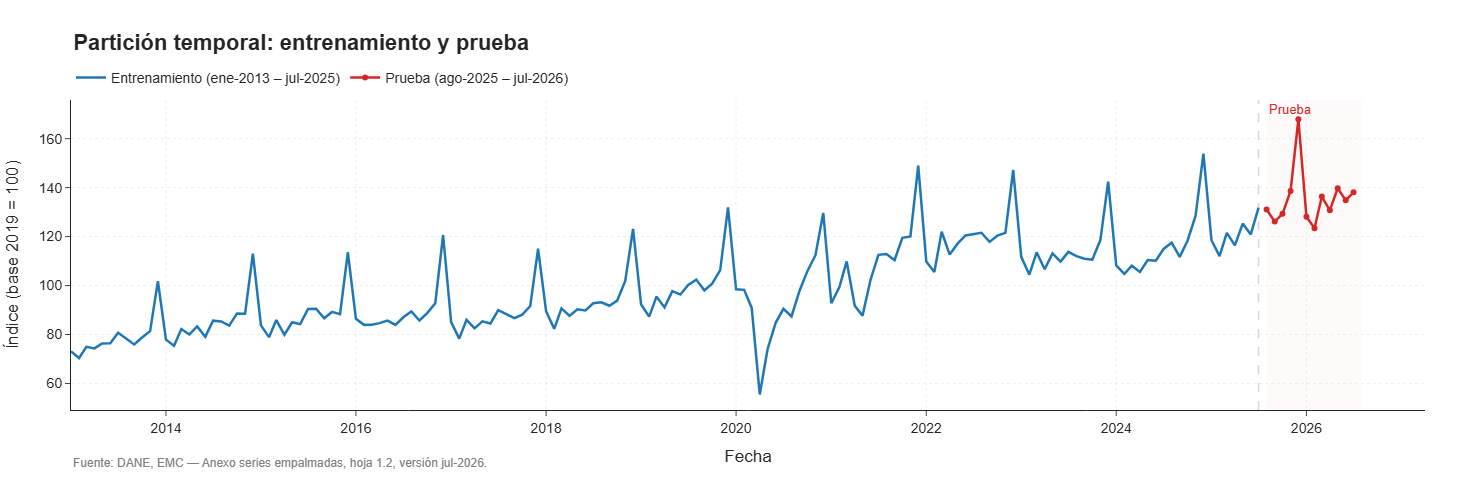

In [21]:
fig = go.Figure()

# Periodo de prueba sombreado
fig.add_vrect(x0=test.index.min(), x1=test.index.max() + pd.offsets.MonthEnd(0),
              fillcolor="rgba(214,39,40,0.08)", line_width=0, layer="below",
              annotation_text="Prueba", annotation_position="top left",
              annotation_font=dict(size=13, color="#d62728"))

fig.add_trace(go.Scatter(x=train.index, y=train.values, mode="lines", name="Entrenamiento (ene-2013 – jul-2025)",
                         line=dict(color="#1f77b4", width=2.5)))
fig.add_trace(go.Scatter(x=test.index, y=test.values, mode="lines+markers", name="Prueba (ago-2025 – jul-2026)",
                         line=dict(color="#d62728", width=2.5), marker=dict(size=6)))

# Línea de corte
fig.add_vline(x=train.index.max(), line_dash="dash", line_color="gray", line_width=1.5)

fig.update_layout(
    template="simple_white", width=1400, height=500,
    font=dict(family="Arial", size=14),
    title=dict(text="<b>Partición temporal: entrenamiento y prueba</b>",
               x=0.05, xanchor="left", font=dict(size=22)),
    xaxis_title="Fecha", yaxis_title="Índice (base 2019 = 100)",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="left", x=0),
    margin=dict(l=60, r=40, t=100, b=90),
)
fig.update_xaxes(showgrid=True, gridcolor="rgba(200,200,200,0.3)", griddash="dot")
fig.update_yaxes(showgrid=True, gridcolor="rgba(200,200,200,0.3)", griddash="dot")
fig.add_annotation(text="Fuente: DANE, EMC — Anexo series empalmadas, hoja 1.2, versión jul-2026.",
                   xref="paper", yref="paper", x=0, y=-0.2, showarrow=False,
                   font=dict(size=12, color="gray"), xanchor="left")

guardar_figura(fig, "00_particion")
fig.show()

### Lectura

- La serie está completa: **163 meses consecutivos**, sin faltantes, sin duplicados y con todos los valores positivos. No hace falta imputar, y los valores positivos permiten usar logaritmos o modelos multiplicativos.
- **Entrenamiento:** 151 meses (92,6 %). **Prueba:** 12 meses (7,4 %), exactamente el horizonte de pronóstico.
- El entrenamiento contiene todos los fenómenos difíciles (el choque de 2020, el auge, la desaceleración de 2023), así que los modelos aprenden de una historia que no es homogénea.
- **La prueba es exigente:** su promedio está cerca de **10 % por encima** de los últimos 12 meses del entrenamiento. Un modelo que no capture tendencia, como el Naïve estacional, va a subestimar.

---

### __3. **Modelo ingenuo estacional:** construir un modelo de referencia utilizando como pronóstico el valor observado en el mismo mes del año anterior:__
$$ \hat{Y}_t = Y_{t-12} $$

El pronóstico de cada mes es **el valor del mismo mes del año anterior**: agosto de 2025 se pronostica con agosto de 2024, diciembre de 2025 con diciembre de 2024, y así para los 12 meses de prueba.

- $\hat Y_t$: pronóstico del mes $t$.
- $Y_{t-12}$: valor observado 12 meses antes (periodo estacional $m = 12$).

### Por qué es la referencia

Es el pronóstico más simple que respeta la estacionalidad. Como la serie tiene un patrón anual muy regular (diciembre ≈ +29 %), copia ese patrón sin estimar ningún parámetro. **Cualquier modelo más complejo tiene que superarlo para justificarse.** Su debilidad es que **no tiene tendencia**: si la serie crece, se queda corto.

### Intervalo de predicción

Si los errores del método dentro del entrenamiento, $e_t = Y_t - Y_{t-12}$, tienen desviación estándar $\hat\sigma$, el intervalo al 95 % es

$$
\hat Y_t \pm 1{,}96\,\hat\sigma
$$

Para $h \le 12$ su ancho es constante: el método solo mira un año atrás.

### Métricas de evaluación

Con $e_t = Y_t - \hat Y_t$ en los $n = 12$ meses de prueba (**$e_t > 0$ = el modelo subestimó**):

| Métrica | Fórmula | Lectura |
|---|---|---|
| MAE | $\frac{1}{n}\sum \lvert e_t\rvert$ | Error típico, en puntos del índice |
| RMSE | $\sqrt{\frac{1}{n}\sum e_t^2}$ | Castiga más los errores grandes |
| MAPE | $\frac{100}{n}\sum \left\lvert e_t / Y_t\right\rvert$ | Error porcentual promedio |
| MASE | $\dfrac{\text{MAE}}{\frac{1}{T-12}\sum_{t=13}^{T}\lvert Y_t - Y_{t-12}\rvert}$ | < 1 = mejor que el Naïve estacional **dentro del entrenamiento** |
| Bias | $\frac{1}{n}\sum e_t$ | Sesgo: > 0 subestima, < 0 sobreestima |

El denominador del MASE se calcula una sola vez con el entrenamiento ($T = 151$) y es el mismo para todos los modelos, así que los MASE son comparables entre sí.

In [22]:
# Escala del MASE: error del Naïve estacional DENTRO del entrenamiento 

ESCALA_MASE = np.mean(np.abs(train.values[12:] - train.values[:-12]))

def metricas(real, pronostico):
    """MAE, RMSE, MAPE (%), MASE y Bias del pronóstico frente al valor real."""
    e = np.asarray(real) - np.asarray(pronostico)
    mae = np.mean(np.abs(e))
    return {"MAE": mae,
            "RMSE": np.sqrt(np.mean(e ** 2)),
            "MAPE (%)": 100 * np.mean(np.abs(e / np.asarray(real))),
            "MASE": mae / ESCALA_MASE,
            "Bias": np.mean(e)}

def cobertura(real, inferior, superior):
    """% de valores reales dentro del intervalo y ancho medio del intervalo."""
    real, inferior, superior = map(np.asarray, (real, inferior, superior))
    return {"Cobertura 95 % (%)": 100 * np.mean((real >= inferior) & (real <= superior)),
            "Ancho medio": np.mean(superior - inferior)}

print(f"Escala del MASE: {ESCALA_MASE:.3f} puntos → un modelo con MAE menor que esto tiene MASE < 1")

Escala del MASE: 7.013 puntos → un modelo con MAE menor que esto tiene MASE < 1


In [23]:
# Pronóstico: cada mes de prueba = mismo mes del año anterior
pron_naive = pd.Series(y.shift(12)[test.index].values, index=test.index, name="Naïve estacional")

# Verificación: los valores usados son los últimos 12 meses del entrenamiento (sin usar datos de prueba)
assert np.allclose(pron_naive.values, train[-12:].values)

# Intervalo de predicción al 95% 
sigma = (train - train.shift(12)).dropna().std(ddof=1)
naive = pd.DataFrame({"pronostico": pron_naive,
                      "inferior": pron_naive - 1.96 * sigma,
                      "superior": pron_naive + 1.96 * sigma})

# Tabla mes a mes
tabla_naive = naive.assign(real=test, error=test - naive["pronostico"])
tabla_naive.index = tabla_naive.index.strftime("%Y-%m")
display(tabla_naive.round(2))

# Métricas
res_naive = {**metricas(test, naive["pronostico"]),
             **cobertura(test, naive["inferior"], naive["superior"])}
display(pd.DataFrame(res_naive, index=["Naïve estacional"]).round(3))

# Guardar 
naive.to_csv(DIR_PROC / "pronostico_naive.csv", index_label="fecha")

,pronostico,inferior,superior,real,error
fecha,,,,,
2025-08,117.490,100.170,134.810,131.060,13.570
2025-09,111.720,94.400,129.030,126.130,14.420
2025-10,118.310,100.990,135.620,129.310,11.000
2025-11,128.550,111.240,145.870,138.650,10.090
2025-12,153.890,136.570,171.210,167.930,14.030
2026-01,118.520,101.200,135.830,128.100,9.580
2026-02,112.030,94.720,129.350,123.430,11.390
2026-03,121.530,104.210,138.840,136.330,14.800
2026-04,116.380,99.060,133.700,130.720,14.340


,MAE,RMSE,MAPE (%),MASE,Bias,Cobertura 95 % (%),Ancho medio
Naïve estacional,12.322,12.585,9.139,1.757,12.322,100.000,34.637


Guardada: reports\figures\00_naive_estacional.png


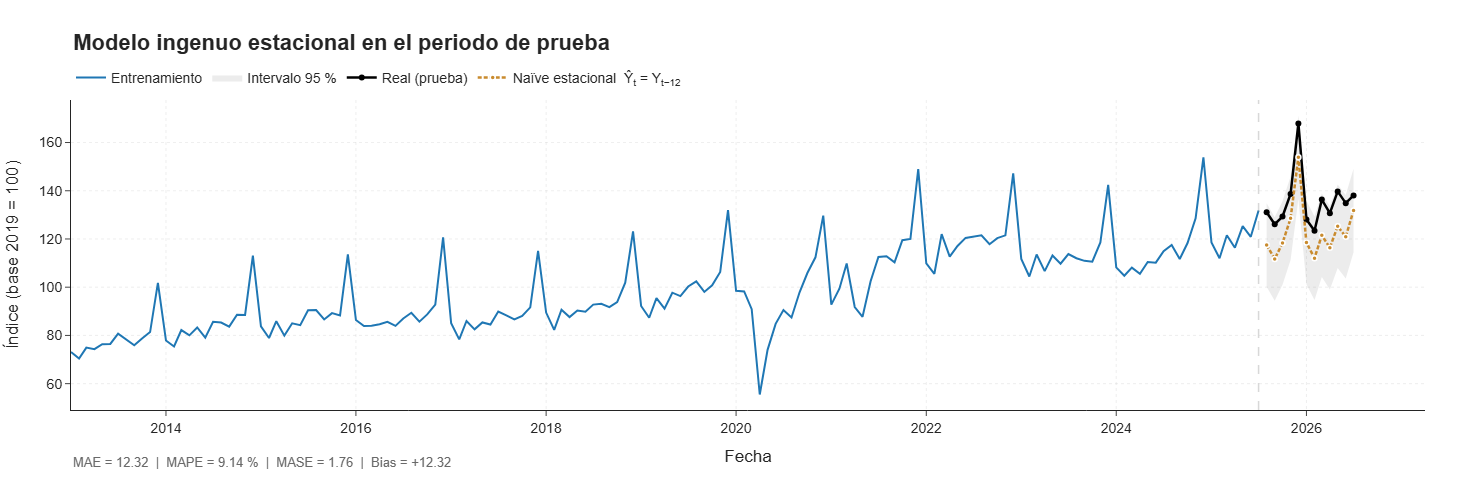

In [29]:
fig = go.Figure()

#fig.add_trace(go.Scatter(x=train["2023":].index, y=train["2023":].values, mode="lines",
fig.add_trace(go.Scatter(x=train.index, y=train.values, mode="lines",
                         name="Entrenamiento", line=dict(color="#1f77b4", width=2)))

# Intervalo del 95 %
fig.add_trace(go.Scatter(x=list(naive.index) + list(naive.index[::-1]),
                         y=list(naive["superior"]) + list(naive["inferior"][::-1]),
                         fill="toself", fillcolor="rgba(127,127,127,0.15)", line=dict(width=0),
                         name="Intervalo 95 %", hoverinfo="skip"))

fig.add_trace(go.Scatter(x=test.index, y=test.values, mode="lines+markers", name="Real (prueba)",
                         line=dict(color="black", width=2.5), marker=dict(size=6)))

fig.add_trace(go.Scatter(x=naive.index, y=naive["pronostico"], mode="lines+markers",
                         name="Naïve estacional  Ŷ<sub>t</sub> = Y<sub>t−12</sub>",
                         line=dict(color="#C98B2E", width=2.5, dash="4px,2px"),
                         marker=dict(size=5, color="#C98B2E", line=dict(color="white", width=1.5))))

fig.add_vline(x=train.index.max(), line_dash="dash", line_color="gray", line_width=1.5)

fig.update_layout(
    template="simple_white", width=1400, height=500,
    font=dict(family="Arial", size=14),
    title=dict(text="<b>Modelo ingenuo estacional en el periodo de prueba</b>",
               x=0.05, xanchor="left", font=dict(size=22)),
    xaxis_title="Fecha", yaxis_title="Índice (base 2019 = 100)",
    legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="left", x=0),
    margin=dict(l=60, r=40, t=100, b=90),
)
fig.update_xaxes(showgrid=True, gridcolor="rgba(200,200,200,0.3)", griddash="dot")
fig.update_yaxes(showgrid=True, gridcolor="rgba(200,200,200,0.3)", griddash="dot")
fig.add_annotation(text=f"MAE = {res_naive['MAE']:.2f}  |  MAPE = {res_naive['MAPE (%)']:.2f} %  |  "
                        f"MASE = {res_naive['MASE']:.2f}  |  Bias = {res_naive['Bias']:+.2f}",
                   xref="paper", yref="paper", x=0, y=-0.2, showarrow=False,
                   font=dict(size=13, color="dimgray"), xanchor="left")

guardar_figura(fig, "00_naive_estacional")
fig.show()

---

### Tabla de resultados en el periodo de prueba

Cada modelo se registra en la misma tabla con las mismas métricas sobre los mismos 12 meses de prueba (comparación homogénea). El **MASE** es la métrica de referencia:

- **MASE < 1:** el modelo tiene un error menor que el Naïve estacional dentro del entrenamiento.
- **MASE > 1:** tiene un error mayor.

Como todos usan la misma escala ($\text{ESCALA\_MASE}$, calculada una sola vez con el entrenamiento), los MASE son comparables entre modelos.

In [30]:
# Tabla de resultados: se crea una vez y cada modelo los puede agregar con la función registrar() 

resultados = pd.DataFrame()

def registrar(nombre, pronostico_df):
    """Calcula métricas y cobertura de un modelo y lo agrega (o actualiza) en la tabla de resultados."""
    global resultados
    fila = {**metricas(test, pronostico_df["pronostico"]),
            **cobertura(test, pronostico_df["inferior"], pronostico_df["superior"])}
    resultados.loc[nombre, list(fila)] = list(fila.values())
    resultados = resultados.sort_values("MASE")
    resultados.to_csv(DIR_PROC / "resultados_prueba.csv", index_label="Modelo")
    return mostrar_resultados()

def mostrar_resultados():
    """Tabla con formato: MASE resaltado (verde < 1, rojo ≥ 1)."""
    return (resultados.style
            .format({"MAE": "{:.2f}", "RMSE": "{:.2f}", "MAPE (%)": "{:.2f}", "MASE": "{:.3f}",
                     "Bias": "{:+.2f}", "Cobertura 95 % (%)": "{:.0f}", "Ancho medio": "{:.1f}"})
            .map(lambda v: "color: #2ca02c; font-weight: bold" if v < 1
                 else "color: #d62728; font-weight: bold", subset=["MASE"])
            .set_caption(f"Desempeño en prueba (ago-2025 a jul-2026) · Escala MASE = {ESCALA_MASE:.3f}"))

registrar("Naïve estacional", naive)

,MAE,RMSE,MAPE (%),MASE,Bias,Cobertura 95 % (%),Ancho medio
Naïve estacional,12.32,12.58,9.14,1.757,+12.32,100,34.6


### Lectura

- **Forma correcta, nivel bajo:** el Naïve reproduce muy bien el patrón del año, incluido el pico de diciembre, pero queda **por debajo** de la serie real en los 12 meses.
- **Bias = MAE:** todos los errores son positivos, es decir, subestima siempre. La causa es estructural: el periodo de prueba creció cerca de 10 % frente al año anterior y el Naïve supone **crecimiento cero**.
- **MASE > 1:** en este año lo hizo peor que su propio error típico dentro del entrenamiento, precisamente porque fue un año de crecimiento excepcional.
- **Intervalo:** cubre los 12 meses, pero es **muy ancho** (~35 puntos), porque $\hat\sigma$ incluye los saltos interanuales de 2020–2021. Cubrir todo con un intervalo tan ancho no es mérito.

**Este es el punto de referencia:** SARIMA, Holt-Winters y Prophet tendrán que lograr un MASE menor que el del Naïve para justificar su complejidad.

---

### __4. **Modelo SARIMA:** Analizar la estacionariedad, aplicar la prueba ADF y revisar las funciones ACF y PACF para orientar la selección de los parámetros del modelo.__

El SARIMA$(p,d,q)\times(P,D,Q)_s$ (Box y Jenkins):

$$
\Phi_P(B^{s})\,\phi_p(B)\,\nabla_s^{D}\,\nabla^{d}\,x_t = \alpha + \Theta_Q(B^{s})\,\theta_q(B)\,w_t
$$

| Término | Significado en este problema |
|---|---|
| $x_t$ | La serie que se modela (aquí $\log Y_t$) |
| $B$ | Operador de rezago: $B\,x_t = x_{t-1}$, $B^{12}x_t = x_{t-12}$ |
| $\nabla^d = (1-B)^d$ | $d$ diferencias regulares: quitan la tendencia |
| $\nabla_{12}^D = (1-B^{12})^D$ | $D$ diferencias estacionales: comparan cada mes con el mismo mes del año anterior |
| $\phi_p(B) = 1-\phi_1B-\dots-\phi_pB^p$ | Parte **AR**: el mes depende de los $p$ meses anteriores |
| $\theta_q(B) = 1+\theta_1B+\dots+\theta_qB^q$ | Parte **MA**: el mes depende de los $q$ choques anteriores |
| $\Phi_P(B^{12}),\ \Theta_Q(B^{12})$ | Partes AR y MA **estacionales** (rezagos 12, 24, …) |
| $\alpha$ | Constante (en la serie ya diferenciada) |
| $w_t$ | Ruido blanco: choques impredecibles con media 0 y varianza $\sigma_w^2$ |
| $s = 12$ | Periodo estacional (meses) |

**De dónde sale.** El teorema de Wold dice que toda serie estacionaria se puede escribir como una suma de choques pasados. ARMA aproxima esa suma con pocos parámetros. Las diferencias convierten la serie en estacionaria y los términos estacionales capturan que *este diciembre se parece al diciembre pasado*.

**Metodología Box-Jenkins:** (1) **identificar** los órdenes (estacionariedad, ADF, ACF/PACF) → (2) **estimar** → (3) **diagnosticar** los residuos → (4) **pronosticar**. Todo se hace **solo con el entrenamiento**.

---
---

### Transformación: ¿por qué logaritmo?

La serie de la gráfica general mostró que el pico de diciembre **crece con el nivel** de la serie: es una estacionalidad **multiplicativa** ($Y_t = T_t \times S_t \times R_t$). Con logaritmos se vuelve aditiva:

$$
\log Y_t = \log T_t + \log S_t + \log R_t
$$

Además, $\nabla_{12}\log Y_t = \log Y_t - \log Y_{t-12} \approx \dfrac{Y_t - Y_{t-12}}{Y_{t-12}}$ es el **crecimiento anual**, una cantidad fácil de interpretar.

Lo verificamos con la transformación de **Box-Cox**, que busca el $\lambda$ que mejor estabiliza la varianza:

$$
Y^{(\lambda)} = \begin{cases} \dfrac{Y^\lambda - 1}{\lambda}, & \lambda \neq 0 \\[1mm] \log Y, & \lambda = 0 \end{cases}
$$

Si el intervalo de confianza de $\lambda$ **incluye 0** y **excluye 1**, el logaritmo está justificado y la serie sin transformar no.

In [31]:
# Box-Cox sobre el entrenamiento

_, lam, ic_lam = stats.boxcox(train.values, alpha=0.05)
print(f"λ de Box-Cox = {lam:.3f}   IC 95 %: [{ic_lam[0]:.3f}, {ic_lam[1]:.3f}]")
print(f"¿Incluye 0 (logaritmo)?         {ic_lam[0] <= 0 <= ic_lam[1]}")
print(f"¿Incluye 1 (no transformar)?    {ic_lam[0] <= 1 <= ic_lam[1]}")

# Serie de trabajo para SARIMA
log_train = np.log(train)

λ de Box-Cox = -0.262   IC 95 %: [-1.023, 0.522]
¿Incluye 0 (logaritmo)?         True
¿Incluye 1 (no transformar)?    False


**Interpretación:** $\lambda \approx -0{,}262$, con un intervalo de $[-1{,}023;\ 0{,}522]$ que **incluye 0 y excluye 1**. Se usa el logaritmo: está dentro del intervalo y es interpretable (las diferencias de logaritmos son tasas de crecimiento). El SARIMA se ajusta sobre $\log Y_t$ y el pronóstico se devuelve con $\exp(\cdot)$.

---
---

### Estacionariedad

Una serie es **estacionaria** si su media y su varianza no cambian en el tiempo y su autocorrelación solo depende del rezago. ARMA lo exige. Comparamos tres versiones:

| Serie | Qué representa |
|---|---|
| $\log Y_t$ | Nivel (en logaritmos) |
| $\nabla_{12}\log Y_t$ | Crecimiento anual: quita la estacionalidad |
| $\nabla\nabla_{12}\log Y_t$ | Cambio mensual del crecimiento anual: quita además la tendencia |

Guardada: reports\figures\00_sarima_diferencias.png


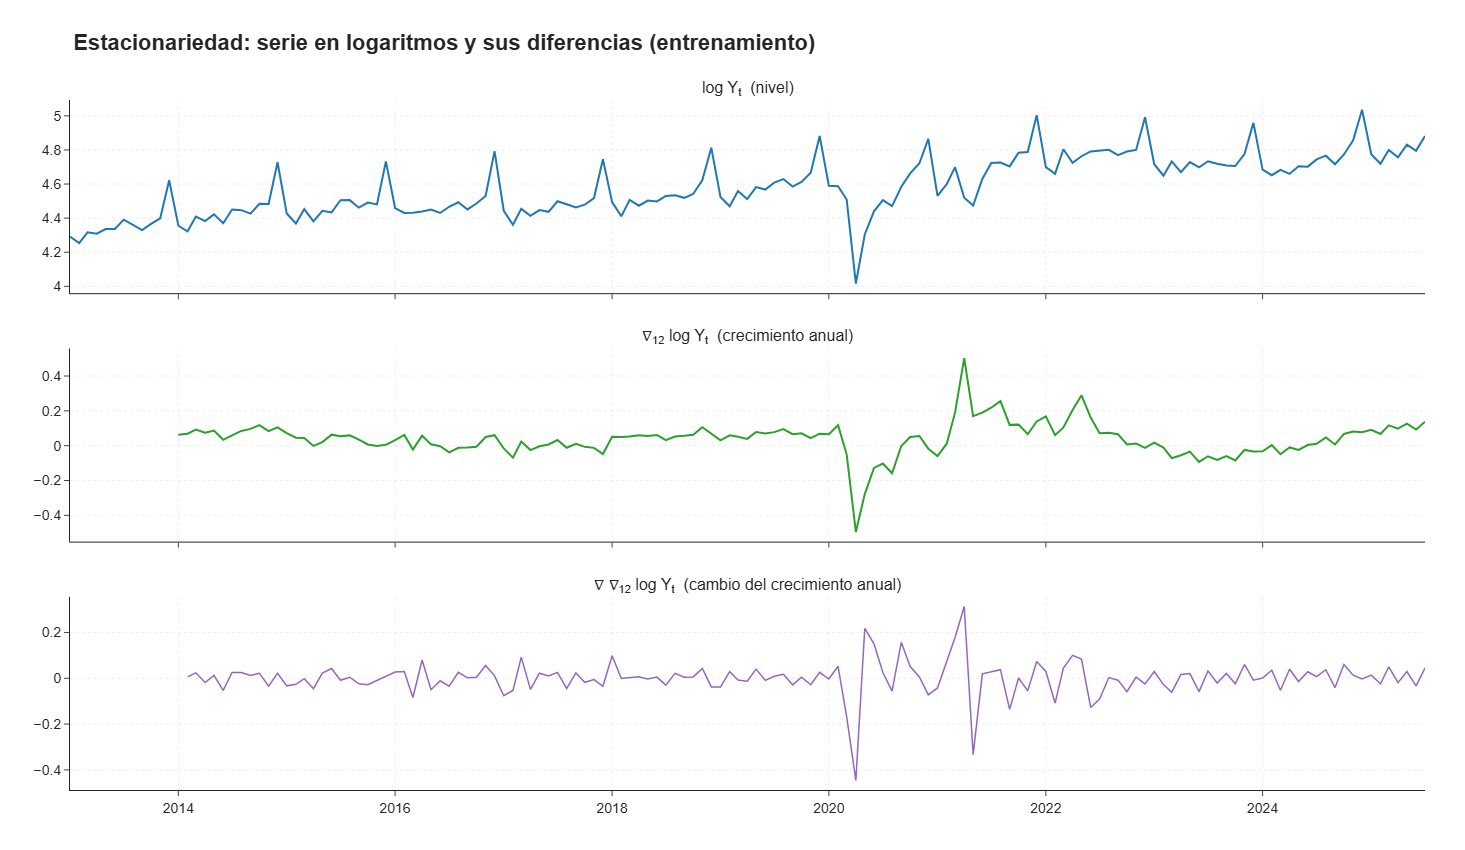

In [33]:
# Función de formato común para las gráficas de este paso

def formato(fig, titulo, alto=500, eje_y=None, leyenda=True):
    """Aplica el diseño del proyecto: simple_white, Arial, título a la izquierda, cuadrícula punteada."""
    fig.update_layout(template="simple_white", width=1400, height=alto,
                      font=dict(family="Arial", size=14), showlegend=leyenda,
                      title=dict(text=f"<b>{titulo}</b>", x=0.05, xanchor="left", font=dict(size=22)),
                      legend=dict(orientation="h", yanchor="bottom", y=1.02, xanchor="left", x=0),
                      margin=dict(l=70, r=40, t=100, b=60))
    fig.update_xaxes(showgrid=True, gridcolor="rgba(200,200,200,0.3)", griddash="dot")
    fig.update_yaxes(showgrid=True, gridcolor="rgba(200,200,200,0.3)", griddash="dot")
    if eje_y:
        fig.update_yaxes(title_text=eje_y)
    return fig

# Las tres series
d12 = log_train.diff(12).dropna()              # ∇12 log Y
dd12 = d12.diff().dropna()                     # ∇ ∇12 log Y

fig = make_subplots(rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.08,
                    subplot_titles=("log Y<sub>t</sub>  (nivel)",
                                    "∇<sub>12</sub> log Y<sub>t</sub>  (crecimiento anual)",
                                    "∇ ∇<sub>12</sub> log Y<sub>t</sub>  (cambio del crecimiento anual)"))
fig.add_trace(go.Scatter(x=log_train.index, y=log_train, line=dict(color="#1f77b4", width=2)), 1, 1)
fig.add_trace(go.Scatter(x=d12.index, y=d12, line=dict(color="#2ca02c", width=2)), 2, 1)
fig.add_trace(go.Scatter(x=dd12.index, y=dd12, line=dict(color="#9467bd", width=1.5)), 3, 1)
for fila in (2, 3):
    fig.add_hline(y=0, line_dash="dot", line_color="gray", row=fila, col=1)

formato(fig, "Estacionariedad: serie en logaritmos y sus diferencias (entrenamiento)", alto=850, leyenda=False)
guardar_figura(fig, "00_sarima_diferencias")
fig.show()

**Lectura:**

- **$\log Y_t$:** media creciente y picos de diciembre: **no estacionaria** (tendencia y estacionalidad).
- **$\nabla_{12}\log Y_t$:** desaparece el patrón estacional y la serie oscila alrededor de un crecimiento anual de ~4 %, salvo el choque de 2020–2021. Parece estacionaria, pero con **mucha persistencia** (se aleja de su media durante meses).
- **$\nabla\nabla_{12}\log Y_t$:** oscila rápidamente alrededor de 0.

Que la segunda serie parezca estacionaria no basta: hay que confirmarlo con pruebas formales.

---
---

### Pruebas de raíz unitaria: ADF, KPSS y Phillips-Perron

**ADF (Dickey-Fuller aumentada).** Estima la regresión

$$
\nabla x_t = \alpha + \beta t + \gamma\, x_{t-1} + \sum_{j=1}^{k}\delta_j \nabla x_{t-j} + \varepsilon_t
$$

- Si $\gamma = 0$, el nivel pasado no ayuda a explicar el cambio: la serie tiene **raíz unitaria** (no estacionaria).
- Los rezagos $\nabla x_{t-j}$ absorben la autocorrelación del error (eso es lo "aumentada").
- Hipótesis: $H_0: \gamma = 0$ (no estacionaria) frente a $H_1: \gamma < 0$ (estacionaria). **$p < 0{,}05$ → estacionaria.**

Como complemento, usamos dos pruebas del curso:

| Prueba | $H_0$ | $p < 0{,}05$ significa |
|---|---|---|
| **ADF** | Raíz unitaria (no estacionaria) | Estacionaria |
| **KPSS** | Estacionaria | No estacionaria |
| **PP** (Phillips-Perron) | Raíz unitaria | Estacionaria |

ADF y KPSS tienen hipótesis **opuestas**: si coinciden, la conclusión es robusta; si no, es ambigua.

In [34]:
series_prueba = {
    "log Y  (constante + tendencia)": (log_train, "ct"),   # el nivel tiene tendencia
    "∇12 log Y  (constante)": (d12, "c"),
    "∇ ∇12 log Y  (constante)": (dd12, "c"),
}

filas = {}
for nombre, (s, tendencia_prueba) in series_prueba.items():
    adf = ADF(s, trend=tendencia_prueba)                   # rezagos elegidos por AIC
    kpss = KPSS(s, trend=tendencia_prueba)
    pp = PhillipsPerron(s, trend=tendencia_prueba)
    filas[nombre] = {"ADF estadístico": adf.stat, "ADF p": adf.pvalue, "ADF rezagos": adf.lags,
                     "KPSS estadístico": kpss.stat, "KPSS p": kpss.pvalue,
                     "PP estadístico": pp.stat, "PP p": pp.pvalue}
pruebas = pd.DataFrame(filas).T

def conclusion(r):
    adf_est, kpss_est = r["ADF p"] < 0.05, r["KPSS p"] >= 0.05
    if adf_est and kpss_est:
        return "Estacionaria (ADF y KPSS coinciden)"
    if not adf_est and not kpss_est:
        return "No estacionaria (ADF y KPSS coinciden)"
    return "Ambigua (ADF y KPSS no coinciden)"

pruebas["Conclusión"] = pruebas.apply(conclusion, axis=1)
display(pruebas.style.format({c: "{:.3f}" for c in pruebas.columns if c not in ("Conclusión", "ADF rezagos")}))
pruebas.to_csv(DIR_PROC / "pruebas_raiz_unitaria.csv")

,ADF estadístico,ADF p,ADF rezagos,KPSS estadístico,KPSS p,PP estadístico,PP p,Conclusión
log Y (constante + tendencia),-2.545,0.306,12.000000,0.071,0.336,-8.174,0.000,Ambigua (ADF y KPSS no coinciden)
∇12 log Y (constante),-3.231,0.018,13.000000,0.063,0.798,-5.048,0.000,Estacionaria (ADF y KPSS coinciden)
∇ ∇12 log Y (constante),-4.731,0.000,11.000000,0.069,0.758,-15.909,0.000,Estacionaria (ADF y KPSS coinciden)


---

**Interpretación:**

| Serie | ADF $p$ | KPSS $p$ | PP $p$ | Conclusión |
|---|---|---|---|---|
| $\log Y_t$ | 0,31 | 0,34 | < 0,01 | **Ambigua** |
| $\nabla_{12}\log Y_t$ | 0,02 | 0,80 | < 0,01 | **Estacionaria: las tres coinciden** |
| $\nabla\nabla_{12}\log Y_t$ | < 0,01 | 0,76 | < 0,01 | Estacionaria |

- **En nivel:** ADF no rechaza la raíz unitaria y KPSS tampoco rechaza la estacionariedad alrededor de una tendencia, así que la evidencia es ambigua. PP rechaza, pero esta prueba **tiende a rechazar de más** cuando la serie tiene un componente MA negativo grande (Schwert, 1989), y además ninguna de las tres modela la fuerte estacionalidad del nivel. En nivel no se toma una decisión.
- **Crecimiento anual ($\nabla_{12}\log Y_t$):** las tres pruebas coinciden: **es estacionario**.

**Decisiones:**

- **$D = 1$:** una diferencia estacional, por la estacionalidad fuerte y persistente.
- **$d = 0$:** no hace falta diferencia regular, porque $\nabla_{12}\log Y_t$ ya es estacionaria. Diferenciar otra vez **sobrediferenciaría** la serie.
- **Constante $\alpha$:** sí, porque el crecimiento anual tiene media distinta de cero (~4 %).

---
---

### ACF y PACF: orientar los órdenes $p, q, P, Q$

**ACF** (autocorrelación): cuánto se parece la serie a sí misma $k$ meses atrás:

$$
r_k = \frac{\sum_{t=k+1}^{T}(x_t-\bar x)(x_{t-k}-\bar x)}{\sum_{t=1}^{T}(x_t-\bar x)^2}
$$

**PACF** (autocorrelación parcial): la correlación con el rezago $k$ **descontando** los rezagos intermedios.

Las bandas $\pm 1{,}96/\sqrt{T}$ marcan lo que se esperaría de ruido blanco. Cómo se leen (Box-Jenkins):

| Patrón | Sugiere |
|---|---|
| ACF decae gradualmente, PACF se corta en el rezago $p$ | AR($p$) |
| ACF se corta en el rezago $q$, PACF decae gradualmente | MA($q$) |
| Picos en 12, 24, 36 | Parte **estacional** ($P$ o $Q$) |
| ACF que decae muy lento | Serie **no estacionaria**: falta diferenciar |

Guardada: reports\figures\00_sarima_acf_pacf.png


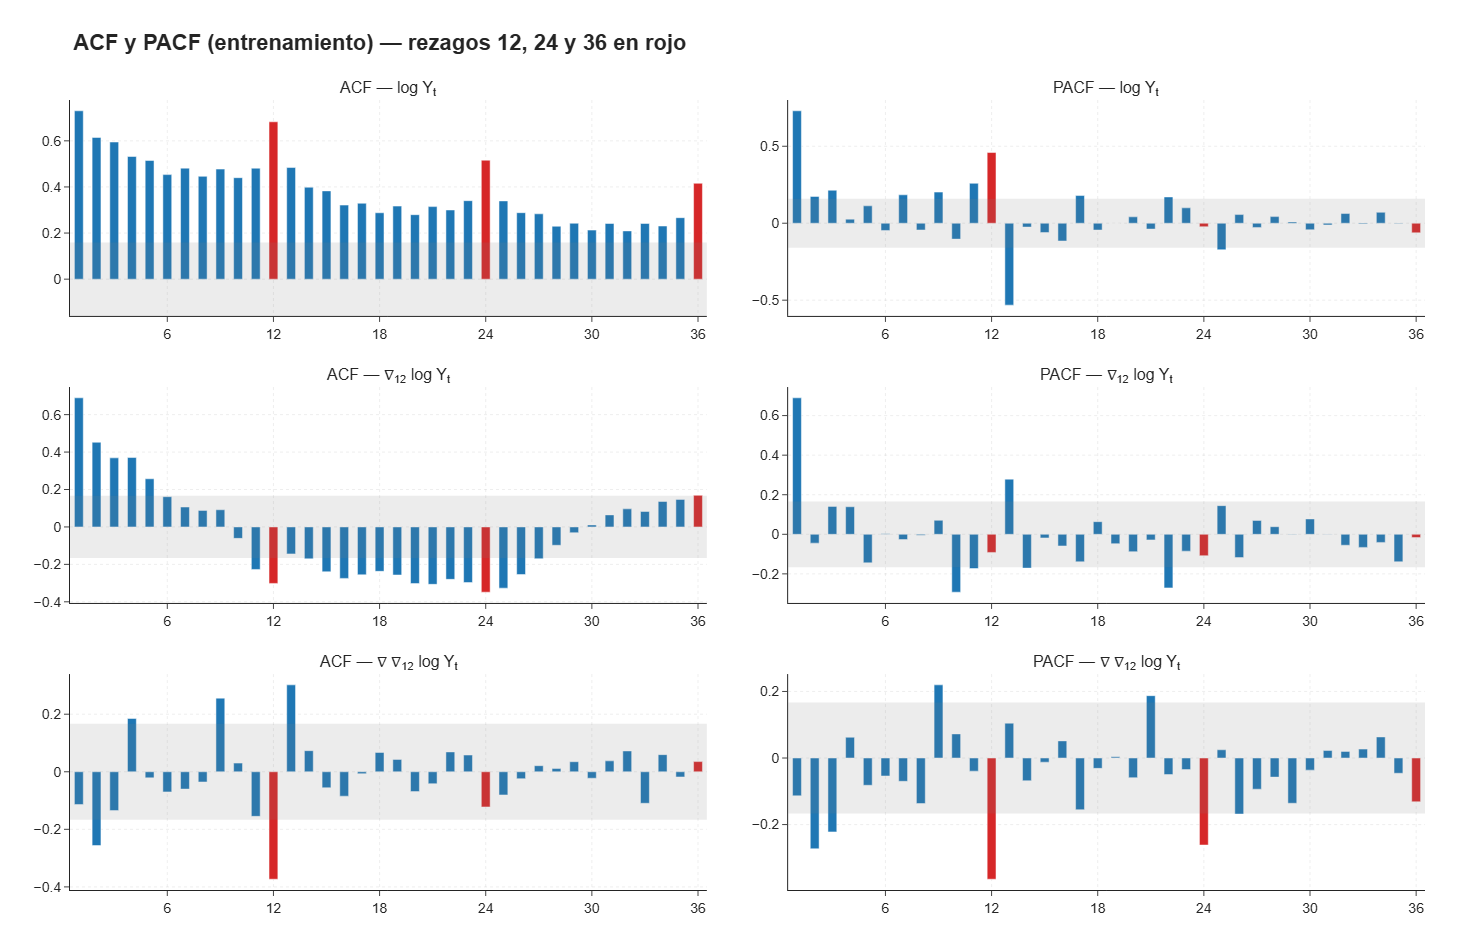

In [35]:
NLAGS = 36
series_acf = {"log Y<sub>t</sub>": log_train,
              "∇<sub>12</sub> log Y<sub>t</sub>": d12,
              "∇ ∇<sub>12</sub> log Y<sub>t</sub>": dd12}

fig = make_subplots(rows=3, cols=2, vertical_spacing=0.09, horizontal_spacing=0.06,
                    subplot_titles=[f"{f} — {n}" for n in series_acf for f in ("ACF", "PACF")])

for i, (nombre, s) in enumerate(series_acf.items(), start=1):
    banda = 1.96 / np.sqrt(len(s))
    valores = {1: acf(s, nlags=NLAGS)[1:], 2: pacf(s, nlags=NLAGS, method="ywm")[1:]}
    rezagos = np.arange(1, NLAGS + 1)
    colores = ["#d62728" if k % 12 == 0 else "#1f77b4" for k in rezagos]   # rezagos estacionales en rojo
    for col, vals in valores.items():
        fig.add_trace(go.Bar(x=rezagos, y=vals, marker_color=colores, width=0.5), i, col)
        fig.add_hrect(y0=-banda, y1=banda, fillcolor="gray", opacity=0.15, line_width=0, row=i, col=col)

formato(fig, "ACF y PACF (entrenamiento) — rezagos 12, 24 y 36 en rojo", alto=950, leyenda=False)
fig.update_xaxes(dtick=6)
guardar_figura(fig, "00_sarima_acf_pacf")
fig.show()

### Lectura de ACF y PACF

Cómo leer las barras: una barra fuera de la franja gris ($\pm 1{,}96/\sqrt{T} \approx \pm 0{,}16$) indica una correlación que no se explica por azar. Con 36 rezagos, se espera que **1 o 2 barras se salgan por casualidad** (5 % de 36 ≈ 1,8); por eso solo cuentan los patrones claros, no las barras aisladas.

---

#### 1. Nivel: $\log Y_t$ (ventas reales del mes)

| Qué se ve | Qué significa en las ventas |
|---|---|
| ACF de 0,72 en el rezago 1, que baja muy lentamente y sigue en ~0,25 a 36 meses | Las ventas de un mes están muy ligadas a las del mes anterior, y esa relación dura **años**: es el **crecimiento de largo plazo del consumo**. Si hoy se vende mucho, dentro de 3 años también, porque la economía y la población crecen seguramente. |
| Picos en 12 (0,68), 24 (0,51) y 36 (0,41) | **Cada diciembre se parece al diciembre anterior**, cada abril al abril anterior: la temporada de fin de año, los meses flojos de inicio de año y Semana Santa se repiten. |
| PACF: positiva en 12 (≈ 0,46) y fuertemente negativa en 13 (≈ −0,52) | Descontando los meses intermedios, el mismo mes del año pasado sigue explicando las ventas. El par "+12 / −13" es la huella típica de una serie con **tendencia y estacionalidad no estacionarias** a la vez. |

**Conclusión:** en nivel la serie no es estacionaria (ACF casi sin decaimiento) y tiene estacionalidad fuerte. Hay que diferenciar, empezando por la **diferencia estacional** ($D = 1$).

---

#### 2. Crecimiento anual: $\nabla_{12}\log Y_t$

Esta serie es **cuánto crecieron las ventas frente al mismo mes del año anterior** (≈ 0,05 = +5 %). La diferencia estacional elimina el efecto de diciembre.

| Qué se ve | Qué significa en las ventas |
|---|---|
| ACF alta en los primeros meses (0,69; 0,45; 0,37; 0,37; 0,26) que se apaga hacia el rezago 6 | El crecimiento es **persistente**: un periodo de ventas fuertes o débiles dura varios meses. Ejemplos: el auge de 2021–2022 y la desaceleración de 2023, que duró todo el año. El decaimiento gradual indica un proceso **autorregresivo**. |
| PACF con un solo pico grande en el rezago 1 (≈ 0,69) | Casi toda esa persistencia se explica por el **mes anterior**: si este mes las ventas crecen 8 % anual, el próximo tiende a crecer cerca de 0,7 × 8 %. Es un **AR(1) regular** ($p = 1$). |
| ACF negativa entre los rezagos 11 y 27 (mínimo ≈ −0,35 en el rezago 24) | **Efecto base de comparación**: un año de crecimiento alto suele ir seguido, uno o dos años después, de crecimiento bajo, y al revés. El caso extremo es la caída de 2020 (−39 % en abril) seguida del rebote de 2021 (abril de 2021 creció contra una base muy baja); también el auge de 2021–2022 seguido de la contracción de 2023. Buena parte de esta onda viene del **choque de 2020–2021**, que las variables de intervención (8.6) ayudan a controlar. |
| ACF en 12 ≈ −0,30, pero PACF en 12 ≈ −0,09 (no significativa) | La dependencia estacional que queda es de tipo **media móvil**, no autorregresiva: un choque en un mes (un Black Friday fuerte, un día sin IVA) **no se repite** el mismo mes del año siguiente. Sugiere **MA(1) estacional** ($Q = 1$). |
| PACF en 10, 13 y 22 (≈ ±0,27) | Barras aisladas, sin patrón. Son esperables por azar y por los meses atípicos de 2020–2021. **No se modelan.** |

**Conclusión:** el crecimiento anual se comporta como una serie **estacionaria y persistente**, lo que coincide con las pruebas ADF/KPSS/PP de 8.4.

---

#### 3. Cambio del crecimiento anual: $\nabla\nabla_{12}\log Y_t$

Es la **aceleración**: si el crecimiento anual de este mes es mayor o menor que el del mes anterior.

| Qué se ve | Qué significa en las ventas |
|---|---|
| ACF muy negativa en 12 (≈ −0,37) y positiva en 13 (≈ +0,30) | La aceleración de un mes se **revierte** el mismo mes del año siguiente: si noviembre de un año creció de más (por ejemplo, por un día sin IVA), noviembre del año siguiente parece crecer de menos porque compara contra esa base alta. El par "−12 / +13" es el patrón clásico de un **MA(1) estacional** combinado con dependencia regular. |
| PACF negativa y decreciente en 12 (−0,36), 24 (−0,26) y 36 (−0,13) | Decaimiento geométrico en los rezagos estacionales: **confirma el MA(1) estacional** ($Q = 1$, $\Theta_1 < 0$). |
| ACF en el rezago 1 ≈ −0,11 (no significativa); barras sueltas en 2 (≈ −0,26) y 9 (≈ +0,25) | Si $d = 1$ fuera necesario, esperaríamos un patrón limpio en el rezago 1. No aparece: la segunda diferencia no simplifica la estructura regular, solo agrega ruido. Es otro indicio de que **no hace falta la diferencia regular** ($d = 0$), en línea con las pruebas de raíz unitaria. |

---

#### Órdenes sugeridos

| Parámetro | Valor | De dónde sale |
|---|---|---|
| $D$ | 1 | Picos persistentes en 12, 24 y 36 en el nivel |
| $d$ | 0 | $\nabla_{12}\log Y_t$ ya es estacionaria (pruebas + ACF que se apaga) |
| $p$ | 1 | PACF del crecimiento anual con un solo pico en el rezago 1 |
| $q$ | 0 o 1 | Sin pico claro; se decide con el AIC |
| $P$ | 0 | PACF no significativa en 12 del crecimiento anual |
| $Q$ | 1 | ACF negativa en 12 y PACF decreciente en 12, 24 y 36 |

**Modelo inicial:** SARIMA$(1,0,0)\times(0,1,1)_{12}$ + constante sobre $\log Y_t$. **Alternativa de comparación:** el modelo aerolínea $(0,1,1)\times(0,1,1)_{12}$ ($d = 1$).

**En palabras del negocio:** el crecimiento anual de las ventas depende sobre todo del crecimiento del mes anterior (persistencia), regresa poco a poco a su ritmo normal, y las sorpresas de un mes concreto no se repiten el año siguiente.

---
---

### Variables de intervención para los atípicos

La gráfica general mostró atípicos en **abril y mayo de 2020** (confinamiento) y **mayo de 2021** (paro nacional). Si no se tratan, inflan la varianza estimada $\sigma_w^2$ y ensanchan todos los intervalos futuros. Se modelan como una regresión con errores SARIMA (**SARIMAX**):

$$
\log Y_t = \omega_1 I_{\text{abr-20},t} + \omega_2 I_{\text{may-20},t} + \omega_3 I_{\text{may-21},t} + N_t
$$

- $I_{j,t}$ vale 1 **solo** en el mes $j$ y 0 en los demás (pulso).
- $N_t$ sigue el SARIMA.
- Como la serie está en logaritmos, $e^{\omega_j} - 1$ es el **efecto porcentual** del evento sobre las ventas de ese mes.

In [37]:
INTERVENCIONES = ["2020-04-01", "2020-05-01", "2021-05-01"]

def matriz_intervencion(indice):
    """Variables indicadoras (pulsos): 1 en el mes del evento, 0 en los demás."""
    return pd.DataFrame({f"I_{m[:7]}": (indice == m).astype(float) for m in INTERVENCIONES}, index=indice)

X_train = matriz_intervencion(train.index)
X_test = matriz_intervencion(test.index)          # todo en cero: no hay eventos en la prueba

# ¿Aportan las intervenciones? Mismo modelo, con y sin ellas 
comparacion_iv = {}
for con_iv in (False, True):
    m = SARIMAX(log_train, exog=X_train if con_iv else None, order=(1, 0, 0),
                seasonal_order=(0, 1, 1, 12), trend="c").fit(disp=False)
    comparacion_iv["Con intervenciones" if con_iv else "Sin intervenciones"] = {
        "AIC": m.aic, "σ residual": np.sqrt(m.params["sigma2"])}
display(pd.DataFrame(comparacion_iv).T.round(3))

,AIC,σ residual
Sin intervenciones,-387.310,0.052
Con intervenciones,-511.911,0.034


**Lectura:** las intervenciones bajan el AIC en más de **120 puntos** y la desviación de los residuos de ≈ 0,052 a ≈ 0,034. Mejoran mucho el modelo, así que se mantienen.

---
---

### Selección de parámetros: búsqueda por AIC

La ACF/PACF orienta, pero no decide sola. Exploramos alrededor del modelo sugerido: $p, q \in \{0,1,2\}$, $(P,Q) \in \{(0,1),(1,0),(1,1)\}$, $D = 1$, con $d = 0$ (con constante) y $d = 1$ (sin constante), siempre con intervenciones. Comparamos con el **criterio de Akaike**:

$$
\text{AIC} = -2\ln\hat L + 2k
$$

$\hat L$ es la verosimilitud maximizada y $k$ el número de parámetros; el término $2k$ penaliza la complejidad. **Menor AIC = mejor equilibrio entre ajuste y simplicidad.**

**Importante:** el AIC solo es comparable entre modelos con el **mismo $d$**, porque con $d = 1$ la verosimilitud se calcula sobre otra serie.

In [38]:
filas = []
for d in (0, 1):
    for p, q in itertools.product((0, 1, 2), (0, 1, 2)):
        if d == 0 and p == 0 and q == 0:
            continue
        for P, Q in ((0, 1), (1, 0), (1, 1)):
            m = SARIMAX(log_train, exog=X_train, order=(p, d, q), seasonal_order=(P, 1, Q, 12),
                        trend="c" if d == 0 else "n").fit(disp=False, maxiter=500)
            filas.append({"d": d, "Modelo": f"({p},{d},{q})×({P},1,{Q})₁₂", "AIC": m.aic, "BIC": m.bic,
                          "Parámetros": len(m.params), "Convergió": m.mle_retvals.get("converged", True)})

rejilla = pd.DataFrame(filas)
print(f"Modelos estimados: {len(rejilla)} | sin convergencia: {(~rejilla['Convergió']).sum()}")
mejores = rejilla.sort_values("AIC").groupby("d").head(5).sort_values(["d", "AIC"]).set_index(["d", "Modelo"])
display(mejores.round(2))

Modelos estimados: 51 | sin convergencia: 1


AIC      BIC  Parámetros  Convergió
d Modelo                                                    
0 (1,0,1)×(0,1,1)₁₂ -516.250 -492.780           8       True
  (1,0,1)×(1,1,1)₁₂ -514.680 -488.270           9       True
  (1,0,2)×(0,1,1)₁₂ -514.450 -488.040           9       True
  (2,0,0)×(0,1,1)₁₂ -514.310 -490.830           8       True
  (2,0,1)×(0,1,1)₁₂ -513.740 -487.330           9       True
1 (0,1,1)×(0,1,1)₁₂ -508.450 -490.890           6       True
  (1,1,1)×(0,1,1)₁₂ -507.150 -486.660           7       True
  (0,1,2)×(0,1,1)₁₂ -507.130 -486.640           7       True
  (0,1,1)×(1,1,1)₁₂ -506.820 -486.330           7       True
  (2,1,0)×(0,1,1)₁₂ -506.050 -485.560           7       True

**Lectura:**

- **Con $d = 0$:** el mejor AIC es **SARIMA$(1,0,1)\times(0,1,1)_{12}$** ($\approx -516$). El sugerido por la PACF, $(1,0,0)$, queda unos 4 puntos detrás. El BIC, que penaliza más la complejidad, también pone primero a $(1,0,1)$.
- **Con $d = 1$:** el mejor es justamente el **modelo aerolínea** $(0,1,1)\times(0,1,1)_{12}$.
- En ambos casos la parte estacional ganadora es $(0,1,1)_{12}$, la que sugería la ACF.

**Modelo elegido: SARIMA$(1,0,1)\times(0,1,1)_{12}$ + constante + intervenciones sobre $\log Y_t$.** Es coherente con las pruebas de raíz unitaria ($d = 0$), con la ACF/PACF (AR regular y MA estacional) y con el AIC.

In [39]:
mod_sarima = SARIMAX(log_train, exog=X_train, order=(1, 0, 1), seasonal_order=(0, 1, 1, 12),
                     trend="c").fit(disp=False, maxiter=500)
print(mod_sarima.summary().tables[1])

par = mod_sarima.params
mu = par["intercept"] / (1 - par["ar.L1"])
print(f"\nCrecimiento anual de largo plazo: μ = α / (1 − φ₁) = {mu:.4f}  →  {100 * (np.exp(mu) - 1):.2f} % anual")
for k in X_train.columns:
    print(f"Efecto {k[2:]}: ω = {par[k]:+.3f}  →  {100 * (np.exp(par[k]) - 1):+.1f} % sobre las ventas de ese mes")

                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
intercept      0.0050      0.002      2.961      0.003       0.002       0.008
I_2020-04     -0.4538      0.019    -23.767      0.000      -0.491      -0.416
I_2020-05     -0.1926      0.021     -9.309      0.000      -0.233      -0.152
I_2021-05     -0.1567      0.033     -4.727      0.000      -0.222      -0.092
ar.L1          0.8707      0.047     18.717      0.000       0.780       0.962
ma.L1         -0.3026      0.081     -3.720      0.000      -0.462      -0.143
ma.S.L12      -0.9521      0.309     -3.081      0.002      -1.558      -0.346
sigma2         0.0011      0.000      3.736      0.000       0.001       0.002

Crecimiento anual de largo plazo: μ = α / (1 − φ₁) = 0.0384  →  3.91 % anual
Efecto 2020-04: ω = -0.454  →  -36.5 % sobre las ventas de ese mes
Efecto 2020-05: ω = -0.193  →  -17.5 % sobre las ventas de ese me

---

**Lectura de los coeficientes.** Llamando $g_t = \nabla_{12}\log Y_t$ al crecimiento anual:

$$
g_t = \alpha + \phi_1 g_{t-1} + w_t + \theta_1 w_{t-1} + \Theta_1 w_{t-12} + \theta_1\Theta_1 w_{t-13}
$$

| Coeficiente | Valor | Interpretación |
|---|---|---|
| $\phi_1$ | ≈ 0,87 | El crecimiento anual es **muy persistente**: si un mes crece más de lo normal, los siguientes también, y el efecto se diluye lentamente. |
| $\theta_1$ | ≈ −0,30 | Una parte de cada sorpresa mensual **se revierte** al mes siguiente (compras que se adelantan o se atrasan). |
| $\mu = \alpha/(1-\phi_1)$ | ≈ 0,038 | Crecimiento de **largo plazo** al que regresa el modelo: **≈ 3,9 % anual**, prácticamente el ritmo de 2014–2019. |
| $\Theta_1$ | ≈ −0,95 | Muy cerca de −1: el patrón estacional es **casi fijo** año a año. Lo que un mes se desvía un año no se repite al siguiente. |
| $\omega$ abr-2020 | ≈ −0,45 | Confinamiento: ventas **≈ 36 % menores** de lo esperado. |
| $\omega$ may-2020 | ≈ −0,19 | ≈ 17 % por debajo de lo esperado. |
| $\omega$ may-2021 | ≈ −0,16 | Paro nacional: ≈ 15 % por debajo. |

Todos los coeficientes son significativos al 5 %. **Consecuencia para el pronóstico:** el modelo hace que el crecimiento anual **converja a ≈ 3,9 %**. Si el año de prueba creció más (≈ 10 %), va a subestimar.

---
---

### Pronóstico en el periodo de prueba

El pronóstico se calcula en $\log Y_t$ y se devuelve con $\exp(\cdot)$. Los intervalos se abren con el horizonte porque la varianza del error a $h$ pasos es

$$
\sigma_h^2 = \sigma_w^2 \sum_{j=0}^{h-1}\psi_j^2,
$$

donde $\psi_j$ son los pesos de la forma MA($\infty$) del modelo. $\exp$(pronóstico en log) es la **mediana** en escala original.

In [40]:
fc = mod_sarima.get_forecast(steps=len(test), exog=X_test)
ic = fc.conf_int(alpha=0.05)

sarima_df = pd.DataFrame({"pronostico": np.exp(fc.predicted_mean.values),
                          "inferior": np.exp(ic.iloc[:, 0].values),
                          "superior": np.exp(ic.iloc[:, 1].values)}, index=test.index)

tabla = sarima_df.assign(real=test, error=test - sarima_df["pronostico"])
tabla.index = tabla.index.strftime("%Y-%m")
display(tabla.round(2))

sarima_df.to_csv(DIR_PROC / "pronostico_sarima.csv", index_label="fecha")
registrar("SARIMA(1,0,1)×(0,1,1)₁₂", sarima_df)

,pronostico,inferior,superior,real,error
fecha,,,,,
2025-08,129.320,121.150,138.030,131.060,1.740
2025-09,126.400,117.270,136.240,126.130,-0.270
2025-10,130.780,120.530,141.900,129.310,-1.480
2025-11,135.560,124.360,147.780,138.650,3.080
2025-12,166.650,152.370,182.270,167.930,1.270
2026-01,124.410,113.480,136.400,128.100,3.690
2026-02,119.380,108.690,131.120,123.430,4.050
2026-03,127.480,115.910,140.200,136.330,8.850
2026-04,120.950,109.860,133.160,130.720,9.770


,MAE,RMSE,MAPE (%),MASE,Bias,Cobertura 95 % (%),Ancho medio
"SARIMA(1,0,1)×(0,1,1)₁₂",5.33,6.68,3.95,0.760,+5.04,100,23.2
Naïve estacional,12.32,12.58,9.14,1.757,+12.32,100,34.6


---

Guardada: reports\figures\00_sarima_prueba.png


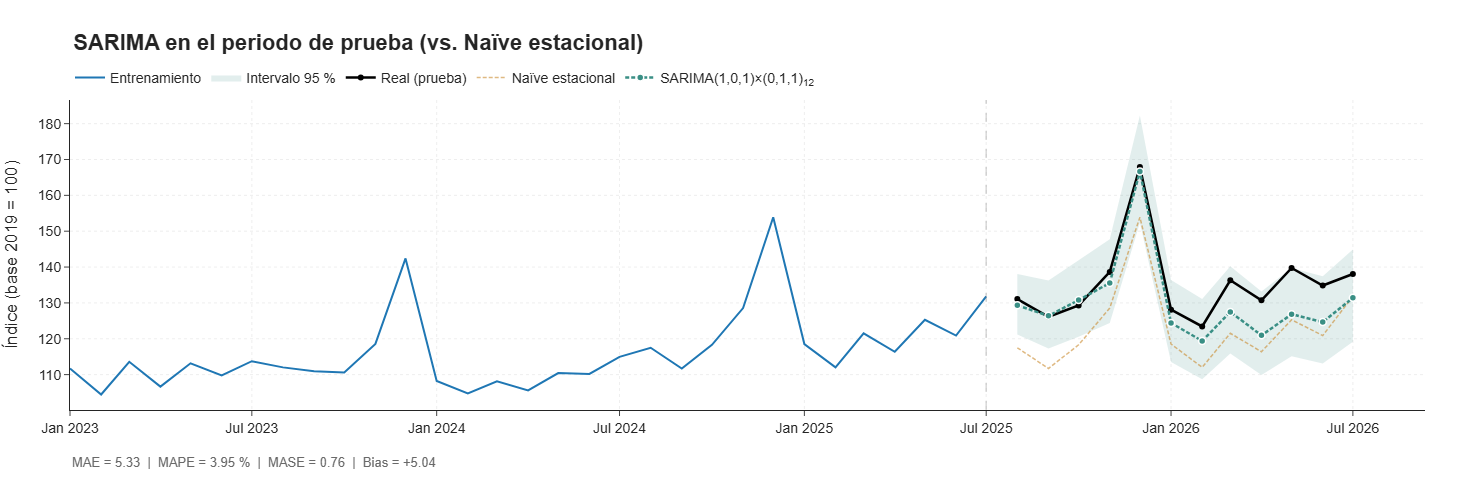

In [41]:
COLOR_SAR = "#3A8F85"   # verde azulado
fig = go.Figure()
fig.add_trace(go.Scatter(x=train["2023":].index, y=train["2023":].values, mode="lines",
                         name="Entrenamiento", line=dict(color="#1f77b4", width=2)))
fig.add_trace(go.Scatter(x=list(sarima_df.index) + list(sarima_df.index[::-1]),
                         y=list(sarima_df["superior"]) + list(sarima_df["inferior"][::-1]),
                         fill="toself", fillcolor="rgba(58,143,133,0.15)", line=dict(width=0),
                         name="Intervalo 95 %", hoverinfo="skip"))
fig.add_trace(go.Scatter(x=test.index, y=test.values, mode="lines+markers", name="Real (prueba)",
                         line=dict(color="black", width=2.5), marker=dict(size=6)))
fig.add_trace(go.Scatter(x=naive.index, y=naive["pronostico"], mode="lines", name="Naïve estacional",
                         line=dict(color="#C98B2E", width=1.5, dash="4px,2px"), opacity=0.6))
fig.add_trace(go.Scatter(x=sarima_df.index, y=sarima_df["pronostico"], mode="lines+markers",
                         name="SARIMA(1,0,1)×(0,1,1)<sub>12</sub>",
                         line=dict(color=COLOR_SAR, width=2.5, dash="4px,2px"),
                         marker=dict(size=7, color=COLOR_SAR, line=dict(color="white", width=1.5))))
fig.add_vline(x=train.index.max(), line_dash="dash", line_color="gray", line_width=1.5)

r = resultados.loc["SARIMA(1,0,1)×(0,1,1)₁₂"]
formato(fig, "SARIMA en el periodo de prueba (vs. Naïve estacional)", eje_y="Índice (base 2019 = 100)")
fig.update_layout(margin=dict(b=90))
fig.add_annotation(text=f"MAE = {r['MAE']:.2f}  |  MAPE = {r['MAPE (%)']:.2f} %  |  MASE = {r['MASE']:.2f}  |  Bias = {r['Bias']:+.2f}",
                   xref="paper", yref="paper", x=0, y=-0.2, showarrow=False,
                   font=dict(size=13, color="dimgray"), xanchor="left")
guardar_figura(fig, "00_sarima_prueba")
fig.show()

### Lectura del pronóstico

- **Agosto a diciembre de 2025:** muy preciso, con errores de 0,3 a 3 puntos y **diciembre incluido** (≈ 1 punto, menos del 1 %).
- **Marzo a julio de 2026:** se queda corto entre 7 y 13 puntos. El modelo hace converger el crecimiento a ~3,9 % y la serie aceleró a ~10 %.
- **Frente al Naïve:** MASE ≈ **0,76** contra 1,76. El error absoluto medio baja ≈ 57 %.
- **Intervalo del 95 %:** cubre los 12 meses con un ancho medio de ≈ 23 puntos, más angosto que el del Naïve (≈ 35), gracias a que las intervenciones sacan 2020–2021 de la varianza.

El diagnóstico completo de los residuos (Ljung-Box, normalidad y varianza) se presenta en el paso 9.

---
---

## __5. **Modelo Holt-Winters:** evaluar los componentes de nivel, tendencia y estacionalidad, y ajustar la estructura aditiva o multiplicativa según corresponda.__

## Modelo Holt-Winters (suavizamiento exponencial)
### La idea: promedios que "olvidan" el pasado

El suavizamiento exponencial simple actualiza un **nivel** $\ell_t$ como un promedio entre el dato nuevo y lo que se esperaba:

$$
\ell_t = \alpha\,Y_t + (1-\alpha)\,\ell_{t-1}, \qquad 0 < \alpha < 1
$$

Si se sustituye hacia atrás, queda $\ell_t = \alpha Y_t + \alpha(1-\alpha)Y_{t-1} + \alpha(1-\alpha)^2Y_{t-2} + \dots$: un promedio de **toda la historia** con pesos que decaen exponencialmente. Con $\alpha$ cercano a 1 el modelo tiene memoria corta (reacciona rápido); con $\alpha$ cercano a 0, memoria larga.

### Los tres componentes

Holt (1957) agregó una **tendencia** y Winters (1960) una **estacionalidad**. Cada componente se actualiza con la misma lógica: *dato nuevo frente a lo esperado*.

**Versión multiplicativa** (la estacionalidad es un porcentaje del nivel), con $m = 12$:

$$
\begin{aligned}
\ell_t &= \alpha\,\frac{Y_t}{s_{t-12}} + (1-\alpha)(\ell_{t-1} + \phi\,b_{t-1}) && \text{nivel}\\
b_t &= \beta^*(\ell_t - \ell_{t-1}) + (1-\beta^*)\,\phi\,b_{t-1} && \text{tendencia}\\
s_t &= \gamma\,\frac{Y_t}{\ell_{t-1} + \phi\,b_{t-1}} + (1-\gamma)\,s_{t-12} && \text{estacionalidad}\\
\hat Y_{t+h|t} &= \big(\ell_t + (\phi + \phi^2 + \dots + \phi^h)\,b_t\big)\; s_{t+h-12} && \text{pronóstico}
\end{aligned}
$$

**Versión aditiva:** las divisiones se cambian por restas y el pronóstico es $\ell_t + h\,b_t + s_{t+h-12}$ (la estacionalidad suma puntos fijos).

| Término | Qué representa en las ventas |
|---|---|
| $\ell_t$ | Nivel "normal" de ventas del mes, sin el efecto estacional (puntos del índice) |
| $b_t$ | Crecimiento mensual del nivel (puntos por mes) |
| $s_t$ | Factor del mes: $s_{\text{dic}} \approx 1{,}29$ significa "diciembre vende 29 % más que el nivel" |
| $\alpha$ | Qué tan rápido se ajusta el nivel a cada dato nuevo |
| $\beta^*$ | Qué tan rápido se ajusta el crecimiento |
| $\gamma$ | Qué tan rápido cambia el patrón estacional ($\gamma \approx 0$: el patrón es fijo) |
| $\phi$ | **Amortiguamiento** ($0 < \phi \le 1$): con $\phi < 1$ la tendencia se va apagando con el horizonte en lugar de proyectarse indefinidamente |

### Estimación e intervalos

Usamos `ETSModel` de `statsmodels`, la forma de **espacio de estados** de Holt-Winters (Hyndman et al., 2002). Da los mismos pronósticos que las ecuaciones de arriba, pero además:

- estima $\alpha, \beta^*, \gamma, \phi$ y los estados iniciales por **máxima verosimilitud**;
- entrega **intervalos de predicción** que se abren con el horizonte.

---
---

### ¿Aditiva o multiplicativa? Candidatos

La exploración (gráfica general y Box-Cox) mostró que el pico de diciembre **crece con el nivel**, lo que indica estacionalidad multiplicativa, y que la tendencia **cambia de ritmo** (2020, 2021–2022, 2023). En lugar de suponer, comparamos cuatro configuraciones:

| Candidato | Tendencia | Estacionalidad | Por qué está |
|---|---|---|---|
| Aditivo | aditiva | aditiva | Referencia: lo que se haría sin explorar la serie |
| Multiplicativo | aditiva | **multiplicativa** | Lo que sugiere la exploración |
| Multiplicativo amortiguado | aditiva **amortiguada** | multiplicativa | La tendencia cambia de ritmo: mejor no extrapolarla sin freno |
| Aditivo sobre log | aditiva | aditiva sobre $\log Y_t$ | Forma equivalente de "multiplicativo" vía transformación |

**¿Cómo elegir sin tocar la prueba?** Con **backtesting con ventana creciente** dentro del entrenamiento: se entrena hasta un origen, se pronostican 12 meses y se mide el error; luego se avanza el origen 6 meses y se repite. Usamos 5 orígenes (jul-2022, ene-2023, jul-2023, ene-2024 y jul-2024). La última ventana termina en jul-2025, así que **ninguna toca la prueba**. Gana el de menor **MASE promedio**.

> El AIC no sirve aquí para comparar los cuatro: solo es comparable entre modelos ajustados a la misma variable, y el cuarto usa $\log Y_t$.

In [42]:
COLOR_HW = "#7E6BA8"   # violeta grisáceo

CANDIDATOS_HW = {
    "HW aditivo":                    dict(error="add", trend="add", damped_trend=False, seasonal="add", log=False),
    "HW multiplicativo":             dict(error="mul", trend="add", damped_trend=False, seasonal="mul", log=False),
    "HW multiplicativo amortiguado": dict(error="mul", trend="add", damped_trend=True,  seasonal="mul", log=False),
    "HW aditivo sobre log":          dict(error="add", trend="add", damped_trend=False, seasonal="add", log=True),
}

def ajustar_hw(serie, h=12, log=False, **cfg):
    """Ajusta Holt-Winters (ETS) y devuelve (pronóstico con intervalo 95 %, modelo)."""
    datos = np.log(serie) if log else serie
    modelo = ETSModel(datos, seasonal_periods=12, **cfg).fit(disp=False, maxiter=3000)
    pred = modelo.get_prediction(start=len(datos), end=len(datos) + h - 1,
                                 simulate_repetitions=2000, rng=np.random.default_rng(2026))
    sf = pred.summary_frame(alpha=0.05)
    f = np.exp if log else (lambda v: v)                       # devolver a escala original
    indice = pd.date_range(serie.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq="MS")
    df = pd.DataFrame({"pronostico": f(sf["mean"].values),
                       "inferior": f(sf["pi_lower"].values),
                       "superior": f(sf["pi_upper"].values)}, index=indice)
    return df, modelo

ORIGENES = ["2022-07-01", "2023-01-01", "2023-07-01", "2024-01-01", "2024-07-01"]

def backtesting(funcion, h=12, **cfg):
    """Ventana creciente dentro del entrenamiento: MASE de cada origen (escala del Naïve hasta ese origen)."""
    filas = {}
    for o in pd.to_datetime(ORIGENES):
        tr = train[:o]
        fc, _ = funcion(tr, h, **cfg)
        real = train.reindex(fc.index)
        escala = np.mean(np.abs(tr.values[12:] - tr.values[:-12]))
        e = real - fc["pronostico"]
        filas[f"{o:%Y-%m}"] = {"MASE": e.abs().mean() / escala,
                               "MAPE (%)": 100 * (e.abs() / real).mean(),
                               "Bias": e.mean()}
    return pd.DataFrame(filas).T

In [43]:
bt_hw = {nombre: backtesting(ajustar_hw, **cfg) for nombre, cfg in CANDIDATOS_HW.items()}

seleccion_hw = pd.DataFrame({n: b.mean() for n, b in bt_hw.items()}).T.sort_values("MASE")
mase_origen = pd.DataFrame({n: b["MASE"] for n, b in bt_hw.items()}).T

display(Markdown("**MASE promedio en el backtesting (5 orígenes dentro del entrenamiento)**"))
display(seleccion_hw.round(3))
display(Markdown("**MASE por origen**"))
display(mase_origen.round(2))

ELEGIDO_HW = seleccion_hw.index[0]
print("Configuración elegida:", ELEGIDO_HW)

**MASE promedio en el backtesting (5 orígenes dentro del entrenamiento)**

,MASE,MAPE (%),Bias
HW multiplicativo amortiguado,0.703,4.089,0.440
HW aditivo,0.731,4.361,-1.213
HW aditivo sobre log,0.775,4.615,-1.674
HW multiplicativo,0.784,4.674,-2.216


**MASE por origen**

,2022-07,2023-01,2023-07,2024-01,2024-07
HW aditivo,1.030,0.730,0.400,0.490,1.020
HW multiplicativo,1.200,0.860,0.580,0.380,0.900
HW multiplicativo amortiguado,0.790,0.530,0.300,0.660,1.240
HW aditivo sobre log,1.220,0.860,0.410,0.420,0.970


Configuración elegida: HW multiplicativo amortiguado


### Lectura de la selección

| Candidato | MASE promedio | Bias |
|---|---|---|
| **Multiplicativo amortiguado** | **≈ 0,70** | ≈ +0,4 |
| Aditivo | ≈ 0,73 | ≈ −1,2 |
| Aditivo sobre log | ≈ 0,78 | ≈ −1,7 |
| Multiplicativo | ≈ 0,78 | ≈ −2,2 |

- Gana el **multiplicativo amortiguado**: menor error y el **único sin sesgo**. Los otros tres tienen Bias negativo, es decir, **sobreestiman las ventas**: proyectan hacia adelante el crecimiento reciente y la serie luego no lo sostiene (el auge de 2021–2022 seguido de la desaceleración de 2023).
- El aditivo queda segundo, por delante de los dos multiplicativos sin amortiguar. En esta serie pesa más **frenar la tendencia** que la forma de la estacionalidad. El ganador combina las dos cosas que mostró la exploración: estacionalidad **multiplicativa** y tendencia que **no conviene extrapolar sin freno**.
- Ningún candidato gana en todos los orígenes; por eso se decide con el promedio y no con un solo año.

__El modelo elegido: parámetros y componentes__

In [44]:
cfg = CANDIDATOS_HW[ELEGIDO_HW]
hw_df, mod_hw = ajustar_hw(train, len(test), **cfg)

param_hw = pd.Series(np.asarray(mod_hw.params), index=mod_hw.param_names)
tabla_param = pd.DataFrame({
    "Valor": [param_hw["smoothing_level"], param_hw["smoothing_trend"],
              param_hw["smoothing_seasonal"], param_hw.get("damping_trend", 1.0)],
}, index=["α (nivel)", "β* (tendencia)", "γ (estacionalidad)", "φ (amortiguamiento)"])
display(tabla_param.round(4))

estados = mod_hw.states
print(f"Tendencia b_t: {estados['trend'].iloc[0]:.3f} puntos/mes (2013) → {estados['trend'].iloc[-1]:.3f} puntos/mes (jul-2025)")
print(f"Nivel ℓ_t al final del entrenamiento: {estados['level'].iloc[-1]:.1f}")

,Valor
α (nivel),0.589
β* (tendencia),0.000
γ (estacionalidad),0.000
φ (amortiguamiento),0.980


Tendencia b_t: 0.554 puntos/mes (2013) → 0.028 puntos/mes (jul-2025)
Nivel ℓ_t al final del entrenamiento: 124.0


Guardada: reports\figures\00_hw_componentes.png


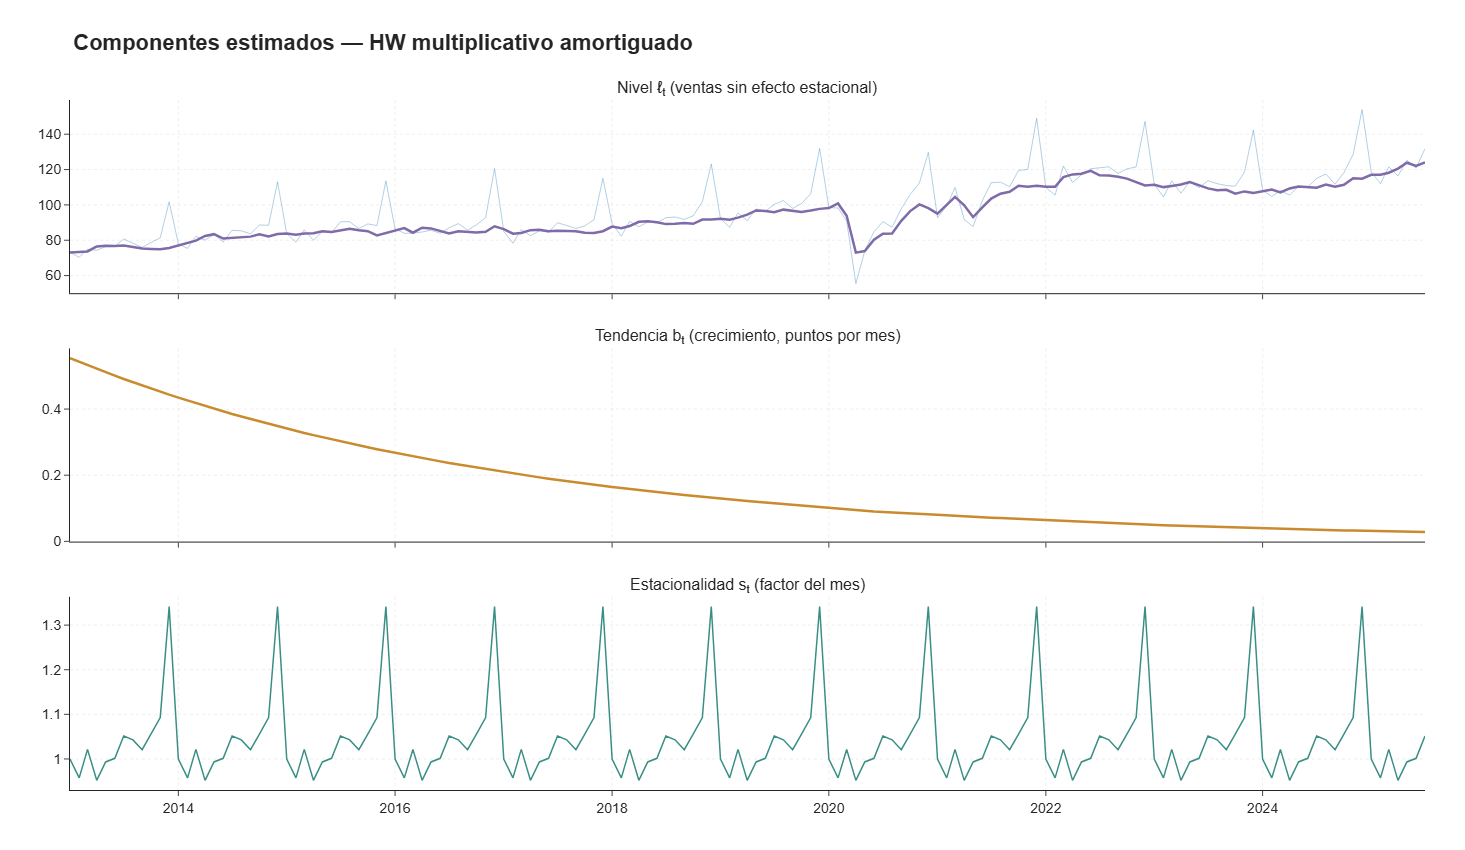

In [45]:
fig = make_subplots(rows=3, cols=1, shared_xaxes=True, vertical_spacing=0.08,
                    subplot_titles=("Nivel ℓ<sub>t</sub> (ventas sin efecto estacional)",
                                    "Tendencia b<sub>t</sub> (crecimiento, puntos por mes)",
                                    "Estacionalidad s<sub>t</sub> (factor del mes)"))
fig.add_trace(go.Scatter(x=train.index, y=train, name="Y<sub>t</sub>",
                         line=dict(color="#1f77b4", width=1), opacity=0.35), 1, 1)
fig.add_trace(go.Scatter(x=estados.index, y=estados["level"], name="Nivel",
                         line=dict(color=COLOR_HW, width=2.5)), 1, 1)
fig.add_trace(go.Scatter(x=estados.index, y=estados["trend"], name="Tendencia",
                         line=dict(color="#C98B2E", width=2.5)), 2, 1)
fig.add_hline(y=0, line_dash="dot", line_color="gray", row=2, col=1)
fig.add_trace(go.Scatter(x=estados.index, y=estados["seasonal"], name="Estacionalidad",
                         line=dict(color="#3A8F85", width=1.5)), 3, 1)
fig.add_hline(y=1, line_dash="dot", line_color="gray", row=3, col=1)

formato(fig, f"Componentes estimados — {ELEGIDO_HW}", alto=850, leyenda=False)
guardar_figura(fig, "00_hw_componentes")
fig.show()

### Lectura de los parámetros y componentes

| Parámetro | Valor | Qué dice de las ventas |
|---|---|---|
| $\alpha$ | ≈ 0,59 | El nivel **reacciona con fuerza** a cada dato nuevo: absorbe rápido el choque de 2020 y los cambios de ritmo. |
| $\beta^*$ | ≈ 0 | La tendencia **no se actualiza** con los datos: sigue su trayectoria inicial. |
| $\gamma$ | ≈ 0 | El patrón estacional es **fijo**: diciembre pesa lo mismo todos los años, como mostró la exploración. |
| $\phi$ | 0,98 | Amortiguamiento suave por mes (es el máximo que permite `statsmodels`), pero acumulado en 151 meses pesa mucho. |

- **Nivel:** sigue de cerca a la serie, incluida la caída de 2020. Holt-Winters no tiene un mecanismo para atípicos, así que el confinamiento **entra en el nivel**.
- **Tendencia:** con $\beta^* \approx 0$ y $\phi = 0{,}98$, el crecimiento inicial (≈ 0,55 puntos por mes en 2013) **se apaga gradualmente** y al final del entrenamiento vale ≈ 0,03. Los cambios de ritmo (2020, 2021–2022, 2023) los absorbe el nivel, no la tendencia.
- **Estacionalidad:** idéntica cada año, con picos de ≈ 1,29 en diciembre.

**Consecuencia para el pronóstico:** como la tendencia casi desapareció, el pronóstico es prácticamente **nivel × factor del mes, sin crecimiento**. Si el año siguiente las ventas aceleran, el modelo se quedará corto.

---
---

### Pronóstico en el periodo de prueba

In [46]:
tabla = hw_df.assign(real=test, error=test - hw_df["pronostico"])
tabla.index = tabla.index.strftime("%Y-%m")
display(tabla.round(2))

hw_df.to_csv(DIR_PROC / "pronostico_holt_winters.csv", index_label="fecha")
registrar("Holt-Winters (mult. amortiguado)", hw_df)

,pronostico,inferior,superior,real,error
2025-08,129.360,116.460,141.550,131.060,1.700
2025-09,126.640,112.840,140.870,126.130,-0.510
2025-10,130.990,114.490,147.610,129.310,-1.690
2025-11,135.630,117.030,155.400,138.650,3.020
2025-12,166.600,142.470,193.020,167.930,1.330
2026-01,124.180,105.260,145.160,128.100,3.920
2026-02,118.950,99.930,139.710,123.430,4.480
2026-03,126.890,104.870,151.120,136.330,9.440
2026-04,118.300,97.700,142.830,130.720,12.420
2026-05,123.440,100.490,149.750,139.740,16.300


,MAE,RMSE,MAPE (%),MASE,Bias,Cobertura 95 % (%),Ancho medio
"SARIMA(1,0,1)×(0,1,1)₁₂",5.33,6.68,3.95,0.760,+5.04,100,23.2
Holt-Winters (mult. amortiguado),6.04,7.76,4.48,0.862,+5.68,100,42.1
Naïve estacional,12.32,12.58,9.14,1.757,+12.32,100,34.6


Guardada: reports\figures\00_hw_prueba.png


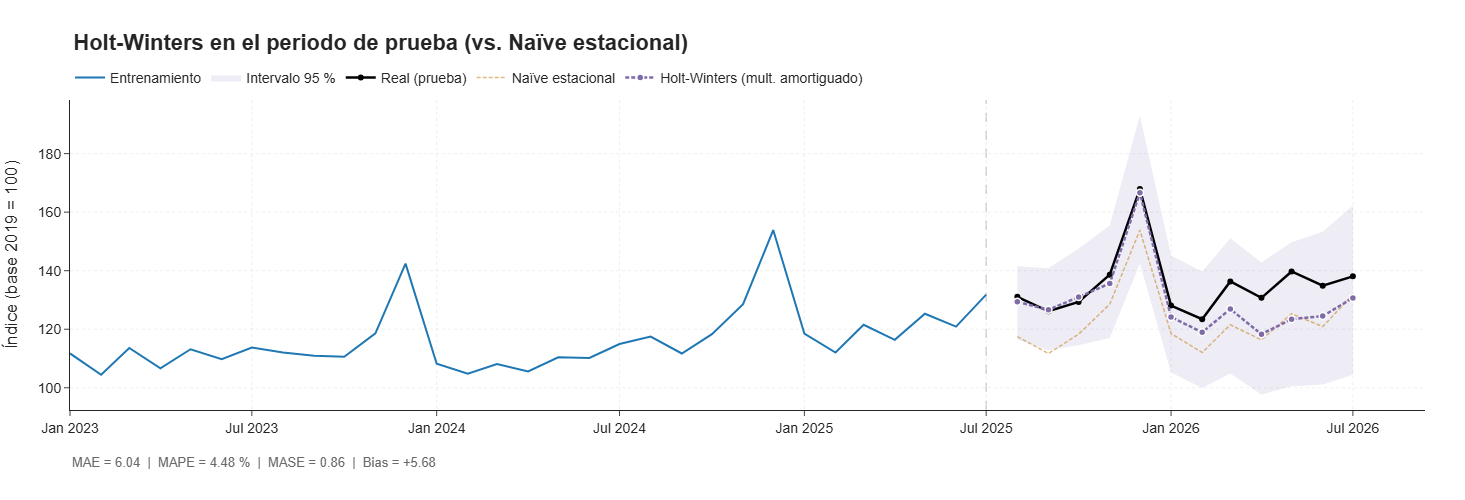

In [47]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=train["2023":].index, y=train["2023":].values, mode="lines",
                         name="Entrenamiento", line=dict(color="#1f77b4", width=2)))
fig.add_trace(go.Scatter(x=list(hw_df.index) + list(hw_df.index[::-1]),
                         y=list(hw_df["superior"]) + list(hw_df["inferior"][::-1]),
                         fill="toself", fillcolor="rgba(126,107,168,0.13)", line=dict(width=0),
                         name="Intervalo 95 %", hoverinfo="skip"))
fig.add_trace(go.Scatter(x=test.index, y=test.values, mode="lines+markers", name="Real (prueba)",
                         line=dict(color="black", width=2.5), marker=dict(size=6)))
fig.add_trace(go.Scatter(x=naive.index, y=naive["pronostico"], mode="lines", name="Naïve estacional",
                         line=dict(color="#C98B2E", width=1.5, dash="4px,2px"), opacity=0.6))
fig.add_trace(go.Scatter(x=hw_df.index, y=hw_df["pronostico"], mode="lines+markers",
                         name="Holt-Winters (mult. amortiguado)",
                         line=dict(color=COLOR_HW, width=2.5, dash="4px,2px"),
                         marker=dict(size=7, color=COLOR_HW, line=dict(color="white", width=1.5))))
fig.add_vline(x=train.index.max(), line_dash="dash", line_color="gray", line_width=1.5)

r = resultados.loc["Holt-Winters (mult. amortiguado)"]
formato(fig, "Holt-Winters en el periodo de prueba (vs. Naïve estacional)", eje_y="Índice (base 2019 = 100)")
fig.update_layout(margin=dict(b=90))
fig.add_annotation(text=f"MAE = {r['MAE']:.2f}  |  MAPE = {r['MAPE (%)']:.2f} %  |  MASE = {r['MASE']:.2f}  |  Bias = {r['Bias']:+.2f}",
                   xref="paper", yref="paper", x=0, y=-0.2, showarrow=False,
                   font=dict(size=13, color="dimgray"), xanchor="left")
guardar_figura(fig, "00_hw_prueba")
fig.show()

In [48]:
lb_hw = acorr_ljungbox(mod_hw.resid, lags=[12, 24], model_df=4, return_df=True)
lb_hw.index.name = "Rezago H"
display(lb_hw.round(4))

,lb_stat,lb_pvalue
Rezago H,,
12,51.333,0.000
24,68.411,0.000


### Lectura

- **Agosto a diciembre de 2025:** muy preciso. **Diciembre de 2025** se pronostica con un error de ≈ 1,3 puntos (< 1 %): para un comerciante que planea la temporada, el modelo acierta lo más importante.
- **Desde marzo de 2026:** se queda corto entre 9 y 16 puntos, siempre por debajo. Es lo que anticipaban los parámetros: sin tendencia, el modelo no ve la aceleración de 2026.
- **Frente al Naïve:** MASE ≈ **0,86** contra 1,76. Reduce el error a la mitad, pero queda por detrás de SARIMA (≈ 0,76).
- **Intervalo del 95 %:** cubre los 12 meses, pero es **muy ancho** (≈ 42 puntos de ancho medio). Incorpora la volatilidad de 2020–2021 en su varianza: es honesto, pero poco útil para planear.
- **Residuos:** Ljung-Box **rechaza** la ausencia de autocorrelación ($p < 0{,}001$). Queda estructura sin capturar, sobre todo por los meses de 2020–2021, que Holt-Winters no puede separar de la dinámica normal. Esta es la principal desventaja frente a SARIMA, que sí usa variables de intervención.

---
---

### __6. **Modelo Prophet:** ajustar el modelo considerando tendencia, estacionalidad y posibles puntos de cambio en la serie.__

## Modelo Prophet
### El modelo

Prophet (Taylor y Letham, 2018, Meta) descompone la serie en componentes que se **suman**, como un modelo aditivo generalizado:

$$
y(t) = g(t) + s(t) + h(t) + \varepsilon_t
$$

Como la estacionalidad de las ventas es **multiplicativa** (el pico de diciembre crece con el nivel), usamos la forma multiplicativa:

$$
y(t) = g(t)\,\big[1 + s(t) + h(t)\big] + \varepsilon_t
$$

| Componente | Qué representa en las ventas |
|---|---|
| $g(t)$ | **Tendencia**: el nivel de ventas de largo plazo |
| $s(t)$ | **Estacionalidad anual**: el % que cada mes vende por encima o por debajo de la tendencia |
| $h(t)$ | **Eventos**: el efecto de fechas especiales (confinamiento, paro) en % sobre la tendencia |
| $\varepsilon_t$ | Error |

### Tendencia con puntos de cambio

La tendencia es **lineal por tramos**: la pendiente puede cambiar en ciertos meses, los *puntos de cambio*:

$$
g(t) = \big(k + \mathbf a(t)^\top\boldsymbol\delta\big)\,t + \big(b + \mathbf a(t)^\top\boldsymbol\gamma\big)
$$

| Término | Significado |
|---|---|
| $k$ | Crecimiento inicial de las ventas (pendiente) |
| $c_1, \dots, c_S$ | Puntos de cambio candidatos: 25 por defecto, repartidos en el primer 80 % de la historia |
| $\delta_j$ | Cuánto cambia el ritmo de crecimiento en $c_j$ (positivo = acelera, negativo = frena) |
| $a_j(t)$ | Vale 1 a partir de $c_j$: activa los cambios que ya ocurrieron |
| $\gamma_j = -c_j\delta_j$ | Ajuste para que la tendencia sea **continua** (sin saltos) en cada $c_j$ |

Los $\delta_j$ tienen una distribución previa $\text{Laplace}(0, \tau)$, con $\tau$ = `changepoint_prior_scale`. **Este es el parámetro clave:**

- $\tau$ **pequeño**: casi todos los $\delta_j$ quedan en cero y la tendencia es **rígida** (casi una recta).
- $\tau$ **grande**: la tendencia se dobla en muchos puntos y puede **sobreajustar**, persiguiendo cada cambio reciente.

### Estacionalidad de Fourier

$$
s(t) = \sum_{n=1}^{N}\left[a_n\cos\!\left(\frac{2\pi n t}{365{,}25}\right) + b_n\sin\!\left(\frac{2\pi n t}{365{,}25}\right)\right]
$$

Es una suma de ondas con periodo de un año. Con más términos ($N = 10$ por defecto) puede representar formas puntudas como el salto de diciembre.

### Eventos

Los atípicos de la exploración se declaran como eventos, cada uno con su propio efecto estimado:

- **Confinamiento:** abril de 2020 y mayo de 2020, por separado.
- **Paro nacional:** mayo de 2021.

Así Prophet no los confunde con un cambio de tendencia.

### Incertidumbre

Prophet simula futuros cambios de pendiente con la misma frecuencia y magnitud que los históricos, y les suma el ruido. **Por defecto el intervalo es del 80 %**; aquí se fija en 95 % para compararlo con los demás modelos.

In [49]:
COLOR_PRO = "#B5654A"   # terracota suave

# Eventos: un nombre por mes para que cada uno tenga su propio efecto
EVENTOS = pd.DataFrame({
    "holiday": ["confinamiento_abr2020", "confinamiento_may2020", "paro_nacional_may2021"],
    "ds": pd.to_datetime(["2020-04-01", "2020-05-01", "2021-05-01"]),
})

def ajustar_prophet(serie, h=12, changepoint_prior_scale=0.05, eventos=True):
    """Ajusta Prophet multiplicativo y devuelve (pronóstico con intervalo 95 %, modelo)."""
    df = pd.DataFrame({"ds": serie.index, "y": serie.values})
    m = Prophet(seasonality_mode="multiplicative",
                yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False,
                changepoint_prior_scale=changepoint_prior_scale,
                holidays=EVENTOS if eventos else None,
                interval_width=0.95, uncertainty_samples=1000)
    np.random.seed(2026)                                   # intervalos reproducibles
    m.fit(df)
    futuro = m.make_future_dataframe(periods=h, freq="MS")
    pred = m.predict(futuro).tail(h)
    salida = pd.DataFrame({"pronostico": pred["yhat"].values,
                           "inferior": pred["yhat_lower"].values,
                           "superior": pred["yhat_upper"].values},
                          index=pd.DatetimeIndex(pred["ds"].values))
    return salida, m

### Elección de `changepoint_prior_scale` ($\tau$)

Con el mismo **backtesting** que Holt-Winters (5 orígenes dentro del entrenamiento, sin tocar la prueba), probamos valores de $\tau$ desde muy rígido (0,001) hasta muy flexible (0,5). El valor por defecto de Prophet es 0,05.

10:28:06 - cmdstanpy - INFO - Chain [1] start processing
10:28:14 - cmdstanpy - INFO - Chain [1] done processing
10:28:14 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted
10:28:14 - cmdstanpy - INFO - Chain [1] start processing
10:28:15 - cmdstanpy - INFO - Chain [1] done processing
10:28:16 - cmdstanpy - INFO - Chain [1] start processing
10:28:16 - cmdstanpy - INFO - Chain [1] done processing
10:28:17 - cmdstanpy - INFO - Chain [1] start processing
10:28:17 - cmdstanpy - INFO - Chain [1] done processing
10:28:17 - cmdstanpy - INFO - Chain [1] start processing
10:28:17 - cmdstanpy - INFO - Chain [1] done processing
10:28:17 - cmdstanpy - ERROR - Chain [1] error: code '1' Operation not permitted
10:28:17 - cmdstanpy - INFO - Chain [1] start processing
10:28:18 - cmdstanpy - INFO - Chain [1] done processing
10:28:19 - cmdstanpy - INFO - Chain [1] start processing
10:28:19 - cmdstanpy - INFO - Chain [1] done processing
10:28:19 - cmdstanpy - INFO - Chain [1] start p

,MASE,MAPE (%),Bias
τ,,,
0.001,0.589,3.565,-2.007
0.005,0.539,3.225,-0.217
0.010,0.629,3.811,-2.258
0.050,1.502,9.105,-6.212
0.100,1.706,10.251,-5.413
0.500,1.705,10.185,-4.026


τ elegido: 0.005
Guardada: reports\figures\00_prophet_tau.png


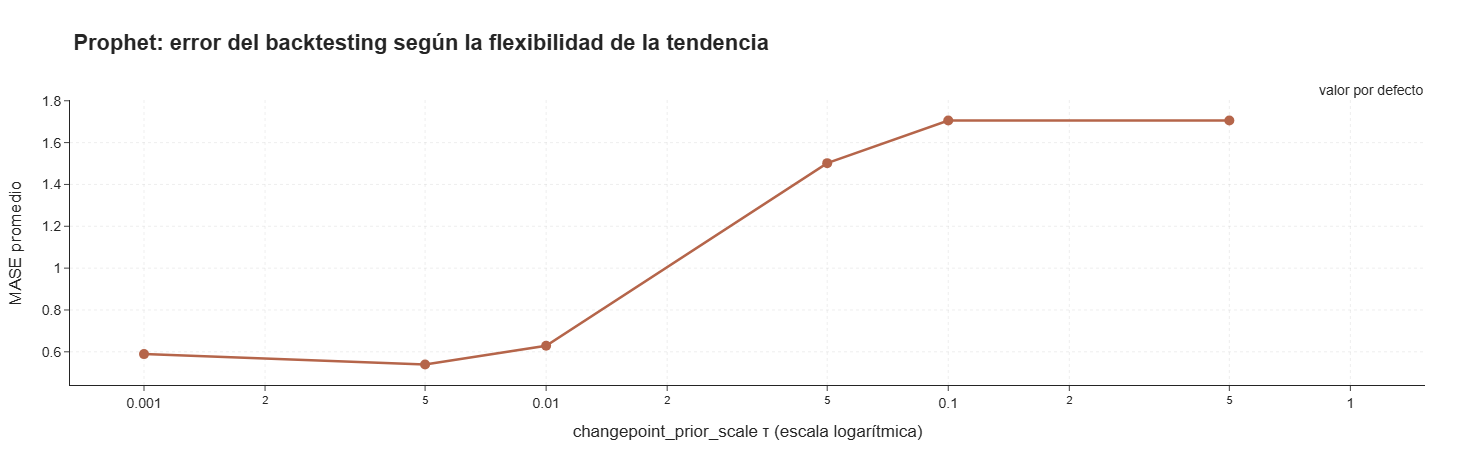

In [50]:
GRID_TAU = [0.001, 0.005, 0.01, 0.05, 0.1, 0.5]
bt_pro = {tau: backtesting(ajustar_prophet, changepoint_prior_scale=tau) for tau in GRID_TAU}

seleccion_pro = pd.DataFrame({tau: b.mean() for tau, b in bt_pro.items()}).T
seleccion_pro.index.name = "τ"
display(seleccion_pro.round(3))

TAU = seleccion_pro["MASE"].idxmin()
print(f"τ elegido: {TAU}")

# Gráfica: MASE según τ
fig = go.Figure(go.Scatter(x=GRID_TAU, y=seleccion_pro["MASE"], mode="lines+markers",
                           line=dict(color=COLOR_PRO, width=2.5), marker=dict(size=10)))
fig.add_vline(x=0.05, line_dash="dot", line_color="gray",
              annotation_text="valor por defecto", annotation_position="top")
fig.update_xaxes(type="log", title_text="changepoint_prior_scale τ (escala logarítmica)")
formato(fig, "Prophet: error del backtesting según la flexibilidad de la tendencia",
        alto=450, eje_y="MASE promedio", leyenda=False)
guardar_figura(fig, "00_prophet_tau")
fig.show()

In [51]:
sin_eventos = backtesting(ajustar_prophet, changepoint_prior_scale=TAU, eventos=False).mean()
display(pd.DataFrame({"Con eventos": seleccion_pro.loc[TAU], "Sin eventos": sin_eventos}).T.round(3))

10:30:08 - cmdstanpy - INFO - Chain [1] start processing
10:30:08 - cmdstanpy - INFO - Chain [1] done processing
10:30:08 - cmdstanpy - INFO - Chain [1] start processing
10:30:09 - cmdstanpy - INFO - Chain [1] done processing
10:30:09 - cmdstanpy - INFO - Chain [1] start processing
10:30:09 - cmdstanpy - INFO - Chain [1] done processing
10:30:10 - cmdstanpy - INFO - Chain [1] start processing
10:30:10 - cmdstanpy - INFO - Chain [1] done processing
10:30:10 - cmdstanpy - INFO - Chain [1] start processing
10:30:10 - cmdstanpy - INFO - Chain [1] done processing


,MASE,MAPE (%),Bias
Con eventos,0.539,3.225,-0.217
Sin eventos,0.552,3.312,-0.414


### Lectura de la selección

| $\tau$ | MASE | Lectura |
|---|---|---|
| 0,001 | ≈ 0,59 | Tendencia muy rígida |
| **0,005** | **≈ 0,54** | **El mejor** |
| 0,01 | ≈ 0,63 | |
| 0,05 (defecto) | ≈ 1,50 | Peor que el Naïve |
| 0,1 y 0,5 | ≈ 1,71 | Mucho peor |

- Prophet es **muy sensible** a $\tau$: con el valor por defecto el error se triplica.
- **Por qué:** con una tendencia flexible, Prophet ve el rebote de 2021 o la caída de 2023 como un cambio de ritmo **permanente** y lo proyecta hacia adelante. En las ventas del comercio esos cambios fueron **transitorios**: el consumo volvió a su ritmo de largo plazo.
- Gana una tendencia **rígida** ($\tau = 0{,}005$). Es la misma conclusión que dio Holt-Winters (tendencia que se apaga) y SARIMA (crecimiento que regresa a ~3,9 %).
- Los **eventos** mejoran levemente el error (≈ 0,539 frente a ≈ 0,552) y, sobre todo, permiten medir el efecto de cada choque.

---

### El modelo elegido: componentes

In [52]:
pro_df, mod_pro = ajustar_prophet(train, len(test), changepoint_prior_scale=TAU)
comp = mod_pro.predict(mod_pro.make_future_dataframe(periods=0, freq="MS"))

# Puntos de cambio y su magnitud
deltas = mod_pro.params["delta"].mean(axis=0)
tend = comp.set_index("ds")["trend"]
print(f"Puntos de cambio candidatos: {len(deltas)} | máximo |δ_j|: {np.abs(deltas).max():.2e}")
print(f"Crecimiento de la tendencia en el último año del entrenamiento: {100 * (tend.iloc[-1] / tend.iloc[-13] - 1):.1f} %")

dic = comp.loc[comp["ds"].dt.month == 12, "yearly"].mean()
print(f"\nEfecto estacional de diciembre: {100 * dic:+.1f} % sobre la tendencia")
for ev in EVENTOS["holiday"]:
    v = comp.loc[comp[ev] != 0, ev]
    print(f"Efecto {ev}: {100 * v.iloc[0]:+.1f} % sobre la tendencia")

10:31:39 - cmdstanpy - INFO - Chain [1] start processing
10:31:40 - cmdstanpy - INFO - Chain [1] done processing


Puntos de cambio candidatos: 25 | máximo |δ_j|: 2.08e-04
Crecimiento de la tendencia en el último año del entrenamiento: 3.3 %

Efecto estacional de diciembre: +27.7 % sobre la tendencia
Efecto confinamiento_abr2020: -43.2 % sobre la tendencia
Efecto confinamiento_may2020: -28.2 % sobre la tendencia
Efecto paro_nacional_may2021: -17.0 % sobre la tendencia


Guardada: reports\figures\00_prophet_componentes.png


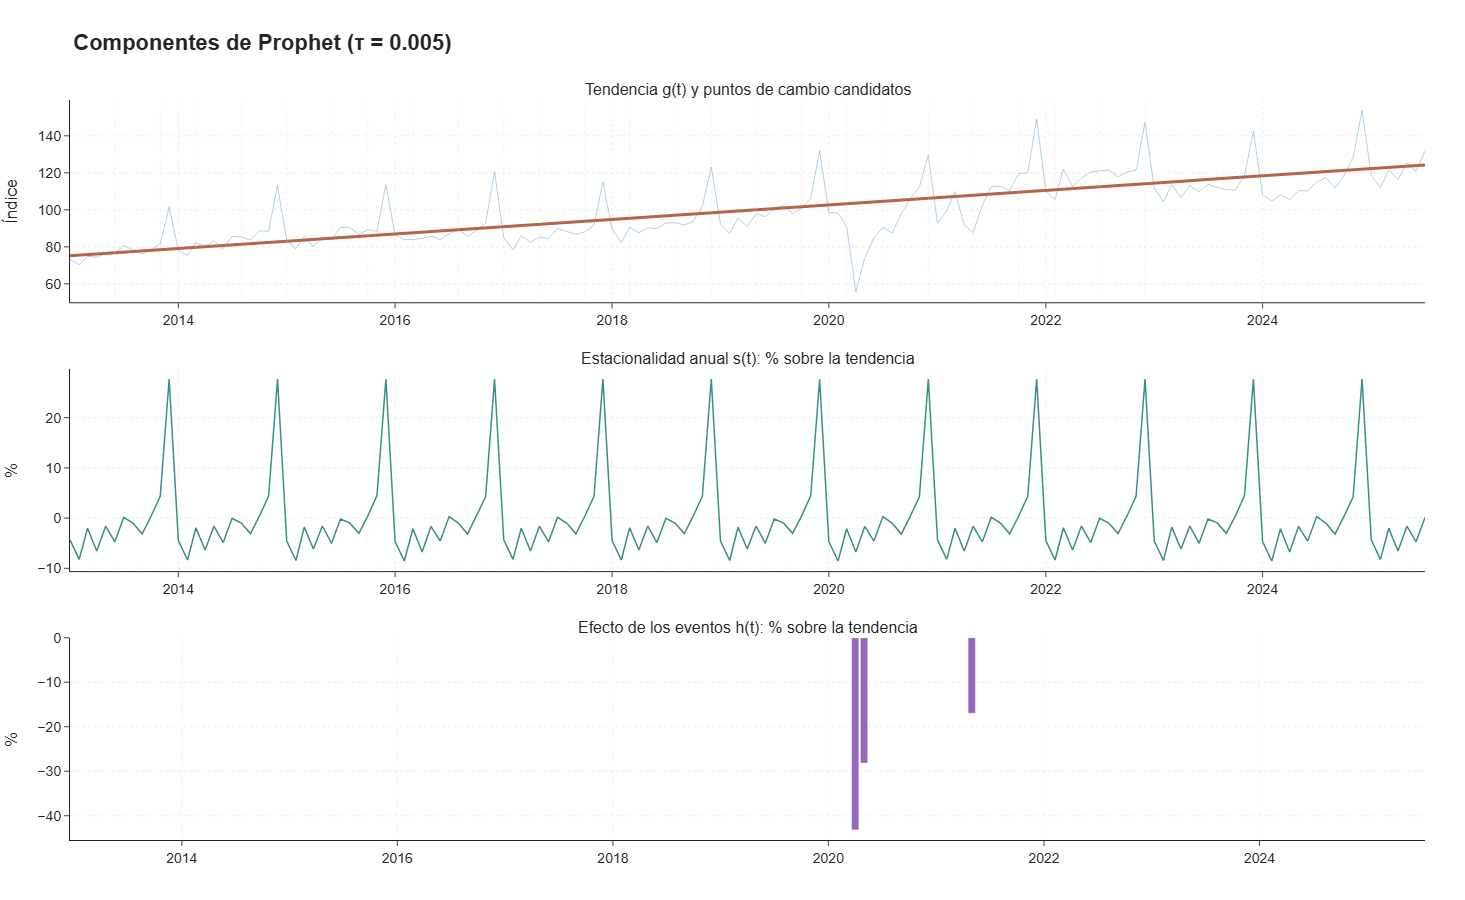

In [53]:
fig = make_subplots(rows=3, cols=1, vertical_spacing=0.09,
                    subplot_titles=("Tendencia g(t) y puntos de cambio candidatos",
                                    "Estacionalidad anual s(t): % sobre la tendencia",
                                    "Efecto de los eventos h(t): % sobre la tendencia"))
fig.add_trace(go.Scatter(x=train.index, y=train, line=dict(color="#1f77b4", width=1), opacity=0.35), 1, 1)
fig.add_trace(go.Scatter(x=comp["ds"], y=comp["trend"], line=dict(color=COLOR_PRO, width=3)), 1, 1)
for c in mod_pro.changepoints:
    fig.add_vline(x=c, line_dash="dot", line_color="lightgray", line_width=1, row=1, col=1)

fig.add_trace(go.Scatter(x=comp["ds"], y=100 * comp["yearly"], line=dict(color="#3A8F85", width=1.5)), 2, 1)
fig.add_hline(y=0, line_dash="dot", line_color="gray", row=2, col=1)

fig.add_trace(go.Bar(x=comp["ds"], y=100 * comp["holidays"], marker_color="#9467bd", width=25 * 86400000), 3, 1)

formato(fig, f"Componentes de Prophet (τ = {TAU})", alto=900, leyenda=False)
fig.update_yaxes(title_text="Índice", row=1, col=1)
fig.update_yaxes(title_text="%", row=2, col=1)
fig.update_yaxes(title_text="%", row=3, col=1)
guardar_figura(fig, "00_prophet_componentes")
fig.show()

### Lectura de los componentes

- **Tendencia y puntos de cambio:** las líneas grises marcan los 25 puntos candidatos, pero con $\tau = 0{,}005$ todos los cambios de pendiente quedan **prácticamente en cero** (máximo $|\delta_j| \approx 2\times10^{-4}$). La tendencia es **una sola recta** de 2013 a 2025, que crece ≈ **3,3 % anual**. Prophet "decide" que, a largo plazo, las ventas del comercio crecen a un ritmo estable y que el auge y la desaceleración fueron episodios, no cambios de régimen.
- **Estacionalidad:** diciembre ≈ **+28 %** sobre la tendencia, muy cerca del 29 % de la exploración. Los meses bajos (febrero, abril) quedan por debajo de cero.
- **Eventos:**

| Evento | Efecto Prophet | Efecto SARIMA |
|---|---|---|
| Confinamiento abr-2020 | ≈ −43 % | ≈ −36 % |
| Confinamiento may-2020 | ≈ −28 % | ≈ −17 % |
| Paro nacional may-2021 | ≈ −17 % | ≈ −15 % |

Dos modelos con lógicas distintas coinciden en el **orden** de los choques (abril de 2020 ≫ mayo de 2020 > mayo de 2021) y en su magnitud aproximada. Prophet los estima algo mayores porque los mide contra una tendencia rígida, mientras que SARIMA los mide contra lo que esperaba su propia dinámica de crecimiento.

---

### Pronóstico en el periodo de prueba

In [54]:
tabla = pro_df.assign(real=test, error=test - pro_df["pronostico"])
tabla.index = tabla.index.strftime("%Y-%m")
display(tabla.round(2))

pro_df.to_csv(DIR_PROC / "pronostico_prophet.csv", index_label="fecha")
registrar(f"Prophet (τ = {TAU})", pro_df)

,pronostico,inferior,superior,real,error
2025-08,123.340,111.480,134.890,131.060,7.720
2025-09,120.980,110.030,132.270,126.130,5.150
2025-10,125.670,114.210,137.370,129.310,3.640
2025-11,130.980,120.160,143.100,138.650,7.660
2025-12,160.760,148.800,171.750,167.930,7.170
2026-01,120.590,109.000,132.120,128.100,7.510
2026-02,115.990,104.370,127.680,123.430,7.440
2026-03,124.420,112.900,136.100,136.330,11.910
2026-04,119.090,107.620,130.640,130.720,11.630
2026-05,125.470,114.100,137.410,139.740,14.280


,MAE,RMSE,MAPE (%),MASE,Bias,Cobertura 95 % (%),Ancho medio
"SARIMA(1,0,1)×(0,1,1)₁₂",5.33,6.68,3.95,0.760,+5.04,100,23.2
Holt-Winters (mult. amortiguado),6.04,7.76,4.48,0.862,+5.68,100,42.1
Prophet (τ = 0.005),8.94,9.47,6.61,1.275,+8.94,67,23.1
Naïve estacional,12.32,12.58,9.14,1.757,+12.32,100,34.6


Guardada: reports\figures\00_prophet_prueba.png


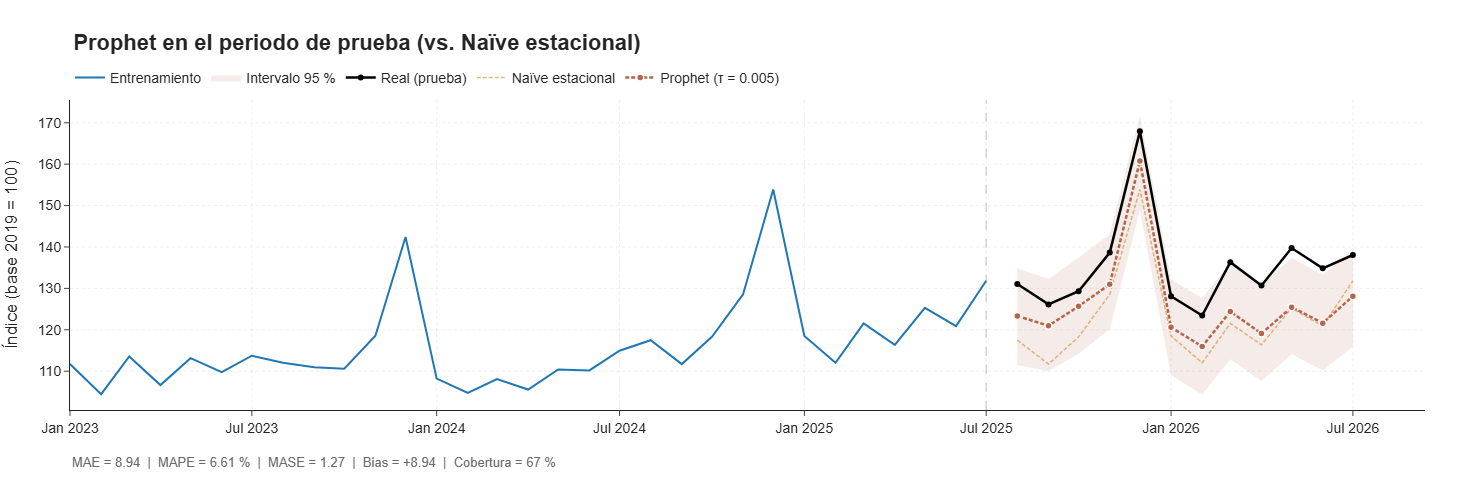

In [55]:
fig = go.Figure()
fig.add_trace(go.Scatter(x=train["2023":].index, y=train["2023":].values, mode="lines",
                         name="Entrenamiento", line=dict(color="#1f77b4", width=2)))
fig.add_trace(go.Scatter(x=list(pro_df.index) + list(pro_df.index[::-1]),
                         y=list(pro_df["superior"]) + list(pro_df["inferior"][::-1]),
                         fill="toself", fillcolor="rgba(181,101,74,0.13)", line=dict(width=0),
                         name="Intervalo 95 %", hoverinfo="skip"))
fig.add_trace(go.Scatter(x=test.index, y=test.values, mode="lines+markers", name="Real (prueba)",
                         line=dict(color="black", width=2.5), marker=dict(size=6)))
fig.add_trace(go.Scatter(x=naive.index, y=naive["pronostico"], mode="lines", name="Naïve estacional",
                         line=dict(color="#C98B2E", width=1.5, dash="4px,2px"), opacity=0.6))
fig.add_trace(go.Scatter(x=pro_df.index, y=pro_df["pronostico"], mode="lines+markers",
                         name=f"Prophet (τ = {TAU})",
                         line=dict(color=COLOR_PRO, width=2.5, dash="4px,2px"),
                         marker=dict(size=7, color=COLOR_PRO, line=dict(color="white", width=1.5))))
fig.add_vline(x=train.index.max(), line_dash="dash", line_color="gray", line_width=1.5)

r = resultados.loc[f"Prophet (τ = {TAU})"]
formato(fig, "Prophet en el periodo de prueba (vs. Naïve estacional)", eje_y="Índice (base 2019 = 100)")
fig.update_layout(margin=dict(b=90))
fig.add_annotation(text=f"MAE = {r['MAE']:.2f}  |  MAPE = {r['MAPE (%)']:.2f} %  |  MASE = {r['MASE']:.2f}  |  "
                        f"Bias = {r['Bias']:+.2f}  |  Cobertura = {r['Cobertura 95 % (%)']:.0f} %",
                   xref="paper", yref="paper", x=0, y=-0.2, showarrow=False,
                   font=dict(size=13, color="dimgray"), xanchor="left")
guardar_figura(fig, "00_prophet_prueba")
fig.show()

### Lectura

- **Subestima los 12 meses** (Bias = MAE ≈ 8,9): la tendencia rígida, que crece ≈ 3 % anual, no alcanza a ver un año de prueba que creció ≈ 10 %.
- **Frente al Naïve:** MASE ≈ **1,27** contra 1,76. Mejora poco, y queda detrás de Holt-Winters (≈ 0,86) y SARIMA (≈ 0,76).
- **Intervalo del 95 %:** cubre solo **8 de 12 meses** (≈ 67 %), aunque debería cubrir ≈ 95 %. Prophet calcula la incertidumbre de la tendencia simulando cambios de pendiente como los históricos, y con $\tau$ tan pequeño casi no hubo cambios: **subestima la incertidumbre**. Es una crítica conocida de Prophet cuando hay pocas observaciones (aquí, 151 meses).
- **Contraste con el backtesting:** en los años anteriores fue el mejor modelo (MASE ≈ 0,54); en la prueba, el peor después del Naïve. Prophet es **muy bueno cuando las ventas crecen a su ritmo histórico** y **malo cuando aceleran**. Es el modelo más inestable de los tres.

---
---

## __7. **Pronóstico de prueba:** generar predicciones con el modelo ingenuo estacional, SARIMA, Holt-Winters y Prophet para el periodo agosto de 2025 a julio de 2026.__


## Pronóstico de prueba: los cuatro modelos juntos

Cada modelo se estimó **solo con el entrenamiento** (ene-2013 a jul-2025) y pronosticó los mismos 12 meses de prueba (ago-2025 a jul-2026), **sin ver ningún dato de esa ventana**. Aquí los ponemos lado a lado frente a lo que realmente vendió el comercio:

| Modelo | Configuración | Qué supone sobre las ventas |
|---|---|---|
| Naïve estacional | $\hat Y_t = Y_{t-12}$ | Este año se vende igual que el año pasado |
| SARIMA | $(1,0,1)\times(0,1,1)_{12}$ + constante + intervenciones, sobre $\log Y_t$ | El crecimiento anual es persistente y regresa a ~3,9 % |
| Holt-Winters | Multiplicativo con tendencia amortiguada | Nivel × factor del mes, con un crecimiento que se apaga |
| Prophet | Multiplicativo, $\tau = 0{,}005$, con eventos | Tendencia recta (~3 % anual) × estacionalidad anual |

El **error** de cada mes es $e_t = Y_t - \hat Y_t$: **positivo** si el modelo se quedó corto (subestimó las ventas) y **negativo** si se pasó.

In [56]:
MODELOS = {
    "Naïve estacional": (naive, "#C98B2E"),
    "SARIMA": (sarima_df, "#3A8F85"),
    "Holt-Winters": (hw_df, "#7E6BA8"),
    "Prophet": (pro_df, "#B5654A"),
}

# Pronósticos lado a lado 
pronosticos = pd.DataFrame({"Real": test})
for nombre, (df, _) in MODELOS.items():
    pronosticos[nombre] = df["pronostico"].values

# Errores mes a mes (real − pronóstico) 
errores = pronosticos[list(MODELOS)].rsub(pronosticos["Real"], axis=0)

tabla = pronosticos.copy()
tabla.index = tabla.index.strftime("%Y-%m")
display(Markdown("**Pronósticos del índice (ago-2025 a jul-2026)**"))
display(tabla.round(1))

tabla_err = errores.copy()
tabla_err.index = tabla_err.index.strftime("%Y-%m")
display(Markdown("**Error mensual  e = real − pronóstico  (positivo = subestimó)**"))
display(tabla_err.style.format("{:+.1f}")
        .background_gradient(cmap="RdBu_r", vmin=-15, vmax=15, axis=None))

# Guardar
pronosticos.to_csv(DIR_PROC / "pronosticos_prueba.csv", index_label="fecha")
errores.to_csv(DIR_PROC / "errores_prueba.csv", index_label="fecha")

**Pronósticos del índice (ago-2025 a jul-2026)**

,Real,Naïve estacional,SARIMA,Holt-Winters,Prophet
fecha,,,,,
2025-08,131.100,117.500,129.300,129.400,123.300
2025-09,126.100,111.700,126.400,126.600,121.000
2025-10,129.300,118.300,130.800,131.000,125.700
2025-11,138.600,128.600,135.600,135.600,131.000
2025-12,167.900,153.900,166.700,166.600,160.800
2026-01,128.100,118.500,124.400,124.200,120.600
2026-02,123.400,112.000,119.400,118.900,116.000
2026-03,136.300,121.500,127.500,126.900,124.400
2026-04,130.700,116.400,121.000,118.300,119.100


**Error mensual  e = real − pronóstico  (positivo = subestimó)**

,Naïve estacional,SARIMA,Holt-Winters,Prophet
fecha,,,,
2025-08,+13.6,+1.7,+1.7,+7.7
2025-09,+14.4,-0.3,-0.5,+5.1
2025-10,+11.0,-1.5,-1.7,+3.6
2025-11,+10.1,+3.1,+3.0,+7.7
2025-12,+14.0,+1.3,+1.3,+7.2
2026-01,+9.6,+3.7,+3.9,+7.5
2026-02,+11.4,+4.0,+4.5,+7.4
2026-03,+14.8,+8.8,+9.4,+11.9
2026-04,+14.3,+9.8,+12.4,+11.6


In [59]:
# Paleta categórica validada (daltonismo y contraste): un color fijo por modelo
MODELOS = {
    "SARIMA":           (sarima_df, "#2a78d6"),   # azul
    "Holt-Winters":     (hw_df,     "#eb6834"),   # naranja
    "Prophet":          (pro_df,    "#1baf7a"),   # verde agua
    "Naïve estacional": (naive,     "#eda100"),   # ámbar
}
TINTA, TINTA_2, GRIS = "#0b0b0b", "#52514e", "#b9b8b3"
FONDO = "#fcfcfb"

# Orden de los paneles: del mejor al peor MASE
orden = sorted(MODELOS, key=lambda n: metricas(test, MODELOS[n][0]["pronostico"])["MASE"])

MES_ES = ["ene", "feb", "mar", "abr", "may", "jun", "jul", "ago", "sep", "oct", "nov", "dic"]
def etiqueta_mes(d, con_anio=True):
    return f"{MES_ES[d.month - 1]}<br>{d:%Y}" if con_anio else MES_ES[d.month - 1]

def rgba(hex_color, a):
    h = hex_color.lstrip("#")
    return f"rgba({int(h[0:2], 16)},{int(h[2:4], 16)},{int(h[4:6], 16)},{a})"

Guardada: reports\figures\00_pronosticos_prueba.png


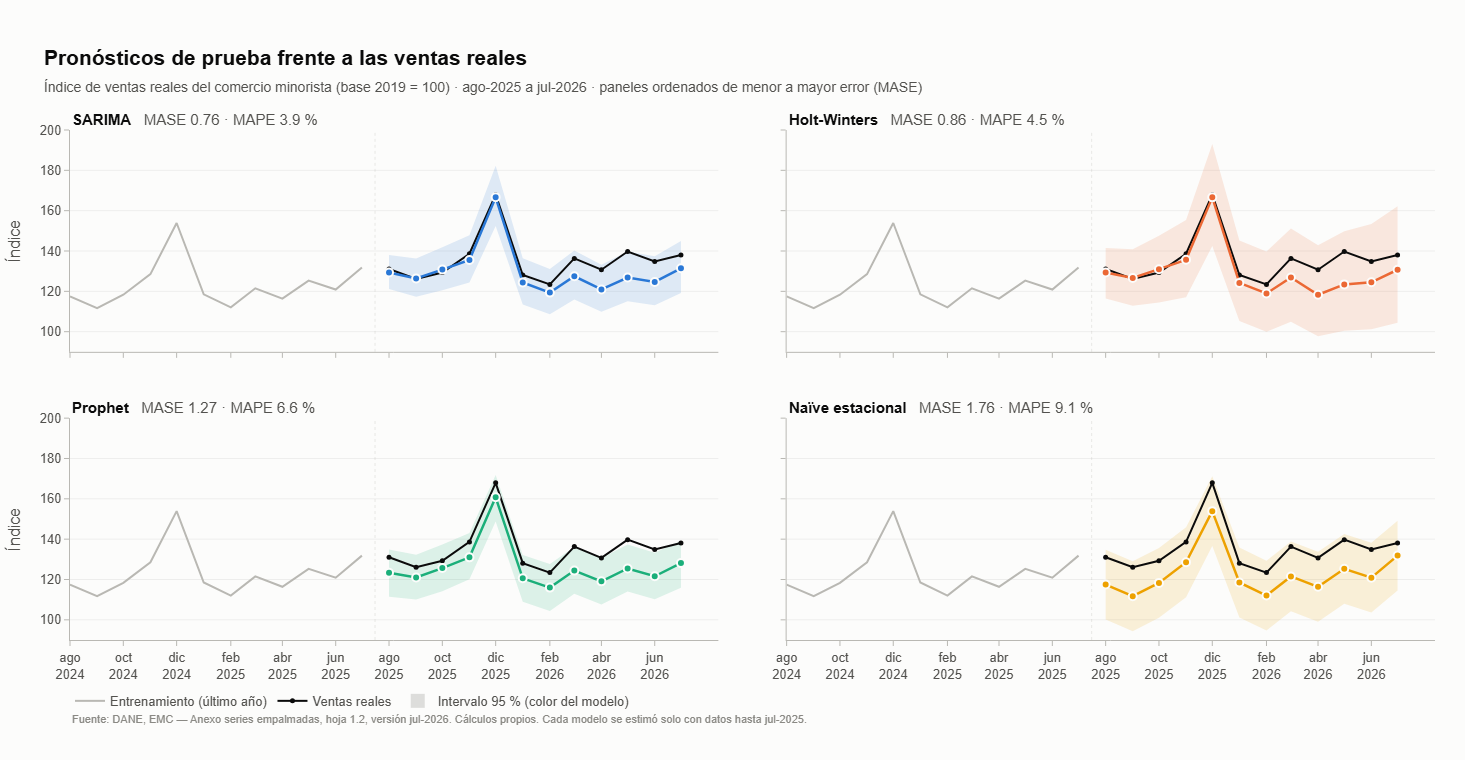

In [60]:
contexto = train[-12:]                                   # último año del entrenamiento
titulos = []
for n in orden:
    m = metricas(test, MODELOS[n][0]["pronostico"])
    titulos.append(f"<b>{n}</b>   <span style='color:{TINTA_2}'>MASE {m['MASE']:.2f} · MAPE {m['MAPE (%)']:.1f} %</span>")

fig = make_subplots(rows=2, cols=2, shared_xaxes=True, shared_yaxes=True,
                    subplot_titles=titulos, vertical_spacing=0.13, horizontal_spacing=0.05)

for i, n in enumerate(orden):
    df, color = MODELOS[n]
    fila, col = i // 2 + 1, i % 2 + 1
    primero = i == 0
    # Contexto: último año de entrenamiento
    fig.add_trace(go.Scatter(x=contexto.index, y=contexto.values, mode="lines",
                             line=dict(color=GRIS, width=2), name="Entrenamiento (último año)",
                             legendgroup="ctx", showlegend=primero,
                             hovertemplate="%{x|%b %Y}<br>%{y:.1f}<extra>Entrenamiento</extra>"), fila, col)
    # Intervalo del 95 %
    fig.add_trace(go.Scatter(x=list(df.index) + list(df.index[::-1]),
                             y=list(df["superior"]) + list(df["inferior"][::-1]),
                             fill="toself", fillcolor=rgba(color, 0.14), line=dict(width=0),
                             hoverinfo="skip", showlegend=False), fila, col)
    # Real
    fig.add_trace(go.Scatter(x=test.index, y=test.values, mode="lines+markers",
                             line=dict(color=TINTA, width=2), marker=dict(size=5, color=TINTA),
                             name="Ventas reales", legendgroup="real", showlegend=primero,
                             hovertemplate="%{x|%b %Y}<br>Real: %{y:.1f}<extra></extra>"), fila, col)
    # Pronóstico del modelo
    fig.add_trace(go.Scatter(x=df.index, y=df["pronostico"], mode="lines+markers",
                             line=dict(color=color, width=2.5),
                             marker=dict(size=8, color=color, line=dict(color=FONDO, width=2)),
                             name=n, showlegend=False,
                             customdata=np.c_[df["inferior"], df["superior"]],
                             hovertemplate=(f"%{{x|%b %Y}}<br>{n}: %{{y:.1f}}"
                                            "<br>IC 95 %: %{customdata[0]:.1f} – %{customdata[1]:.1f}<extra></extra>")),
                  fila, col)
    fig.add_vline(x=train.index.max() + pd.Timedelta(days=15), line_width=1, line_dash="dot",
                  line_color=GRIS, row=fila, col=col)

# Entrada de leyenda neutra para el intervalo
fig.add_trace(go.Scatter(x=[None], y=[None], mode="markers", name="Intervalo 95 % (color del modelo)",
                         marker=dict(size=14, symbol="square", color="rgba(82,81,78,0.18)")), 1, 1)

fig.update_layout(
    template="simple_white", width=1400, height=760, paper_bgcolor=FONDO, plot_bgcolor=FONDO,
    font=dict(family="Arial", size=13, color=TINTA_2),
    title=dict(text="<b>Pronósticos de prueba frente a las ventas reales</b>"
                    f"<br><span style='font-size:14px;color:{TINTA_2}'>Índice de ventas reales del comercio minorista "
                    "(base 2019 = 100) · ago-2025 a jul-2026 · paneles ordenados de menor a mayor error (MASE)</span>",
               x=0.03, xanchor="left", font=dict(size=21, color=TINTA)),
    legend=dict(orientation="h", yanchor="top", y=-0.09, xanchor="left", x=0.0, font=dict(size=13)),
    margin=dict(l=70, r=30, t=130, b=120), hovermode="x unified",
)
# Títulos de panel alineados a la izquierda de cada panel
for a, ax in zip(fig.layout.annotations[:4], ["xaxis", "xaxis2", "xaxis3", "xaxis4"]):
    a.update(x=fig.layout[ax].domain[0], xanchor="left", font=dict(size=15, color=TINTA))
# Meses en español, cada 2 meses
ticks = pd.date_range(contexto.index.min(), test.index.max(), freq="2MS")
fig.update_xaxes(showgrid=False, ticks="outside", tickvals=ticks, ticktext=[etiqueta_mes(d) for d in ticks],
                 linecolor=GRIS, tickcolor=GRIS)
y_min = min(contexto.min(), min(MODELOS[n][0]["inferior"].min() for n in orden))
y_max = max(test.max(), max(MODELOS[n][0]["superior"].max() for n in orden))
fig.update_yaxes(range=[np.floor(y_min / 10) * 10, np.ceil(y_max / 10) * 10])
fig.update_yaxes(showgrid=True, gridcolor="rgba(0,0,0,0.06)", zeroline=False, linecolor=GRIS,
                 tickcolor=GRIS, ticks="outside")
fig.update_yaxes(title_text="Índice", col=1)
fig.add_annotation(text="Fuente: DANE, EMC — Anexo series empalmadas, hoja 1.2, versión jul-2026. Cálculos propios. "
                        "Cada modelo se estimó solo con datos hasta jul-2025.",
                   xref="paper", yref="paper", x=0, y=-0.17, showarrow=False, xanchor="left",
                   font=dict(size=11, color="#8a8984"))
guardar_figura(fig, "00_pronosticos_prueba")
fig.show()

Guardada: reports\figures\00_errores_prueba.png


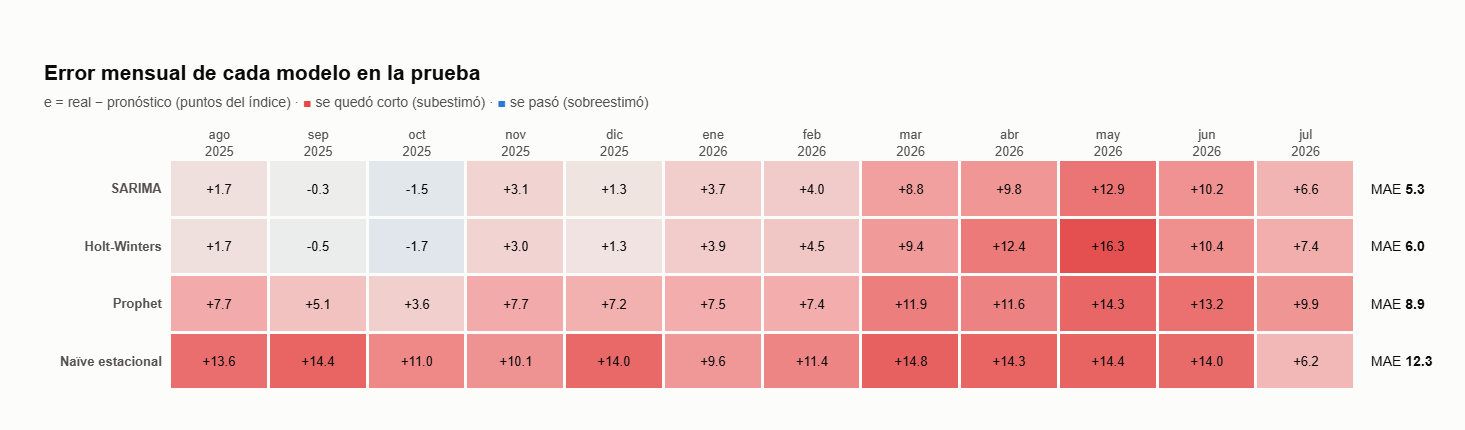

In [61]:
err = pd.DataFrame({n: test.values - MODELOS[n][0]["pronostico"].values for n in orden}, index=test.index).T
lim = np.ceil(np.abs(err.values).max())
meses = [etiqueta_mes(d) for d in err.columns]
etiquetas_y = [f"<b>{n}</b>  " for n in orden]
mae = err.abs().mean(axis=1)

# Escala divergente: azul (se pasó) – gris neutro (0) – rojo (se quedó corto)
escala = [[0.0, "#2a78d6"], [0.25, "#9dc1ee"], [0.5, "#f0efec"], [0.75, "#f2a4a3"], [1.0, "#e34948"]]
fig = go.Figure(go.Heatmap(
    z=err.values, x=meses, y=etiquetas_y, zmin=-lim, zmax=lim, colorscale=escala,
    xgap=3, ygap=3, text=err.values, texttemplate="%{text:+.1f}",
    textfont=dict(size=13, color=TINTA), showscale=False,
    hovertemplate="%{y}<br>%{x}<br>Error: %{z:+.1f} puntos<extra></extra>"))
# MAE a la derecha de cada fila
for n, et in zip(orden, etiquetas_y):
    fig.add_annotation(x=1.0, xref="paper", xanchor="left", xshift=14, y=et, text=f"MAE <b>{mae[n]:.1f}</b>",
                       showarrow=False, font=dict(size=14, color=TINTA))
fig.update_layout(
    template="simple_white", width=1400, height=430, paper_bgcolor=FONDO, plot_bgcolor=FONDO,
    font=dict(family="Arial", size=13, color=TINTA_2),
    title=dict(text="<b>Error mensual de cada modelo en la prueba</b>"
                    f"<br><span style='font-size:14px;color:{TINTA_2}'>e = real − pronóstico (puntos del índice) · "
                    "<span style='color:#e34948'>■</span> se quedó corto (subestimó) · "
                    "<span style='color:#2a78d6'>■</span> se pasó (sobreestimó)</span>",
               x=0.03, xanchor="left", font=dict(size=21, color=TINTA)),
    margin=dict(l=170, r=110, t=160, b=40),
)
fig.update_xaxes(side="top", showline=False, ticks="")
fig.update_yaxes(autorange="reversed", showline=False, ticks="")
guardar_figura(fig, "00_errores_prueba")
fig.show()

### Lectura de los pronósticos de prueba

**1. Todos los modelos aciertan la forma del año; fallan en el nivel.**
Los cuatro paneles reproducen el patrón de las ventas: bajada en septiembre, subida en noviembre, el **pico de diciembre** y la caída de enero y febrero. La estacionalidad del comercio es tan regular que cualquier modelo que la incluya la captura. La diferencia entre modelos está en **qué tan alto** ubican ese patrón.

**2. Casi todos los errores son de subestimación.**
De las 48 celdas del mapa de calor, **44 son rojas**: los modelos esperaban vender menos de lo que realmente se vendió. Solo hay cuatro errores negativos, todos pequeños (menos de 2 puntos): SARIMA y Holt-Winters en septiembre y octubre de 2025. La causa de fondo es que el periodo de prueba creció ≈ 10 % frente al año anterior, por encima del ritmo de largo plazo (~4 %) que aprendieron los modelos.

**3. SARIMA y Holt-Winters: excelentes hasta febrero, cortos desde marzo.**

| Tramo | SARIMA | Holt-Winters | Lectura |
|---|---|---|---|
| Ago–dic 2025 | −1,5 a +3,1 | −1,7 a +3,0 | Errores de menos del 2,5 %. **Diciembre de 2025**, el mes clave del comercio, se pronostica con un error de **1,2–1,3 puntos (< 1 %)**. |
| Ene–feb 2026 | +3,7 a +4,1 | +3,9 a +4,5 | Empiezan a quedarse cortos. |
| Mar–jul 2026 | +6,7 a +12,9 | +7,4 a **+16,3** | La serie acelera y los modelos no la siguen. |

- Hasta febrero de 2026 los dos modelos son **casi idénticos** (diferencias de menos de 0,6 puntos): ambos arrancan desde el nivel más reciente de las ventas y le aplican el mismo patrón estacional.
- Desde marzo se separan: **Holt-Winters se queda más corto** (16,3 frente a 12,9 en mayo). Su tendencia está prácticamente apagada, así que proyecta ventas planas. SARIMA conserva parte del crecimiento reciente por su componente autorregresivo ($\phi_1 \approx 0{,}87$), que se va apagando.

**4. Prophet: arranca por debajo y nunca alcanza a la serie.**
Sus errores son positivos desde el primer mes (+3,6 a +7,7 en 2025) y crecen hasta +14,3 en mayo de 2026. Su tendencia es una recta estimada con toda la historia (~3 % anual) que pasa **por debajo del nivel que alcanzaron las ventas en 2025**. Por eso falla de forma sistemática y no solo cuando la serie acelera. En el panel, la franja verde **no contiene** las ventas reales de marzo a junio de 2026: su intervalo del 95 % se queda corto en 4 de 12 meses.

**5. Naïve estacional: el error refleja el crecimiento del año.**
Sus errores son altos y bastante parejos todo el año (+9,6 a +14,8). Es justo lo esperado: copia las ventas del año anterior, así que su error mide **cuánto crecieron las ventas** de un año a otro. El único mes con error menor es julio de 2026 (+6,2), porque julio de 2025 ya había sido un mes alto.

**6. El tramo difícil: marzo a junio de 2026.**
Es la zona más roja del mapa para todos los modelos, y **mayo de 2026** es el mes con mayor error para SARIMA, Holt-Winters y Prophet. Las ventas reales subieron con fuerza (136,3 en marzo y 139,7 en mayo) por encima del ritmo histórico. Hay un posible efecto de calendario: en 2026 la Semana Santa cayó a comienzos de abril, así que marzo tuvo todos sus días hábiles. Pero ningún modelo incluye variables de calendario, así que esto queda como una hipótesis.

**7. Intervalos de predicción (paneles).**
- **SARIMA:** la franja contiene las ventas reales en los 12 meses y es la **más angosta**. Es la incertidumbre más útil para planear.
- **Holt-Winters y Naïve:** también contienen todos los valores, pero con franjas muy anchas. Cubren por ser amplias, no por ser precisas.
- **Prophet:** su franja es angosta pero **falla**: deja fuera 4 meses. Subestima su propia incertidumbre.

**Implicación para el negocio.** Un comerciante que en julio de 2025 hubiera usado SARIMA o Holt-Winters para planear inventario y personal de fin de año habría acertado diciembre con un error menor al 1 %. Para el primer semestre de 2026, todos los modelos habrían recomendado **comprar de menos**: si el consumo mantiene un ritmo de crecimiento por encima de lo histórico, estos modelos univariados no lo anticipan, porque no ven las variables que lo explican (ingresos, tasas de interés, confianza del consumidor). El paso 8 cuantifica estas diferencias con MAE, RMSE, MAPE y MASE.

---
---

### __8. **Evaluación:** comparar el desempeño de SARIMA, Holt-Winters y Prophet frente al modelo ingenuo estacional mediante MAE, RMSE, MAPE y MASE, verificando si los modelos más complejos mejoran realmente la capacidad predictiva respecto al modelo de referencia.__

## Evaluación: ¿los modelos complejos superan al Naïve estacional?

Comparamos los tres modelos contra el Naïve estacional con las cuatro métricas del enunciado, sobre los mismos 12 meses de prueba (ago-2025 a jul-2026):

| Métrica | Fórmula | Qué mide en las ventas |
|---|---|---|
| **MAE** | $\frac{1}{n}\sum\lvert e_t\rvert$ | Cuántos puntos del índice se equivoca el modelo en un mes típico |
| **RMSE** | $\sqrt{\frac{1}{n}\sum e_t^2}$ | Igual que el MAE, pero castiga más los errores grandes (por ejemplo, fallar diciembre) |
| **MAPE** | $\frac{100}{n}\sum\lvert e_t/Y_t\rvert$ | Error en porcentaje de las ventas: la métrica más fácil de comunicar |
| **MASE** | $\dfrac{\text{MAE}}{\frac{1}{T-12}\sum_{t=13}^{T}\lvert Y_t - Y_{t-12}\rvert}$ | Error relativo al Naïve estacional **dentro del entrenamiento**: < 1 = mejor que esa referencia |

Además calculamos:

- **Reducción del error frente al Naïve:** $100\,(1 - \text{métrica}_{\text{modelo}} / \text{métrica}_{\text{Naïve}})$.
- **Meses en que supera al Naïve:** en cuántos de los 12 meses el error absoluto del modelo fue menor que el del Naïve.

**¿Mejora realmente?** Un solo año de prueba puede favorecer a un modelo por azar. Por eso verificamos también la ventaja en los **5 orígenes de backtesting** que ya usamos para elegir Holt-Winters y Prophet. En total son 6 pronósticos a 12 meses hechos desde distintos momentos.

In [62]:
REF = "Naïve estacional"

tabla_eval = pd.DataFrame({n: metricas(test, MODELOS[n][0]["pronostico"]) for n in MODELOS}).T
for m in ["MAE", "RMSE", "MAPE (%)"]:
    tabla_eval[f"Mejora {m.split()[0]} vs Naïve (%)"] = 100 * (1 - tabla_eval[m] / tabla_eval.loc[REF, m])

# Meses (de 12) en que el error absoluto del modelo es menor que el del Naïve
err_abs = pd.DataFrame({n: (test - MODELOS[n][0]["pronostico"]).abs() for n in MODELOS})
tabla_eval["Meses que supera al Naïve"] = [f"{(err_abs[n] < err_abs[REF]).sum()} / 12" if n != REF else "—"
                                           for n in tabla_eval.index]
tabla_eval = tabla_eval.loc[orden]

display(tabla_eval.style
        .format({"MAE": "{:.2f}", "RMSE": "{:.2f}", "MAPE (%)": "{:.2f}", "MASE": "{:.3f}", "Bias": "{:+.2f}",
                 "Mejora MAE vs Naïve (%)": "{:.1f}", "Mejora RMSE vs Naïve (%)": "{:.1f}",
                 "Mejora MAPE vs Naïve (%)": "{:.1f}"})
        .map(lambda v: "color:#2a78d6; font-weight:bold" if v < 1 else "color:#e34948; font-weight:bold",
             subset=["MASE"])
        .set_caption(f"Desempeño en prueba (ago-2025 a jul-2026) · escala MASE = {ESCALA_MASE:.3f}"))
tabla_eval.to_csv(DIR_PROC / "evaluacion_prueba.csv", index_label="Modelo")

,MAE,RMSE,MAPE (%),MASE,Bias,Mejora MAE vs Naïve (%),Mejora RMSE vs Naïve (%),Mejora MAPE vs Naïve (%),Meses que supera al Naïve
SARIMA,5.33,6.68,3.95,0.760,+5.04,56.8,47.0,56.8,11 / 12
Holt-Winters,6.04,7.76,4.48,0.862,+5.68,51.0,38.3,51.0,10 / 12
Prophet,8.94,9.47,6.61,1.275,+8.94,27.4,24.7,27.7,11 / 12
Naïve estacional,12.32,12.58,9.14,1.757,+12.32,0.0,0.0,0.0,—


Guardada: reports\figures\00_evaluacion_prueba.png


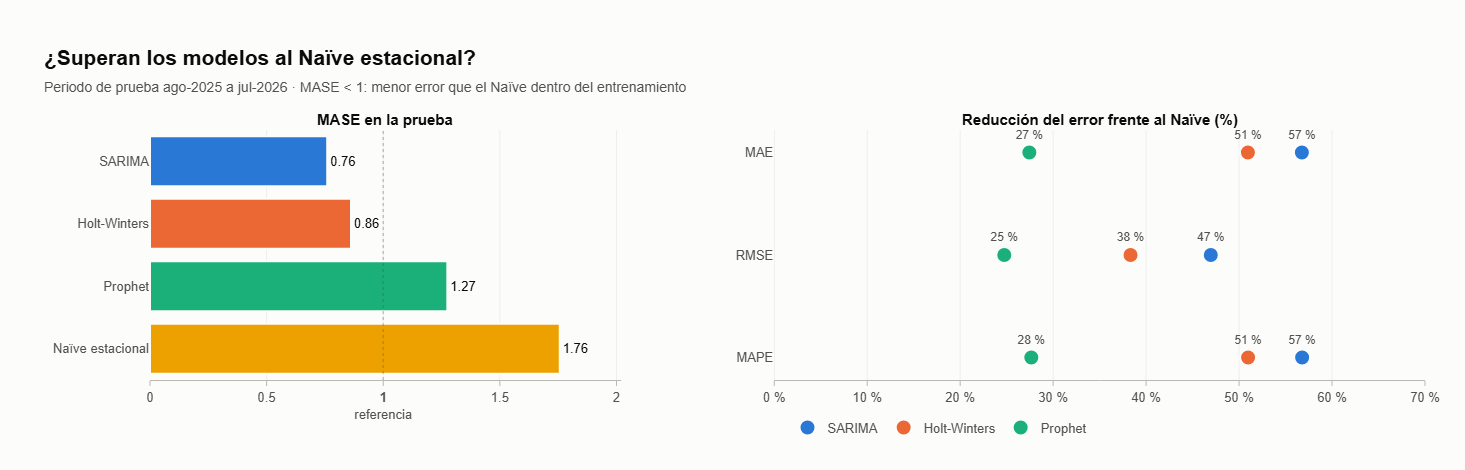

In [63]:
fig = make_subplots(rows=1, cols=2, column_widths=[0.42, 0.58], horizontal_spacing=0.12,
                    subplot_titles=("<b>MASE en la prueba</b>", "<b>Reducción del error frente al Naïve (%)</b>"))

# Panel izquierdo: MASE por modelo
mods = list(reversed(orden))
fig.add_trace(go.Bar(y=mods, x=[tabla_eval.loc[n, "MASE"] for n in mods], orientation="h",
                     marker=dict(color=[MODELOS[n][1] for n in mods], line=dict(color=FONDO, width=2)),
                     text=[f"{tabla_eval.loc[n, 'MASE']:.2f}" for n in mods], textposition="outside",
                     textfont=dict(color=TINTA, size=13), cliponaxis=False, showlegend=False,
                     hovertemplate="%{y}: MASE %{x:.3f}<extra></extra>"), 1, 1)
fig.add_vline(x=1, line_dash="dot", line_color=TINTA_2, line_width=1.5, row=1, col=1)

# Panel derecho: % de reducción del error por métrica
metr = ["MAE", "RMSE", "MAPE"]
for n in [o for o in orden if o != REF]:
    vals = [tabla_eval.loc[n, f"Mejora {m} vs Naïve (%)"] for m in metr]
    fig.add_trace(go.Scatter(x=vals, y=metr, mode="markers+text", name=n,
                             marker=dict(size=16, color=MODELOS[n][1], line=dict(color=FONDO, width=2)),
                             text=[f"{v:.0f} %" for v in vals], textposition="top center",
                             textfont=dict(size=12, color=TINTA_2),
                             hovertemplate=f"{n}<br>%{{y}}: %{{x:.1f}} % menos error<extra></extra>"), 1, 2)
fig.add_vline(x=0, line_color=GRIS, line_width=1, row=1, col=2)

fig.update_layout(template="simple_white", width=1400, height=470, paper_bgcolor=FONDO, plot_bgcolor=FONDO,
                  font=dict(family="Arial", size=13, color=TINTA_2),
                  title=dict(text="<b>¿Superan los modelos al Naïve estacional?</b>"
                                  f"<br><span style='font-size:14px;color:{TINTA_2}'>Periodo de prueba ago-2025 a jul-2026 · "
                                  "MASE < 1: menor error que el Naïve dentro del entrenamiento</span>",
                             x=0.03, xanchor="left", font=dict(size=21, color=TINTA)),
                  legend=dict(orientation="h", yanchor="top", y=-0.13, xanchor="left", x=0.5),
                  margin=dict(l=150, r=40, t=130, b=90))
for a in fig.layout.annotations[:2]:
    a.update(font=dict(size=15, color=TINTA))
fig.update_xaxes(showgrid=True, gridcolor="rgba(0,0,0,0.06)", zeroline=False, linecolor=GRIS, tickcolor=GRIS)
fig.update_xaxes(range=[0, max(2, tabla_eval["MASE"].max() * 1.15)], tickvals=[0, 0.5, 1, 1.5, 2],
                 ticktext=["0", "0.5", "<b>1</b><br>referencia", "1.5", "2"], row=1, col=1)
fig.update_xaxes(range=[0, 70], ticksuffix=" %", row=1, col=2)
fig.update_yaxes(showline=False, ticks="")
fig.update_yaxes(categoryorder="array", categoryarray=list(reversed(metr)), row=1, col=2)
guardar_figura(fig, "00_evaluacion_prueba")
fig.show()

### ¿La ventaja se sostiene en otros años?

Usamos la función `backtesting()` del paso de Holt-Winters con los mismos 5 orígenes (jul-2022, ene-2023, jul-2023, ene-2024 y jul-2024) para el Naïve y SARIMA. Holt-Winters y Prophet ya tienen su backtesting hecho. La prueba se agrega como sexto origen (jul-2025).

In [64]:
def ajustar_naive(serie, h=12):
    """Naïve estacional con la misma firma que ajustar_hw/ajustar_prophet."""
    idx = pd.date_range(serie.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq="MS")
    return pd.DataFrame({"pronostico": serie.values[-12:][:h]}, index=idx), None

def ajustar_sarima(serie, h=12):
    """SARIMA(1,0,1)x(0,1,1)12 + constante + intervenciones, sobre log(Y)."""
    X = matriz_intervencion(serie.index)
    X = X.loc[:, X.sum() > 0]                                  # solo eventos presentes en esa ventana
    m = SARIMAX(np.log(serie), exog=X, order=(1, 0, 1), seasonal_order=(0, 1, 1, 12),
                trend="c").fit(disp=False, maxiter=500)
    fc = m.get_forecast(h, exog=np.zeros((h, X.shape[1])))
    idx = pd.date_range(serie.index[-1] + pd.offsets.MonthBegin(1), periods=h, freq="MS")
    return pd.DataFrame({"pronostico": np.exp(fc.predicted_mean.values)}, index=idx), m

bt_naive = backtesting(ajustar_naive)
bt_sar = backtesting(ajustar_sarima)

mase_origenes = pd.DataFrame({
    "SARIMA": bt_sar["MASE"],
    "Holt-Winters": bt_hw[ELEGIDO_HW]["MASE"],
    "Prophet": bt_pro[TAU]["MASE"],
    "Naïve estacional": bt_naive["MASE"],
}).T
mase_origenes["2025-07 (prueba)"] = [tabla_eval.loc[n, "MASE"] for n in mase_origenes.index]
mase_origenes = mase_origenes.loc[orden]

resumen_bt = pd.DataFrame({
    "MASE prom. 5 orígenes": mase_origenes.iloc[:, :5].mean(axis=1),
    "MASE prom. 6 orígenes": mase_origenes.mean(axis=1),
    "Orígenes que supera al Naïve": [f"{(mase_origenes.loc[n] < mase_origenes.loc[REF]).sum()} / 6" if n != REF else "—"
                                     for n in mase_origenes.index],
    "Orígenes con MASE < 1": [f"{(mase_origenes.loc[n] < 1).sum()} / 6" for n in mase_origenes.index],
})
display(mase_origenes.round(2))
display(resumen_bt.round(3))
mase_origenes.to_csv(DIR_PROC / "mase_por_origen.csv")

,2022-07,2023-01,2023-07,2024-01,2024-07,2025-07 (prueba)
SARIMA,0.520,0.690,0.780,0.350,0.560,0.760
Holt-Winters,0.790,0.530,0.300,0.660,1.240,0.860
Prophet,0.530,0.510,0.650,0.370,0.640,1.270
Naïve estacional,0.680,0.880,0.580,0.680,1.480,1.760


,MASE prom. 5 orígenes,MASE prom. 6 orígenes,Orígenes que supera al Naïve,Orígenes con MASE < 1
SARIMA,0.578,0.608,5 / 6,6 / 6
Holt-Winters,0.703,0.730,5 / 6,5 / 6
Prophet,0.539,0.662,5 / 6,5 / 6
Naïve estacional,0.862,1.011,—,4 / 6


Guardada: reports\figures\00_evaluacion_origenes.png


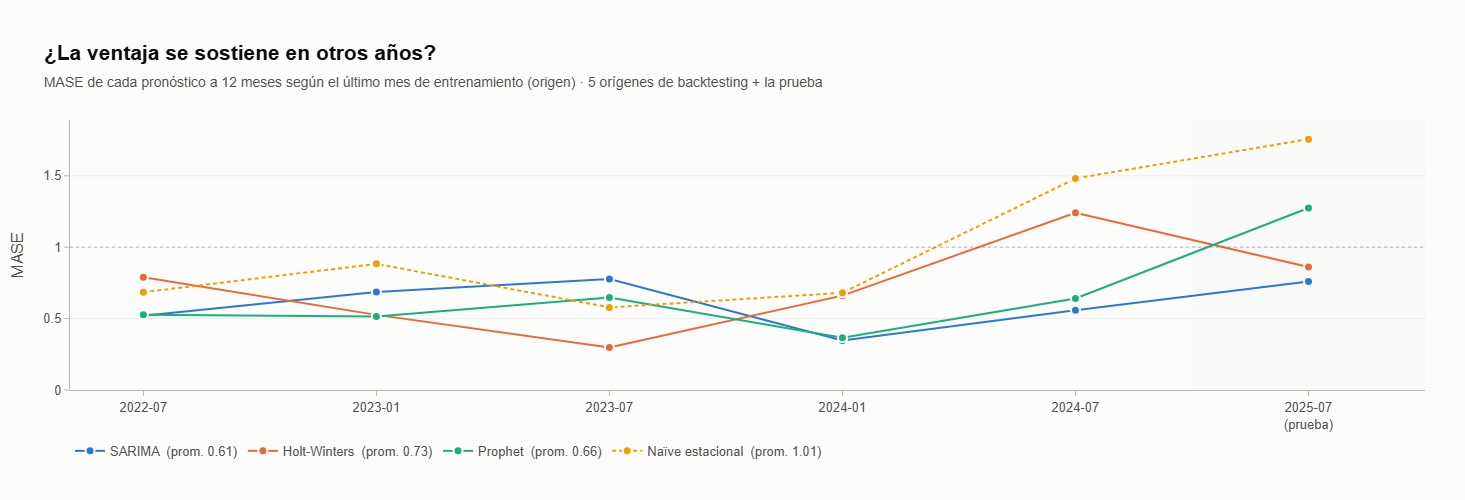

In [65]:
etiq = [f"{pd.Timestamp(o):%Y-%m}" for o in ORIGENES] + ["2025-07<br>(prueba)"]
fig = go.Figure()
fig.add_vrect(x0=4.5, x1=5.5, fillcolor="rgba(0,0,0,0.04)", line_width=0, layer="below")   # zona de la prueba
fig.add_hline(y=1, line_dash="dot", line_color=TINTA_2, line_width=1.2)
for n in orden:
    vals = mase_origenes.loc[n].values
    es_ref = n == REF
    fig.add_trace(go.Scatter(x=etiq, y=vals, mode="lines+markers", name=f"{n}  (prom. {vals.mean():.2f})",
                             line=dict(color=MODELOS[n][1], width=2, dash="4px,3px" if es_ref else "solid"),
                             marker=dict(size=9, color=MODELOS[n][1], line=dict(color=FONDO, width=2)),
                             hovertemplate=f"{n}<br>Origen %{{x}}<br>MASE %{{y:.2f}}<extra></extra>"))
fig.update_layout(template="simple_white", width=1400, height=500, paper_bgcolor=FONDO, plot_bgcolor=FONDO,
                  font=dict(family="Arial", size=13, color=TINTA_2),
                  title=dict(text="<b>¿La ventaja se sostiene en otros años?</b>"
                                  f"<br><span style='font-size:14px;color:{TINTA_2}'>MASE de cada pronóstico a 12 meses según "
                                  "el último mes de entrenamiento (origen) · 5 orígenes de backtesting + la prueba</span>",
                             x=0.03, xanchor="left", font=dict(size=21, color=TINTA)),
                  legend=dict(orientation="h", yanchor="top", y=-0.17, xanchor="left", x=0),
                  margin=dict(l=70, r=40, t=120, b=110))
fig.update_xaxes(type="category", showgrid=False, linecolor=GRIS, tickcolor=GRIS)
fig.update_yaxes(showgrid=True, gridcolor="rgba(0,0,0,0.06)", zeroline=False, linecolor=GRIS, tickcolor=GRIS,
                 title_text="MASE", rangemode="tozero")
guardar_figura(fig, "00_evaluacion_origenes")
fig.show()

### Lectura

**1. En la prueba, SARIMA y Holt-Winters superan con claridad al Naïve; Prophet, en menor medida.**

| Modelo | MAE | RMSE | MAPE | MASE | Reducción del MAE | Meses que gana |
|---|---|---|---|---|---|---|
| **SARIMA** | 5,33 | 6,68 | 3,95 % | **0,76** | **57 %** | 11 / 12 |
| Holt-Winters | 6,04 | 7,76 | 4,48 % | 0,86 | 51 % | 10 / 12 |
| Prophet | 8,94 | 9,47 | 6,61 % | 1,27 | 27 % | 11 / 12 |
| Naïve estacional | 12,32 | 12,58 | 9,14 % | 1,76 | — | — |

- **SARIMA** se equivoca en promedio **3,9 % de las ventas** de cada mes, frente a 9,1 % del Naïve: reduce el error a menos de la mitad y gana en 11 de 12 meses. Solo pierde en julio de 2026, por 0,4 puntos.
- **Holt-Winters** reduce el error a la mitad, pero gana un poco menos en RMSE (38 %) porque sus errores grandes de abril y mayo de 2026 (12 y 16 puntos) pesan más en esa métrica.
- **Prophet** reduce el error en 25–28 % y gana en 11 de 12 meses, pero por márgenes pequeños. Su MASE (1,27) indica que, en este año, se equivocó más que el Naïve en su promedio histórico.

**2. ¿Por qué todos tienen Bias positivo?** El Bias es casi igual al MAE en todos los modelos: prácticamente todos sus errores son de subestimación. Ninguno anticipó que el consumo crecería ≈ 10 % en el periodo de prueba. Es una limitación común a los modelos univariados, no un defecto de uno en particular.

**3. La ventaja se sostiene en otros años, pero no en todos.**

| Modelo | MASE prom. (5 orígenes) | MASE prom. (6 orígenes) | Supera al Naïve | MASE < 1 |
|---|---|---|---|---|
| **SARIMA** | 0,58 | **0,61** | 5 / 6 | **6 / 6** |
| Prophet | **0,54** | 0,66 | 5 / 6 | 5 / 6 |
| Holt-Winters | 0,70 | 0,73 | 5 / 6 | 5 / 6 |
| Naïve estacional | 0,86 | 1,01 | — | 4 / 6 |

- Los tres modelos le ganan al Naïve en **5 de los 6 orígenes**. La complejidad adicional **sí se justifica**, pero ninguno gana siempre: en 2022–2023 el Naïve fue competitivo, porque esos años crecieron a un ritmo parecido al anterior.
- **SARIMA es el más estable:** es el único con MASE menor que 1 en **todos** los orígenes, y su peor resultado (0,78) sigue siendo bueno.
- **Prophet es el más inestable:** es el mejor en los cinco años de backtesting (0,54) y el segundo peor en la prueba (1,27). Funciona muy bien cuando las ventas crecen a su ritmo histórico y mal cuando aceleran.
- **El Naïve se dispara en jul-2024 y jul-2025:** son los dos orígenes que pronostican años de crecimiento fuerte, justo cuando copiar el año anterior falla más.

**4. Conclusión del paso.** Los modelos complejos **mejoran realmente** la capacidad predictiva frente al Naïve estacional, y la mejora es más clara y consistente en **SARIMA**: menor error en la prueba en las cuatro métricas, menor error promedio en los 6 orígenes y el único que nunca supera MASE = 1.

**Limitación:** la evidencia se apoya en 12 meses de prueba y 6 orígenes, que es poca muestra. Las diferencias pequeñas, como entre Prophet (0,54) y SARIMA (0,58) en el backtesting, no son concluyentes. Las diferencias grandes, como cualquiera de los tres frente al Naïve en la prueba, sí son consistentes.

---
---

### __9. **Diagnóstico:** revisar los residuos del modelo SARIMA y analizar de manera general el comportamiento de los errores de los modelos ajustados.__

## Diagnóstico de residuos
### Qué se espera de un buen modelo

El **residuo** es la parte de las ventas que el modelo no logró explicar: $\hat w_t = \log Y_t - \widehat{\log Y_t}$ (en SARIMA, por la escala logarítmica, ≈ error porcentual). Si el modelo capturó toda la estructura de la serie (tendencia, estacionalidad y dinámica), lo que queda debe ser **ruido blanco**:

| Propiedad | Prueba | $H_0$ | Si se rechaza… |
|---|---|---|---|
| Media cero (sin sesgo) | $t$ de Student | media = 0 | El modelo sobre- o subestima sistemáticamente |
| **Sin autocorrelación** | **Ljung-Box** | no hay autocorrelación hasta el rezago $H$ | Queda dinámica sin modelar: el error de un mes predice el del siguiente |
| Normalidad | Jarque-Bera | los residuos son normales | Los intervalos gaussianos pueden fallar en las colas |
| Varianza constante | ARCH-LM | sin heterocedasticidad | La incertidumbre cambia en el tiempo |

**Ljung-Box** resume las primeras $H$ autocorrelaciones de los residuos:

$$
Q = n(n+2)\sum_{k=1}^{H}\frac{\hat r_k^{\,2}}{n-k} \;\sim\; \chi^2_{H - (p+q+P+Q)}
$$

Los grados de libertad se corrigen por los 3 parámetros ARMA del modelo ($\phi_1, \theta_1, \Theta_1$).

**Jarque-Bera** compara la asimetría $S$ y la curtosis $K$ con las de una normal ($S = 0$, $K = 3$):

$$
JB = \frac{n}{6}\left(S^2 + \frac{(K-3)^2}{4}\right) \;\sim\; \chi^2_2
$$

Se descartan los primeros 13 residuos, que corresponden al arranque de las diferencias (no tienen historia suficiente).

In [66]:
from statsmodels.stats.diagnostic import het_arch

res_sar = mod_sarima.resid.iloc[13:]                 # se descartan los 13 meses de arranque de las diferencias
k_arma = 3                                           # φ1, θ1, Θ1

lb_sar = acorr_ljungbox(res_sar, lags=[6, 12, 24], model_df=k_arma, return_df=True)
lb_sar.index.name = "Rezago H"
jb_stat, jb_p, asim, curt = jarque_bera(res_sar)
t_media = stats.ttest_1samp(res_sar, 0)
arch_lm, arch_p, _, _ = het_arch(res_sar, nlags=12)

diag_sar = pd.DataFrame({
    "Prueba": ["Media = 0 (t de Student)", "Ljung-Box H = 6", "Ljung-Box H = 12", "Ljung-Box H = 24",
               "Jarque-Bera (normalidad)", "ARCH-LM 12 rezagos (varianza constante)"],
    "Estadístico": [t_media.statistic, *lb_sar["lb_stat"], jb_stat, arch_lm],
    "p-valor": [t_media.pvalue, *lb_sar["lb_pvalue"], jb_p, arch_p],
})
diag_sar["Conclusión (α = 0,05)"] = np.where(diag_sar["p-valor"] < 0.05, "Se rechaza H₀", "No se rechaza H₀")
display(diag_sar.style.hide(axis="index").format({"Estadístico": "{:.3f}", "p-valor": "{:.4f}"}))
print(f"Asimetría = {asim:.2f} | Curtosis = {curt:.2f} (normal = 3)")

# Residuos grandes: más de 2,5 desviaciones estándar
z_res = (res_sar - res_sar.mean()) / res_sar.std()
grandes = res_sar[np.abs(z_res) > 2.5]
display(pd.DataFrame({"Residuo": grandes, "≈ error (%)": 100 * grandes, "z": z_res[grandes.index]}).round(3))

Prueba,Estadístico,p-valor,"Conclusión (α = 0,05)"
Media = 0 (t de Student),0.012,0.9905,No se rechaza H₀
Ljung-Box H = 6,4.406,0.2208,No se rechaza H₀
Ljung-Box H = 12,11.332,0.2537,No se rechaza H₀
Ljung-Box H = 24,29.157,0.1103,No se rechaza H₀
Jarque-Bera (normalidad),19.892,0.0000,Se rechaza H₀
ARCH-LM 12 rezagos (varianza constante),40.344,0.0001,Se rechaza H₀


Asimetría = -0.28 | Curtosis = 4.78 (normal = 3)


,Residuo,≈ error (%),z
fecha,,,
2020-03-01,-0.128,-12.794,-3.662
2020-09-01,0.103,10.297,2.945
2021-04-01,-0.115,-11.450,-3.277
2022-03-01,0.091,9.147,2.616


Guardada: reports\figures\00_diagnostico_sarima.png


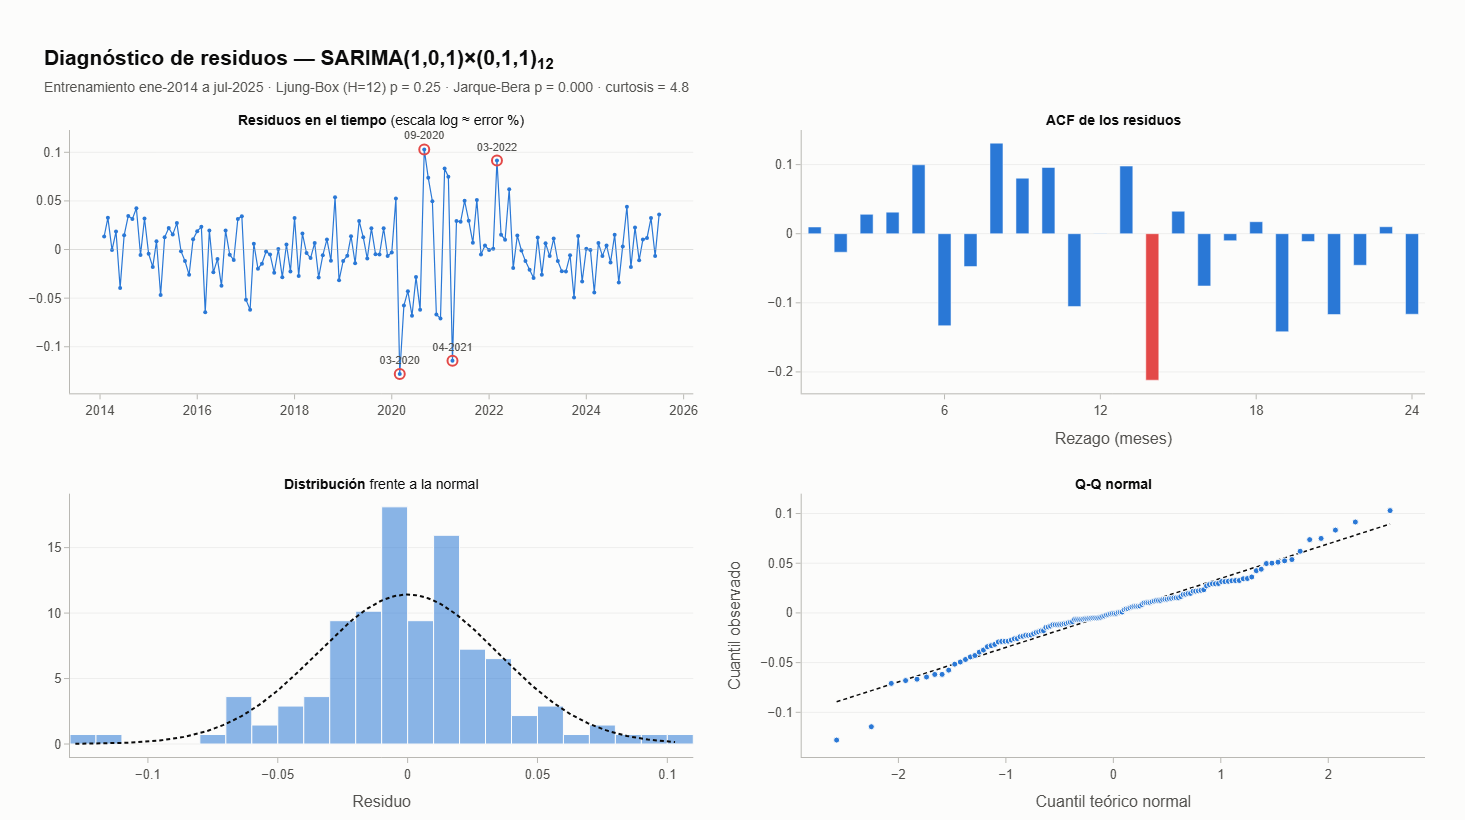

In [67]:
COL = MODELOS["SARIMA"][1]
fig = make_subplots(rows=2, cols=2, vertical_spacing=0.16, horizontal_spacing=0.08,
                    subplot_titles=("<b>Residuos en el tiempo</b> (escala log ≈ error %)",
                                    "<b>ACF de los residuos</b>",
                                    "<b>Distribución</b> frente a la normal",
                                    "<b>Q-Q normal</b>"))

# 1. Residuos en el tiempo, con banda de ±2 desviaciones y meses extremos marcados
banda = 2 * res_sar.std()
fig.add_hrect(y0=-banda, y1=banda, fillcolor=rgba(COL, 0.08), line_width=0, row=1, col=1)
fig.add_trace(go.Scatter(x=res_sar.index, y=res_sar, mode="lines+markers", line=dict(color=COL, width=1.2),
                         marker=dict(size=4, color=COL), hovertemplate="%{x|%b %Y}: %{y:.3f}<extra></extra>"), 1, 1)
fig.add_trace(go.Scatter(x=grandes.index, y=grandes, mode="markers+text", text=[f"{d:%m-%Y}" for d in grandes.index],
                         textposition="top center", textfont=dict(size=11, color=TINTA_2),
                         marker=dict(size=10, symbol="circle-open", color="#e34948", line=dict(width=2)),
                         hoverinfo="skip"), 1, 1)
fig.add_hline(y=0, line_color=GRIS, line_width=1, row=1, col=1)

# 2. ACF de los residuos (barras fuera de la banda en rojo)
r = acf(res_sar, nlags=24)[1:]
b = 1.96 / np.sqrt(len(res_sar))
fig.add_hrect(y0=-b, y1=b, fillcolor="rgba(0,0,0,0.07)", line_width=0, layer="below", row=1, col=2)
fig.add_trace(go.Bar(x=np.arange(1, 25), y=r, width=0.5,
                     marker_color=["#e34948" if abs(v) > b else COL for v in r],
                     hovertemplate="Rezago %{x}: %{y:.2f}<extra></extra>"), 1, 2)

# 3. Histograma frente a la densidad normal
fig.add_trace(go.Histogram(x=res_sar, histnorm="probability density", nbinsx=25,
                           marker=dict(color=rgba(COL, 0.55), line=dict(color=FONDO, width=1))), 2, 1)
xs = np.linspace(res_sar.min(), res_sar.max(), 200)
fig.add_trace(go.Scatter(x=xs, y=stats.norm.pdf(xs, res_sar.mean(), res_sar.std()), mode="lines",
                         line=dict(color=TINTA, width=2, dash="4px,3px"), hoverinfo="skip"), 2, 1)

# 4. Q-Q normal
(osm, osr), (pend, inter, _) = stats.probplot(res_sar, dist="norm")
fig.add_trace(go.Scatter(x=osm, y=pend * osm + inter, mode="lines", line=dict(color=TINTA, width=1.5, dash="4px,3px"),
                         hoverinfo="skip"), 2, 2)
fig.add_trace(go.Scatter(x=osm, y=osr, mode="markers", marker=dict(size=6, color=COL, line=dict(color=FONDO, width=1)),
                         hovertemplate="Teórico %{x:.2f}<br>Observado %{y:.3f}<extra></extra>"), 2, 2)

fig.update_layout(template="simple_white", width=1400, height=820, paper_bgcolor=FONDO, plot_bgcolor=FONDO,
                  font=dict(family="Arial", size=13, color=TINTA_2), showlegend=False,
                  title=dict(text="<b>Diagnóstico de residuos — SARIMA(1,0,1)×(0,1,1)<sub>12</sub></b>"
                                  f"<br><span style='font-size:14px;color:{TINTA_2}'>Entrenamiento ene-2014 a jul-2025 · "
                                  f"Ljung-Box (H=12) p = {lb_sar.loc[12, 'lb_pvalue']:.2f} · Jarque-Bera p = {jb_p:.3f} · "
                                  f"curtosis = {curt:.1f}</span>",
                             x=0.03, xanchor="left", font=dict(size=21, color=TINTA)),
                  margin=dict(l=70, r=40, t=130, b=60))
for a in fig.layout.annotations[:4]:
    a.update(font=dict(size=14, color=TINTA))
fig.update_xaxes(showgrid=False, linecolor=GRIS, tickcolor=GRIS)
fig.update_yaxes(showgrid=True, gridcolor="rgba(0,0,0,0.06)", zeroline=False, linecolor=GRIS, tickcolor=GRIS)
fig.update_xaxes(title_text="Rezago (meses)", dtick=6, row=1, col=2)
fig.update_xaxes(title_text="Residuo", row=2, col=1)
fig.update_xaxes(title_text="Cuantil teórico normal", row=2, col=2)
fig.update_yaxes(title_text="Cuantil observado", row=2, col=2)
guardar_figura(fig, "00_diagnostico_sarima")
fig.show()

### Lectura del diagnóstico de SARIMA

| Prueba | p-valor | Resultado | Qué significa para las ventas |
|---|---|---|---|
| Media = 0 | 0,99 | ✔ No se rechaza | El modelo **no tiene sesgo** dentro del entrenamiento: no sobreestima ni subestima sistemáticamente. |
| Ljung-Box H = 6, 12, 24 | 0,22 · 0,25 · 0,11 | ✔ No se rechaza | **Sin autocorrelación en los residuos**: el error de un mes no ayuda a predecir el del siguiente. El modelo capturó la dinámica de las ventas (persistencia del crecimiento, estacionalidad). |
| Jarque-Bera | < 0,001 | ✘ Se rechaza | Residuos **no normales**: asimetría leve (−0,28) pero **curtosis 4,8** (la normal tiene 3). Hay más meses con sorpresas grandes de lo que predice una normal. |
| ARCH-LM | < 0,001 | ✘ Se rechaza | **La varianza no es constante**: hay periodos con errores mucho más grandes que otros. |

**Lo que muestran las gráficas:**

- **Residuos en el tiempo:** oscilan dentro de ±5 % de 2014 a 2019 y de 2022 a 2025. La volatilidad se concentra en **2020–2021**: ese bloque explica tanto el rechazo de ARCH-LM como las colas del Q-Q. Los meses marcados son:
  - **mar-2020 (−13 %):** inicio del confinamiento (el 25 de marzo), que no está entre las intervenciones porque solo afectó la última semana del mes.
  - **sep-2020 (+10 %):** reapertura con demanda represada.
  - **abr-2021 (−11 %):** tercera ola de COVID con nuevas restricciones y la Semana Santa a comienzos de abril.
  - **mar-2022 (+9 %):** coincide con el día sin IVA del 11 de marzo de 2022.
- **ACF:** solo el rezago 14 sale levemente de la banda (−0,21). Con 24 rezagos se espera que uno se salga por azar, así que no indica estructura sin modelar.
- **Histograma y Q-Q:** el centro de la distribución es normal; las desviaciones están en las colas, por los meses de 2020–2022.

**Conclusión:** el modelo está **bien especificado en su dinámica**, que es lo central para pronosticar. Sus limitaciones son las colas pesadas y la varianza cambiante, ambas originadas en el periodo de pandemia. **Consecuencia práctica:** los intervalos del 95 % son razonables en tiempos normales, pero ante un choque como el de 2020 se quedarían cortos.

---
---

### Comportamiento de los errores de los cuatro modelos

Para comparar modelos con lógicas distintas, usamos el **error de ajuste dentro de muestra en porcentaje**:

$$
e_t = 100\cdot\frac{Y_t - \hat Y_t}{Y_t}
$$

donde $\hat Y_t$ es el valor ajustado de cada modelo en el entrenamiento (para el Naïve, $\hat Y_t = Y_{t-12}$). Revisamos el sesgo, la dispersión y la autocorrelación de los errores. Y en la prueba: **¿los modelos se equivocan juntos?**

In [68]:
ajustados = {
    "SARIMA": np.exp(mod_sarima.fittedvalues),
    "Holt-Winters": mod_hw.fittedvalues,
    "Prophet": pd.Series(mod_pro.predict(pd.DataFrame({"ds": train.index}))["yhat"].values, index=train.index),
    "Naïve estacional": train.shift(12),
}
err_pct = pd.DataFrame({n: 100 * (train - f) / train for n, f in ajustados.items()}).iloc[13:]   # mismo periodo
n_par = {"SARIMA": 3, "Holt-Winters": 4, "Prophet": 0, "Naïve estacional": 0}

resumen_err = pd.DataFrame({
    n: {"Error medio (%)": e.mean(), "Desv. estándar (%)": e.std(),
        "Error abs. medio (%)": e.abs().mean(),
        "Ljung-Box H=12 (p)": acorr_ljungbox(e, lags=[12], model_df=n_par[n])["lb_pvalue"].iloc[0],
        "Jarque-Bera (p)": jarque_bera(e)[1],
        "Error abs. medio sin 2020–21 (%)": e.drop(e["2020-03":"2021-06"].index).abs().mean()}
    for n, e in err_pct.items()}).T.loc[orden]
display(Markdown("**Errores de ajuste dentro de muestra (feb-2014 a jul-2025)**"))
display(resumen_err.round(3))

# ¿Los modelos se equivocan juntos en la prueba?
corr_test = pd.DataFrame({n: test - MODELOS[n][0]["pronostico"] for n in orden}).corr()
display(Markdown("**Correlación entre los errores de prueba de los modelos**"))
display(corr_test.style.format("{:.2f}").background_gradient(cmap="Greys", vmin=0, vmax=1))

**Errores de ajuste dentro de muestra (feb-2014 a jul-2025)**

,Error medio (%),Desv. estándar (%),Error abs. medio (%),Ljung-Box H=12 (p),Jarque-Bera (p),Error abs. medio sin 2020–21 (%)
SARIMA,-0.057,3.517,2.546,0.252,0.000,1.984
Holt-Winters,0.067,6.491,3.152,0.000,0.000,2.097
Prophet,-0.184,5.110,4.008,0.000,0.000,3.651
Naïve estacional,3.324,9.901,7.040,0.000,0.000,5.899


**Correlación entre los errores de prueba de los modelos**

,SARIMA,Holt-Winters,Prophet,Naïve estacional
SARIMA,1.00,0.99,0.98,0.22
Holt-Winters,0.99,1.00,0.96,0.24
Prophet,0.98,0.96,1.00,0.29
Naïve estacional,0.22,0.24,0.29,1.00


Guardada: reports\figures\00_errores_modelos.png


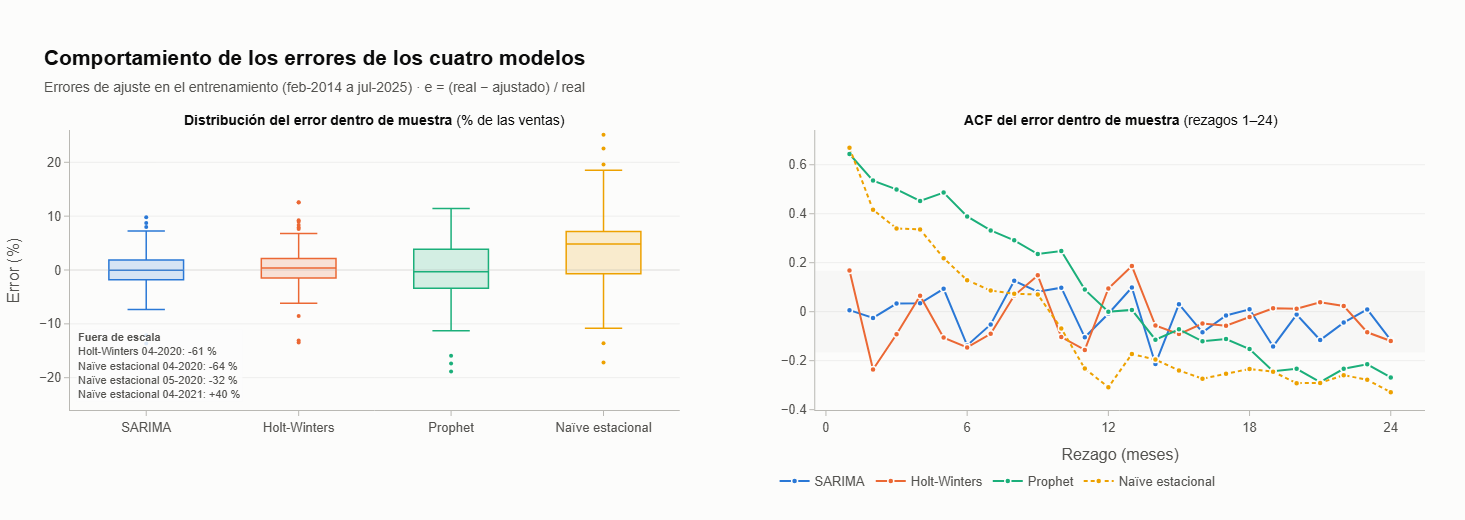

In [69]:
fig = make_subplots(rows=1, cols=2, column_widths=[0.5, 0.5], horizontal_spacing=0.1,
                    subplot_titles=("<b>Distribución del error dentro de muestra</b> (% de las ventas)",
                                    "<b>ACF del error dentro de muestra</b> (rezagos 1–24)"))
for n in orden:
    c = MODELOS[n][1]
    fig.add_trace(go.Box(y=err_pct[n], name=n, marker=dict(color=c, size=4), line=dict(color=c, width=1.5),
                         fillcolor=rgba(c, 0.18), boxpoints="outliers", showlegend=False,
                         hovertemplate=f"{n}<br>%{{y:.1f}} %<extra></extra>"), 1, 1)
    rr = acf(err_pct[n].dropna(), nlags=24)[1:]
    fig.add_trace(go.Scatter(x=np.arange(1, 25), y=rr, mode="lines+markers", name=n,
                             line=dict(color=c, width=2, dash="4px,3px" if n == REF else "solid"),
                             marker=dict(size=6, color=c, line=dict(color=FONDO, width=1.5)),
                             hovertemplate=f"{n}<br>Rezago %{{x}}: %{{y:.2f}}<extra></extra>"), 1, 2)
b = 1.96 / np.sqrt(len(err_pct))
fig.add_hrect(y0=-b, y1=b, fillcolor="rgba(0,0,0,0.07)", line_width=0, layer="below", row=1, col=2)

# Escala recortada a ±26 %: los errores extremos de 2020–2021 se listan en una nota
LIM = 26
fuera = [(d, n, err_pct.loc[d, n]) for d in err_pct.index for n in orden if abs(err_pct.loc[d, n]) > LIM]
nota = "<br>".join(f"{n} {d:%m-%Y}: {v:+.0f} %" for d, n, v in fuera)
fig.add_annotation(text=f"<b>Fuera de escala</b><br>{nota}", xref="x domain", yref="y domain", x=0.01, y=0.03,
                   xanchor="left", yanchor="bottom", align="left", showarrow=False,
                   font=dict(size=11, color=TINTA_2), bgcolor="rgba(252,252,251,0.85)", row=1, col=1)
fig.add_hline(y=0, line_color=GRIS, line_width=1, row=1, col=1)

fig.update_layout(template="simple_white", width=1400, height=520, paper_bgcolor=FONDO, plot_bgcolor=FONDO,
                  font=dict(family="Arial", size=13, color=TINTA_2),
                  title=dict(text="<b>Comportamiento de los errores de los cuatro modelos</b>"
                                  f"<br><span style='font-size:14px;color:{TINTA_2}'>Errores de ajuste en el entrenamiento "
                                  "(feb-2014 a jul-2025) · e = (real − ajustado) / real</span>",
                             x=0.03, xanchor="left", font=dict(size=21, color=TINTA)),
                  legend=dict(orientation="h", yanchor="top", y=-0.2, xanchor="left", x=0.52),
                  margin=dict(l=70, r=40, t=130, b=110))
for a in fig.layout.annotations[:2]:
    a.update(font=dict(size=14, color=TINTA))
fig.update_xaxes(showgrid=False, linecolor=GRIS, tickcolor=GRIS)
fig.update_xaxes(title_text="Rezago (meses)", dtick=6, row=1, col=2)
fig.update_yaxes(showgrid=True, gridcolor="rgba(0,0,0,0.06)", zeroline=False, linecolor=GRIS, tickcolor=GRIS)
fig.update_yaxes(title_text="Error (%)", range=[-LIM, LIM], row=1, col=1)
guardar_figura(fig, "00_errores_modelos")
fig.show()

### Lectura: comportamiento general de los errores

**1. Dentro del entrenamiento**

| Modelo | Error medio | Desv. estándar | Error abs. medio | Sin 2020–21 | Ljung-Box (p) |
|---|---|---|---|---|---|
| **SARIMA** | −0,06 % | **3,5 %** | **2,5 %** | **2,0 %** | **0,25** ✔ |
| Holt-Winters | +0,07 % | 6,5 % | 3,2 % | 2,1 % | < 0,001 ✘ |
| Prophet | −0,18 % | 5,1 % | 4,0 % | 3,7 % | < 0,001 ✘ |
| Naïve estacional | +3,3 % | 9,9 % | 7,0 % | 5,9 % | < 0,001 ✘ |

- **Sesgo:** SARIMA, Holt-Winters y Prophet no tienen sesgo dentro de la muestra (error medio ≈ 0). El Naïve subestima en promedio **3,3 %** cada mes: es exactamente el crecimiento anual promedio que ignora.
- **Dispersión:** SARIMA tiene los errores más concentrados (caja más angosta). La desviación de Holt-Winters (6,5 %) está inflada por un solo mes: **abril de 2020 (−61 %)**, porque no tiene intervenciones y el confinamiento le pega de lleno. SARIMA no muestra ese error porque la variable de intervención lo absorbe.
- **Sin el periodo 2020–2021**, SARIMA y Holt-Winters ajustan casi igual (2,0 % y 2,1 %). Su diferencia principal está en **cómo manejan los choques**.
- **Autocorrelación:** solo SARIMA deja errores sin estructura. En el gráfico de ACF:
  - **Prophet** tiene autocorrelaciones altas y persistentes (0,64 en el rezago 1, aún > 0,2 a 10 meses): su tendencia rígida deja **rachas** de meses consecutivos por encima o por debajo, lo que significa que no sigue los ciclos de consumo.
  - **El Naïve** tiene el mismo problema (0,67 en el rezago 1), y además autocorrelación negativa en el rezago 12, por el efecto de copiar el año anterior.
  - **Holt-Winters** queda más cerca de cero, pero con picos en los rezagos 2 y 13.

**2. En la prueba: los modelos se equivocan juntos**

Los errores de prueba de SARIMA, Holt-Winters y Prophet tienen una correlación de **0,96–0,99**: fallan en los mismos meses y en la misma dirección. No es un problema de un modelo en particular: los tres comparten la misma **causa común**, una aceleración del consumo en 2026 que no estaba en la historia de la serie. Los errores del Naïve se correlacionan poco con los demás (0,22–0,29) porque su falla tiene otro origen: copiar el año anterior.

**Implicación:** combinar estos modelos (promediarlos) **no reduciría mucho el error**, porque fallan igual. Para mejorar el pronóstico haría falta información **externa** a la serie: tasas de interés, inflación, confianza del consumidor o calendario (días sin IVA, Semana Santa).

**3. Conclusión del diagnóstico**

SARIMA es el modelo mejor especificado: residuos sin sesgo y sin autocorrelación, con la dispersión más baja. Sus limitaciones (colas pesadas y varianza no constante) vienen del periodo de pandemia y se reflejan en que sus intervalos pueden quedarse cortos ante choques extremos.

---
---

### __10. **Pronóstico final:** reajustar el modelo con mejor desempeño utilizando toda la información disponible hasta julio de 2026 y proyectar los siguientes 12 meses.__

## Pronóstico final: agosto 2026 a julio 2027

El modelo con mejor desempeño fue **SARIMA$(1,0,1)\times(0,1,1)_{12}$ + constante + intervenciones sobre $\log Y_t$**:

- menor error en la prueba en las cuatro métricas (MASE 0,76);
- menor MASE promedio en los 6 orígenes (0,61) y el único con MASE < 1 en todos;
- residuos sin autocorrelación ni sesgo;
- los intervalos más angostos sin perder cobertura.

Ahora lo **reestimamos con los 163 meses** (ene-2013 a jul-2026) y pronosticamos los 12 meses siguientes. Usar los datos de prueba aquí **no** es *data leakage*: la evaluación ya terminó y el objetivo es pronosticar el futuro con toda la información disponible.

**Cómo se construye el pronóstico:**

1. Se pronostica $\log Y_{T+h}$ para $h = 1, \dots, 12$, con las intervenciones en 0 (no se suponen choques futuros).
2. Los intervalos salen de la varianza del error a $h$ pasos, $\sigma_h^2 = \sigma_w^2\sum_{j=0}^{h-1}\psi_j^2$, que crece con el horizonte.
3. Todo se devuelve a la escala original con $\exp(\cdot)$. El punto central es la **mediana** del pronóstico.

In [70]:
X_full = matriz_intervencion(y.index)
mod_final = SARIMAX(np.log(y), exog=X_full, order=(1, 0, 1), seasonal_order=(0, 1, 1, 12),
                    trend="c").fit(disp=False, maxiter=500)

# ¿Cambian los coeficientes al agregar el último año? (estabilidad del modelo)
coef = pd.DataFrame({"Entrenamiento (hasta jul-2025)": mod_sarima.params,
                     "Completo (hasta jul-2026)": mod_final.params})
coef["Cambio"] = coef.iloc[:, 1] - coef.iloc[:, 0]
display(coef.round(4))

mu_tr = mod_sarima.params["intercept"] / (1 - mod_sarima.params["ar.L1"])
mu_fin = mod_final.params["intercept"] / (1 - mod_final.params["ar.L1"])
print(f"Crecimiento anual de largo plazo: {100 * (np.exp(mu_tr) - 1):.2f} % (entrenamiento) → "
      f"{100 * (np.exp(mu_fin) - 1):.2f} % (completo)")

lb_fin = acorr_ljungbox(mod_final.resid.iloc[13:], lags=[12, 24], model_df=3, return_df=True)
lb_fin.index.name = "Rezago H"
display(lb_fin.round(3))

,Entrenamiento (hasta jul-2025),Completo (hasta jul-2026),Cambio
intercept,0.005,0.005,0.000
I_2020-04,-0.454,-0.454,-0.001
I_2020-05,-0.193,-0.194,-0.001
I_2021-05,-0.157,-0.157,-0.001
ar.L1,0.871,0.873,0.002
ma.L1,-0.303,-0.285,0.018
ma.S.L12,-0.952,-0.958,-0.006
sigma2,0.001,0.001,-0.000


Crecimiento anual de largo plazo: 3.91 % (entrenamiento) → 4.10 % (completo)


,lb_stat,lb_pvalue
Rezago H,,
12,12.644,0.179
24,30.302,0.086


**Lectura:** al agregar el último año, todos los coeficientes cambian **menos de 0,02**: el modelo es **estable**. La persistencia del crecimiento sube levemente ($\phi_1$: 0,871 → 0,873) y el crecimiento de largo plazo pasa de **3,9 % a 4,1 % anual**, porque el último año creció con fuerza. Los residuos siguen sin autocorrelación (Ljung-Box $p = 0{,}18$ con $H = 12$ y $0{,}09$ con $H = 24$).

In [71]:
H = 12
idx_fut = pd.date_range(y.index[-1] + pd.offsets.MonthBegin(1), periods=H, freq="MS")
X_fut = matriz_intervencion(idx_fut)                     # todo en cero: no se suponen choques futuros

fc = mod_final.get_forecast(H, exog=X_fut)
ic95, ic80 = fc.conf_int(alpha=0.05), fc.conf_int(alpha=0.20)

final = pd.DataFrame({
    "Pronóstico": np.exp(fc.predicted_mean.values),
    "Inf 80 %": np.exp(ic80.iloc[:, 0].values), "Sup 80 %": np.exp(ic80.iloc[:, 1].values),
    "Inf 95 %": np.exp(ic95.iloc[:, 0].values), "Sup 95 %": np.exp(ic95.iloc[:, 1].values),
}, index=idx_fut)
final["Mismo mes año anterior"] = y.reindex(idx_fut - pd.DateOffset(years=1)).values
final["Variación anual (%)"] = 100 * (final["Pronóstico"] / final["Mismo mes año anterior"] - 1)

tabla = final.copy()
tabla.index = [etiqueta_mes(d).replace("<br>", "-") for d in tabla.index]
display(tabla.style.format("{:.1f}").format("{:+.1f}", subset=["Variación anual (%)"])
        .set_caption("Pronóstico del índice de ventas reales del comercio minorista (base 2019 = 100)"))

crec_12 = 100 * (final["Pronóstico"].mean() / y[-12:].mean() - 1)
print(f"Promedio próximos 12 meses: {final['Pronóstico'].mean():.1f} | últimos 12 observados: {y[-12:].mean():.1f} "
      f"→ {crec_12:+.1f} %")

final.to_csv(DIR_PROC / "pronostico_final.csv", index_label="fecha")

,Pronóstico,Inf 80 %,Sup 80 %,Inf 95 %,Sup 95 %,Mismo mes año anterior,Variación anual (%)
ago-2026,137.8,132.2,143.7,129.3,146.9,131.1,+5.2
sep-2026,134.4,128.0,141.0,124.8,144.7,126.1,+6.5
oct-2026,138.8,131.6,146.3,128.0,150.4,129.3,+7.3
nov-2026,144.1,136.3,152.4,132.3,156.9,138.6,+3.9
dic-2026,176.8,166.8,187.4,161.7,193.2,167.9,+5.3
ene-2027,132.1,124.5,140.3,120.6,144.8,128.1,+3.1
feb-2027,126.7,119.2,134.7,115.4,139.1,123.4,+2.7
mar-2027,135.6,127.5,144.3,123.3,149.1,136.3,-0.5
abr-2027,128.7,120.9,137.1,117.0,141.7,130.7,-1.5
may-2027,135.1,126.9,144.0,122.7,148.8,139.7,-3.3


Promedio próximos 12 meses: 138.5 | últimos 12 observados: 135.4 → +2.3 %


In [72]:
# El DANE ya publicó la versión ago-2026 del anexo: es el primer dato real fuera de muestra.

def leer_serie_dane(archivo, hoja="1.2", columna="Total comercio minorista sin otros vehículos"):
    """Misma limpieza del Paso 3, empaquetada para leer otra versión del anexo."""
    crudo = pd.read_excel(archivo, sheet_name=hoja, header=None)
    fila = crudo.index[crudo.apply(lambda f: f.astype(str).str.strip().eq("Año").any(), axis=1)][0]
    enc = crudo.loc[fila].astype(str).str.strip()
    d = crudo.loc[fila + 1:, [enc[enc == "Año"].index[0], enc[enc == "Mes"].index[0], enc[enc == columna].index[0]]].copy()
    d.columns = ["anio", "mes", "valor"]
    d["mes"] = d["mes"].astype(str).str.strip().str.lower()
    d = d[d["mes"].isin(MESES)]
    d["anio"] = pd.to_numeric(d["anio"], errors="coerce").ffill().astype(int)
    fechas = pd.to_datetime(dict(year=d["anio"], month=d["mes"].map(MESES), day=1))
    return pd.Series(pd.to_numeric(d["valor"]).values, index=fechas).asfreq("MS")

ARCHIVO_AGO = DIR_RAW / "anex-EMC-SeriesIndiceEmpalmados-ago2026.xlsx"
try:
    if not ARCHIVO_AGO.exists():
        r = requests.get(URL.replace(VINTAGE, "ago2026"), timeout=60, headers={"User-Agent": "Mozilla/5.0"})
        r.raise_for_status()
        ARCHIVO_AGO.write_bytes(r.content)
    y_ago = leer_serie_dane(ARCHIVO_AGO)
    REAL_AGO = float(y_ago["2026-08-01"])
    revision_jul = float(y_ago["2026-07-01"] - y["2026-07-01"])
except Exception as e:
    REAL_AGO, revision_jul = 138.4429, 0.0110                  # valores del anexo ago-2026 (respaldo sin conexión)
    print(f"Sin conexión al DANE ({type(e).__name__}); se usa el valor publicado de respaldo.")

f = final.loc["2026-08-01"]
print(f"Agosto 2026 → real: {REAL_AGO:.2f} | pronóstico: {f['Pronóstico']:.2f} | "
      f"error: {REAL_AGO - f['Pronóstico']:+.2f} puntos ({100 * (REAL_AGO / f['Pronóstico'] - 1):+.2f} %)")
print(f"¿Dentro del intervalo 95 % [{f['Inf 95 %']:.1f}, {f['Sup 95 %']:.1f}]? "
      f"{'Sí' if f['Inf 95 %'] <= REAL_AGO <= f['Sup 95 %'] else 'No'}")
print(f"Revisión del dato de julio 2026 entre versiones: {revision_jul:+.3f} puntos")

Agosto 2026 → real: 138.44 | pronóstico: 137.84 | error: +0.60 puntos (+0.44 %)
¿Dentro del intervalo 95 % [129.3, 146.9]? Sí
Revisión del dato de julio 2026 entre versiones: +0.011 puntos


Guardada: reports\figures\00_pronostico_final.png


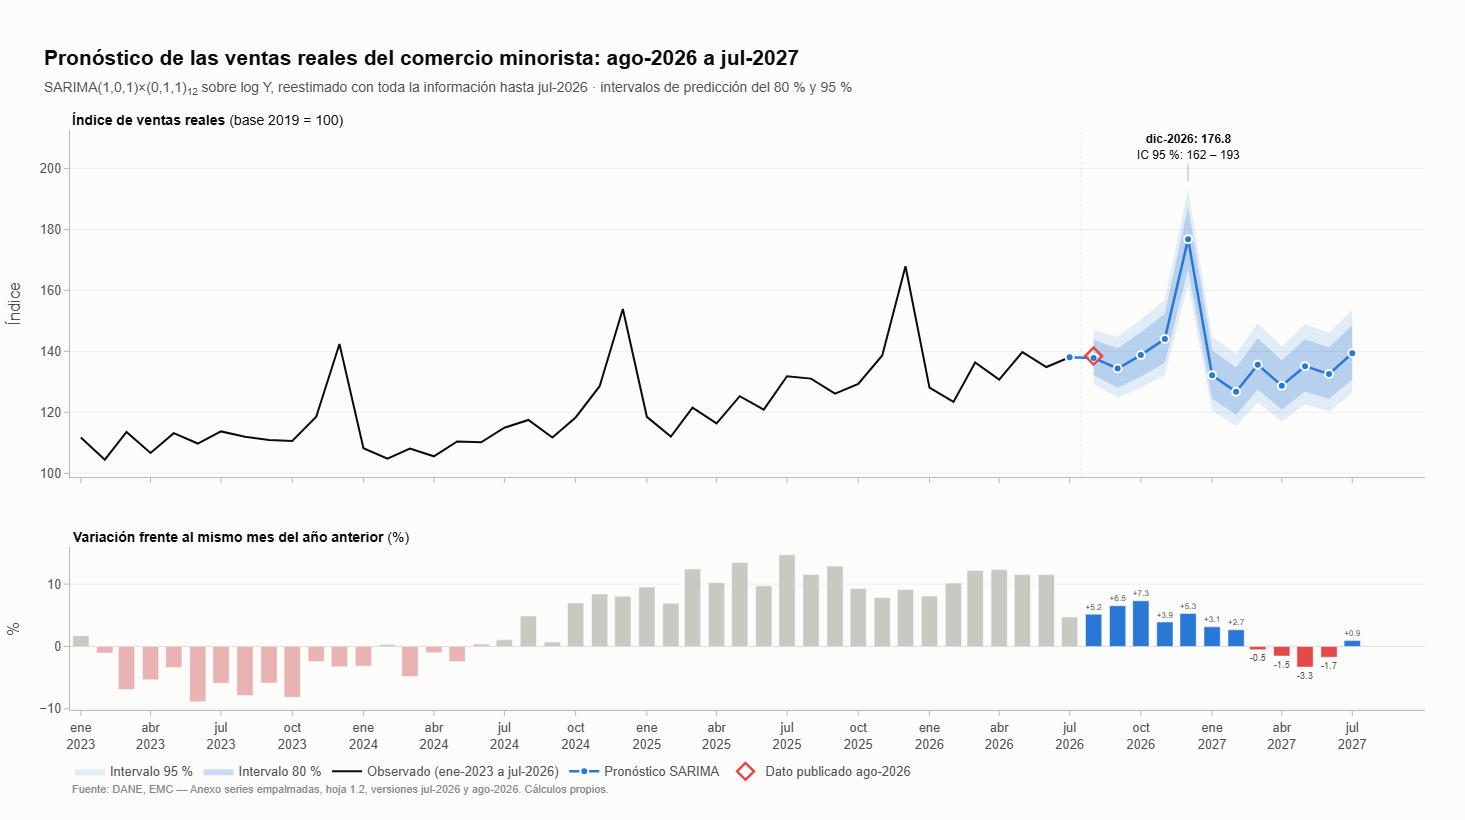

In [73]:
COL = MODELOS["SARIMA"][1]
hist = y["2023-01":]
fig = make_subplots(rows=2, cols=1, row_heights=[0.68, 0.32], vertical_spacing=0.12, shared_xaxes=True,
                    subplot_titles=("<b>Índice de ventas reales</b> (base 2019 = 100)",
                                    "<b>Variación frente al mismo mes del año anterior</b> (%)"))

# Abanico de intervalos (95 % claro, 80 % más oscuro)
x_band = list(idx_fut) + list(idx_fut[::-1])
fig.add_trace(go.Scatter(x=x_band, y=list(final["Sup 95 %"]) + list(final["Inf 95 %"][::-1]), fill="toself",
                         fillcolor=rgba(COL, 0.12), line=dict(width=0), name="Intervalo 95 %", hoverinfo="skip"), 1, 1)
fig.add_trace(go.Scatter(x=x_band, y=list(final["Sup 80 %"]) + list(final["Inf 80 %"][::-1]), fill="toself",
                         fillcolor=rgba(COL, 0.24), line=dict(width=0), name="Intervalo 80 %", hoverinfo="skip"), 1, 1)

# Historia observada y pronóstico
fig.add_trace(go.Scatter(x=hist.index, y=hist.values, mode="lines", name="Observado (ene-2023 a jul-2026)",
                         line=dict(color=TINTA, width=2), hovertemplate="%{x|%b %Y}: %{y:.1f}<extra></extra>"), 1, 1)
fig.add_trace(go.Scatter(x=[y.index[-1]] + list(idx_fut), y=[y.iloc[-1]] + list(final["Pronóstico"]),
                         mode="lines+markers", name="Pronóstico SARIMA",
                         line=dict(color=COL, width=2.5),
                         marker=dict(size=8, color=COL, line=dict(color=FONDO, width=2)),
                         customdata=np.r_[[[np.nan, np.nan]], final[["Inf 95 %", "Sup 95 %"]].values],
                         hovertemplate="%{x|%b %Y}: %{y:.1f}<br>IC 95 %: %{customdata[0]:.1f} – %{customdata[1]:.1f}<extra></extra>"), 1, 1)

# Primer dato real publicado después del pronóstico
fig.add_trace(go.Scatter(x=[pd.Timestamp("2026-08-01")], y=[REAL_AGO], mode="markers", name="Dato publicado ago-2026",
                         marker=dict(size=13, symbol="diamond-open", color="#e34948", line=dict(width=2.5)),
                         hovertemplate="Publicado ago-2026: %{y:.2f}<extra></extra>"), 1, 1)

# Anotación de diciembre
dic = pd.Timestamp("2026-12-01")
fig.add_annotation(x=dic, y=final.loc[dic, "Sup 95 %"], yshift=8, ax=0, ay=-34, showarrow=True, arrowhead=0,
                   arrowcolor=GRIS, text=f"<b>dic-2026: {final.loc[dic, 'Pronóstico']:.1f}</b><br>"
                                          f"IC 95 %: {final.loc[dic, 'Inf 95 %']:.0f} – {final.loc[dic, 'Sup 95 %']:.0f}",
                   font=dict(size=12, color=TINTA), bgcolor="rgba(252,252,251,0.9)", row=1, col=1)
fig.add_vline(x=y.index[-1] + pd.Timedelta(days=15), line_dash="dot", line_color=GRIS, line_width=1)

# Panel inferior: variación anual observada (gris) y pronosticada (color)
var_hist = 100 * (hist / y.shift(12)[hist.index] - 1)
fig.add_trace(go.Bar(x=hist.index, y=var_hist, marker_color=["#c9c8c3" if v >= 0 else "#e8b3b2" for v in var_hist],
                     showlegend=False, hovertemplate="%{x|%b %Y}: %{y:+.1f} %<extra></extra>"), 2, 1)
fig.add_trace(go.Bar(x=idx_fut, y=final["Variación anual (%)"],
                     marker_color=[COL if v >= 0 else "#e34948" for v in final["Variación anual (%)"]],
                     text=[f"{v:+.1f}" for v in final["Variación anual (%)"]], textposition="outside",
                     textfont=dict(size=11, color=TINTA_2), cliponaxis=False, showlegend=False,
                     hovertemplate="%{x|%b %Y}: %{y:+.1f} %<extra></extra>"), 2, 1)
fig.add_hline(y=0, line_color=GRIS, line_width=1, row=2, col=1)

ticks = pd.date_range("2023-01-01", idx_fut[-1], freq="3MS")
fig.update_xaxes(tickvals=ticks, ticktext=[etiqueta_mes(d) for d in ticks], showgrid=False, linecolor=GRIS, tickcolor=GRIS)
fig.update_yaxes(showgrid=True, gridcolor="rgba(0,0,0,0.06)", zeroline=False, linecolor=GRIS, tickcolor=GRIS)
fig.update_yaxes(title_text="Índice", row=1, col=1)
fig.update_yaxes(title_text="%", row=2, col=1)
fig.update_layout(template="simple_white", width=1400, height=820, paper_bgcolor=FONDO, plot_bgcolor=FONDO,
                  font=dict(family="Arial", size=13, color=TINTA_2), bargap=0.25,
                  title=dict(text="<b>Pronóstico de las ventas reales del comercio minorista: ago-2026 a jul-2027</b>"
                                  f"<br><span style='font-size:14px;color:{TINTA_2}'>SARIMA(1,0,1)×(0,1,1)<sub>12</sub> sobre log Y, "
                                  "reestimado con toda la información hasta jul-2026 · intervalos de predicción del 80 % y 95 %</span>",
                             x=0.03, xanchor="left", font=dict(size=21, color=TINTA)),
                  legend=dict(orientation="h", yanchor="top", y=-0.08, xanchor="left", x=0),
                  margin=dict(l=70, r=40, t=130, b=110))
for a in fig.layout.annotations[:2]:
    a.update(x=0, xanchor="left", font=dict(size=14, color=TINTA))
fig.add_annotation(text="Fuente: DANE, EMC — Anexo series empalmadas, hoja 1.2, versiones jul-2026 y ago-2026. Cálculos propios.",
                   xref="paper", yref="paper", x=0, y=-0.15, showarrow=False, xanchor="left",
                   font=dict(size=11, color="#8a8984"))
guardar_figura(fig, "00_pronostico_final")
fig.show()

---

### Lectura del pronóstico

**1. Diciembre de 2026, el mes que más interesa al comercio**

| | Índice | Frente a dic-2025 |
|---|---|---|
| Pronóstico central | **176,8** | **+5,3 %** |
| Intervalo del 80 % | 166,8 – 187,4 | −0,7 % a +11,6 % |
| Intervalo del 95 % | 161,7 – 193,2 | −3,7 % a +15,1 % |

Se espera una temporada de fin de año **más fuerte que la de 2025**, con un crecimiento real cercano al 5 %. Para un comerciante:

- **Referencia de compra:** el valor central (≈ 5 % más volumen que el año pasado).
- **Margen de seguridad:** si quedarse sin inventario cuesta más que sobrar, conviene planear hacia el límite superior del 80 % (≈ +11,6 %).
- **Riesgo a la baja:** el límite inferior del 80 % queda prácticamente en el nivel de diciembre de 2025 (−0,7 %): una temporada por debajo de la anterior es poco probable, aunque no descartable.

**2. El perfil del año tiene dos tramos (panel inferior)**

- **Ago-2026 a feb-2027: crecimiento anual de +3 % a +7 %, que se modera.** El modelo arranca con la persistencia del crecimiento reciente ($\phi_1 \approx 0{,}87$) y lo hace converger poco a poco a su media de largo plazo (~4 %).
- **Mar a jul-2027: variaciones cercanas a cero o levemente negativas (−3,3 % a +0,9 %).** **No es un pronóstico de recesión.** Con $\Theta_1 \approx -0{,}96$, el modelo interpreta las ventas excepcionalmente altas de mar–jun 2026 (las que subestimó en la prueba) como **sorpresas transitorias** que no se repiten el mismo mes del año siguiente. Por eso compara contra una base alta y muestra crecimiento casi nulo. Si esa aceleración resulta **persistente**, el pronóstico de este tramo se quedará corto.

En promedio, los próximos 12 meses quedan **≈ 2,3 % por encima** de los últimos 12 observados.

**3. La incertidumbre crece con el horizonte**

El abanico se abre de ±6 % a un mes a ±10 % a doce meses (95 %). Es más angosto que el de Holt-Winters o el Naïve porque las intervenciones sacan 2020–2021 de la varianza. Aun así, como mostró el diagnóstico (curtosis 4,8), ante un choque extremo como el de 2020 **ningún intervalo construido con la historia lo cubriría**.

**4. Primera verificación real: agosto de 2026**

El DANE ya publicó el dato de agosto de 2026: **138,44**, frente a un pronóstico de **137,84**. Error de **+0,60 puntos (0,44 %)**, dentro del intervalo. Un solo mes no valida un modelo, pero confirma que el pronóstico **arranca en el nivel correcto**. Además, el dato de julio de 2026 apenas se revisó (+0,01 puntos) entre versiones, así que trabajar con la versión de julio no introduce sesgo.

**5. Límites del pronóstico**

- **Univariado:** solo usa la historia de las ventas. No ve tasas de interés, inflación, empleo ni confianza del consumidor, que son las variables que explican cambios de ritmo como la aceleración de 2026.
- **Calendario:** no incluye Semana Santa (que en **2027 cae en marzo**), festivos ni días sin IVA. Marzo y abril de 2027 pueden quedar desplazados.
- **Datos provisionales:** el DANE revisa las cifras recientes cada mes.

**Recomendación:** usar el pronóstico con su intervalo, no solo el valor central, y **actualizarlo cada mes** con la nueva publicación del DANE.